# Kaggle Competition: Facial Feature Classification Challenge

This notebook runs on the laptop only; ResNet-18 was trained on a Kaggle GPU in `kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb`, which copies this notebook's pipeline functions (the dataset classes, training, evaluation and prediction functions and the ResNet-18 helpers), so a change to those functions must be made in both notebooks.

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

# This notebook only runs on the laptop (GPU training is in kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb)
if Path("/kaggle/input").exists():
    raise RuntimeError("kaggle_comp.ipynb runs on the laptop only; use kaggle_resnet18_baseline_notebook.ipynb for GPU training on Kaggle")

data_folder = Path("../enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch")  # Competition data folder (relative to this notebook)

images_info_csv_path = Path("images_info.csv")                              # Created by the image analysis below
sharpness_csv_path = Path("image_sharpness.csv")                            # Created in section 1.6 (saved so it only runs once)
train_split_csv_path = Path("splits") / "train_split.csv"                   # Created in section 2.2
validation_split_csv_path = Path("splits") / "validation_split.csv"
baseline_history_csv_path = Path("results") / "baseline_cnn_history.csv"    # Created in section 3.5
baseline_weights_path = Path("models") / "baseline_cnn_best.pt"             # Best weights saved by the training run in 3.5

training_images_folder = data_folder / "train" / "train"                    # Training images folder path
testing_images_folder = data_folder / "test" / "test"                       # Testing images folder path

sample_submission_csv_path = data_folder / "sample_submission.csv"          # Sample submission CSV file path
train_labels_csv_path = data_folder / "train_labels.csv"                    # Training labels CSV file path

df_sample_submission = pd.read_csv(sample_submission_csv_path)  # Load sample submission CSV into a DataFrame
df_train_labels = pd.read_csv(train_labels_csv_path)            # Load training labels CSV into a DataFrame

### Run options

What "Run All" recomputes. With every option `False`, results that were saved before are loaded instead of being made again, so Run All takes minutes instead of hours. Set an option to `True` only to redo that step on purpose; it overwrites the saved file.

In [3]:
RESCAN_IMAGES = False      # True = analyse all 93,103 images again and overwrite images_info.csv (several minutes)
REMAKE_SPLIT = False       # True = make the training/validation split again and overwrite the split CSVs (the fixed seed gives the same split)
RETRAIN_BASELINE = False   # True = train the baseline CNN again for 10 epochs (about 2 hours on the laptop CPU) and overwrite its weights and history

print("RESCAN_IMAGES:   ", RESCAN_IMAGES)
print("REMAKE_SPLIT:    ", REMAKE_SPLIT)
print("RETRAIN_BASELINE:", RETRAIN_BASELINE)

RESCAN_IMAGES:    False
REMAKE_SPLIT:     False
RETRAIN_BASELINE: False


## Image Analysis

Collect per-image information for every image in the train and test folders (file size, dimensions, pixel count, colour mode, brightness/colour statistics, duplicates) and save it to `images_info.csv`. Scanning every image takes several minutes, so if `images_info.csv` already exists it is loaded instead (set `RESCAN_IMAGES = True` in the Run options to scan again).

In [4]:
import hashlib
from PIL import Image

# images_info_csv_path is set in the first code cell


def get_image_info(image_path, split):
    """Return a dictionary of information about one image."""
    file_bytes = image_path.read_bytes()

    info = {}
    info["split"] = split                                       # "train" or "test"
    info["image_id"] = int(image_path.stem)                     # "00001.jpg" -> 1 (matches the CSV files)
    info["file_name"] = image_path.name
    info["file_size_bytes"] = len(file_bytes)
    info["file_size_kb"] = round(len(file_bytes) / 1024, 3)
    info["md5_hash"] = hashlib.md5(file_bytes).hexdigest()      # Identical files have identical hashes

    try:
        image = Image.open(image_path)
        info["format"] = image.format                           # e.g. JPEG
        info["mode"] = image.mode                               # e.g. RGB, L (greyscale)
        info["width"] = image.width
        info["height"] = image.height
        info["channels"] = len(image.getbands())                # Number of color channels

        # Convert the image to a NumPy array and calculate brightness and color statistics
        # Pixel values as a height x width x 3 array (red, green, blue), each 0 to 255
        pixels = np.array(image.convert("RGB"), dtype=np.float32)   
        red = pixels[:, :, 0]
        green = pixels[:, :, 1]
        blue = pixels[:, :, 2]
        grey = (red + green + blue) / 3

        info["mean_brightness"] = round(float(grey.mean()), 3)  # 0 (black) to 255 (white)
        info["std_brightness"] = round(float(grey.std()), 3)    # Contrast
        info["min_pixel"] = int(pixels.min())                   # Minimum pixel value (0 to 255)
        info["max_pixel"] = int(pixels.max())                   # Maximum pixel value (0 to 255)    
        info["mean_red"] = round(float(red.mean()), 3)
        info["mean_green"] = round(float(green.mean()), 3)
        info["mean_blue"] = round(float(blue.mean()), 3)

        # A greyscale image stored as RGB has the same values in all three channels
        same_red_green = np.array_equal(red, green)                     # bool (true if all pixels are the saem in both channels)
        same_green_blue = np.array_equal(green, blue)
        info["is_greyscale"] = bool(same_red_green and same_green_blue) # True if all three channels have the same values

        # By default, images are assumed to be valid. If an exception is found, the image is corrupt.
        info["is_corrupt"] = False
        image.close()
    except Exception:
        info["is_corrupt"] = True

    return info


# Look up a training image's class from its ID
class_of_image = {}
for image_id, class_name in zip(df_train_labels["image_id"], df_train_labels["class"]):
    class_of_image[int(image_id)] = class_name

if images_info_csv_path.exists() and not RESCAN_IMAGES:
    # The table was saved before: load it instead of analysing all 93,103 images again
    df_images_info = pd.read_csv(images_info_csv_path, dtype={"class": "string"})   # "class" is empty for test images
    print(f"Loaded {len(df_images_info)} rows from {images_info_csv_path} (set RESCAN_IMAGES = True to scan the images again)")
else:
    # Collect information for every train and test image
    image_records = []
    for split in ["train", "test"]:                                     # Loop over the two splits of the dataset
        if split == "train":
            folder = training_images_folder
        else:
            folder = testing_images_folder

        image_paths = sorted(folder.glob("*.jpg"))                      # Get a list of all JPG files in the folder, sorted by name (therefore it goes 00001.jpg, 00002.jpg, 00003.jpg, etc.)
        print(f"Analysing {len(image_paths)} {split} images...")        # log the number of images being analysed

        for image_path in image_paths:
            info = get_image_info(image_path, split)
            if split == "train":
                info["class"] = class_of_image[info["image_id"]]        # label train split images with their class (cat or dog)
            else:
                info["class"] = None                                    # Test images have no label
            image_records.append(info)                                  # Add the image's info to the list of records

    df_images_info = pd.DataFrame(image_records)                        # Create a DataFrame from the list of image info dictionaries

    # Extra columns worked out from the ones above
    df_images_info["total_pixels"] = df_images_info["width"] * df_images_info["height"]
    df_images_info["aspect_ratio"] = (df_images_info["width"] / df_images_info["height"]).round(3)   # Width / height
    df_images_info["short_side"] = df_images_info[["width", "height"]].min(axis=1)                   # Length of the shorter side, in pixels
    df_images_info["is_duplicate"] = df_images_info.duplicated("md5_hash", keep=False)               # True for every copy of a repeated file

    column_order = [                                                                                 # Reorder the columns for easier reading
        "split", "image_id", "file_name", "class", "format", "mode", "channels",
        "width", "height", "total_pixels", "aspect_ratio", "short_side", "file_size_bytes", "file_size_kb",
        "mean_brightness", "std_brightness", "min_pixel", "max_pixel",
        "mean_red", "mean_green", "mean_blue", "is_greyscale", "is_corrupt", "is_duplicate", "md5_hash",
    ]
    df_images_info = df_images_info[column_order]
    df_images_info.to_csv(images_info_csv_path, index=False)
    print(f"Saved {len(df_images_info)} rows to {images_info_csv_path}")

Loaded 93103 rows from images_info.csv (set RESCAN_IMAGES = True to scan the images again)


Quick summary of the scan.

In [5]:
print("Images per split:")
print(df_images_info["split"].value_counts())
print()
print("Colour modes:")
print(df_images_info["mode"].value_counts())
print()
print("Greyscale images:", df_images_info["is_greyscale"].sum())
print("Corrupt images:  ", df_images_info["is_corrupt"].sum())
print("Duplicate images:", df_images_info["is_duplicate"].sum())

Images per split:
split
train    63660
test     29443
Name: count, dtype: int64

Colour modes:
mode
RGB    93103
Name: count, dtype: int64

Greyscale images: 1434
Corrupt images:   0
Duplicate images: 154


## Task 1: Dataset Exploration and Understanding

### Settings and data used in this section

In [6]:
import math
import matplotlib.pyplot as plt
from PIL import Image

# Folder and CSV paths 
figures_folder = Path("figures")                  # Folder to store all figures and plots generated in this notebook
figures_folder.mkdir(exist_ok=True)               # Create the folder if it doesn't exist yet
results_folder = Path("results")                  # Folder for the tables and results (CSV files) made in this notebook
results_folder.mkdir(exist_ok=True)               # Create the folder if it doesn't exist yet
# images_info_csv_path and sharpness_csv_path are set in the first code cell

# Global Settings - Define constants for reproducibility and image analysis
RANDOM_SEED = 42                                  # Same seed = same random sample images every run
SMALL_IMAGE_SIZE = 32                             # Images with a shorter side below this (pixels) count as "small"
BLUR_THRESHOLD = 20                               # Images with sharpness below this count as "blurry"

CLASSES = ["CatEye", "CatFace", "CatMouth", "CatNose", "DogEye", "DogFace", "DogMouth", "DogNose"]
PARTS = ["Eye", "Face", "Mouth", "Nose"]
CAT_COLOUR = "#4C72B0"                            # Blue
DOG_COLOUR = "#DD8452"                            # Orange

# Load image information as a dataframe
df_info = pd.read_csv(images_info_csv_path, dtype={"class": "string"})   # "class" is empty for test images

# individual dataframes for train and test splits
df_train_info = df_info[df_info["split"] == "train"]
df_test_info = df_info[df_info["split"] == "test"]

# Print the number of training and test images
print("Training images:", len(df_train_info))
print("Test images:    ", len(df_test_info))

print("Training images")
display(df_train_info)

print("Test images")
display(df_test_info)

Training images: 63660
Test images:     29443
Training images


,split,image_id,file_name,class,format,mode,channels,width,height,total_pixels,...,std_brightness,min_pixel,max_pixel,mean_red,mean_green,mean_blue,is_greyscale,is_corrupt,is_duplicate,md5_hash
0,train,1,00001.jpg,DogEye,JPEG,RGB,3,36,36,1296,...,39.430,0,236,118.787,121.071,135.931,False,False,False,005e6966847edf1c67cb69dc54ab2d8f
1,train,2,00002.jpg,DogMouth,JPEG,RGB,3,214,157,33598,...,66.703,0,255,140.455,126.462,104.217,False,False,False,0db24ae499fa38d176c4db7bd5c050ce
2,train,3,00003.jpg,DogFace,JPEG,RGB,3,97,97,9409,...,67.946,0,255,146.143,118.291,95.413,False,False,False,d97191734c94207ca601a35508ec7174
3,train,4,00004.jpg,DogNose,JPEG,RGB,3,110,110,12100,...,48.471,0,233,104.057,98.559,87.784,False,False,False,5aeb640a2b5d4ee4a9d6b02acb501329
4,train,5,00005.jpg,DogNose,JPEG,RGB,3,42,42,1764,...,24.338,9,180,88.770,84.960,101.673,False,False,False,342155bcc74eb7507ffd6dfc61e8da48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63655,train,63656,63656.jpg,CatEye,JPEG,RGB,3,24,24,576,...,24.455,0,187,64.128,68.220,72.830,False,False,False,a8c0e2b26469f1412c6e163ca7952568
63656,train,63657,63657.jpg,DogMouth,JPEG,RGB,3,70,52,3640,...,51.162,6,199,133.837,127.879,122.508,False,False,False,1c0a183c35b874db7d6813daecaf323e
63657,train,63658,63658.jpg,DogEye,JPEG,RGB,3,36,36,1296,...,32.986,0,255,42.245,44.748,36.311,False,False,False,75dab4924e0e07ad40e607d430e4f2ab
63658,train,63659,63659.jpg,DogMouth,JPEG,RGB,3,170,125,21250,...,32.882,27,184,114.201,112.905,110.079,False,False,False,1e9871919ea71cce0764530466fad275


Test images


,split,image_id,file_name,class,format,mode,channels,width,height,total_pixels,...,std_brightness,min_pixel,max_pixel,mean_red,mean_green,mean_blue,is_greyscale,is_corrupt,is_duplicate,md5_hash
63660,test,1,00001.jpg,<NA>,JPEG,RGB,3,112,112,12544,...,27.806,16,187,76.179,66.201,69.405,False,False,False,e0e6929328e664c05c247a28428b795c
63661,test,2,00002.jpg,<NA>,JPEG,RGB,3,96,69,6624,...,45.589,0,255,162.046,118.128,60.289,False,False,False,98d19b14615f85d63b2f167374be6dee
63662,test,3,00003.jpg,<NA>,JPEG,RGB,3,34,34,1156,...,23.827,0,178,51.685,50.140,52.231,False,False,False,25b4231809e70ad5b1dc8e8ab4bfbaea
63663,test,4,00004.jpg,<NA>,JPEG,RGB,3,119,119,14161,...,67.064,0,255,112.816,105.563,102.131,False,False,False,fb8e404d9d50d45070f8add0545e4d65
63664,test,5,00005.jpg,<NA>,JPEG,RGB,3,210,140,29400,...,85.674,0,255,95.460,94.706,97.022,False,False,False,1f345225fc5560627ac753fc519255c9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93098,test,29439,29439.jpg,<NA>,JPEG,RGB,3,30,20,600,...,42.386,0,255,66.228,37.542,20.112,False,False,True,352a41b1efa27813ed6d18ed06c2764b
93099,test,29440,29440.jpg,<NA>,JPEG,RGB,3,75,60,4500,...,75.000,0,242,143.183,127.280,79.916,False,False,False,cf3cacff1c56bd620106bcb1f250e21d
93100,test,29441,29441.jpg,<NA>,JPEG,RGB,3,206,205,42230,...,94.725,0,255,112.005,113.212,116.274,False,False,False,ea3c253c485d0e0cd00d457b33aa485f
93101,test,29442,29442.jpg,<NA>,JPEG,RGB,3,1260,1190,1499400,...,41.911,0,255,100.757,75.703,64.006,False,False,False,1ef7822f85f24dc1639900410efbc3fe


Two helper functions used to show and save grids of images.

In [7]:
def get_image_path(split, file_name):
    """Return the full path of an image."""
    if split == "train":
        return training_images_folder / file_name
    else:
        return testing_images_folder / file_name


def show_images(df_rows, captions, n_columns, title, save_name):
    """Show one image per row of df_rows in a grid, with a caption under each, and save the figure."""
    n_images = len(df_rows)
    n_rows = math.ceil(n_images / n_columns)
    plt.figure(figsize=(n_columns * 1.6, n_rows * 1.95))

    for i in range(n_images):
        row = df_rows.iloc[i]
        image = Image.open(get_image_path(row["split"], row["file_name"])).convert("RGB")

        plt.subplot(n_rows, n_columns, i + 1)     # Grid positions start at 1
        plt.imshow(image)
        plt.title(captions[i], fontsize=7)
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(figures_folder / save_name, dpi=150, bbox_inches="tight")
    plt.show()

### 1.2 Structure of the training and test data

Check that the files on disk match the CSV files.

In [8]:
# Get a list of all JPG files in the relevant folder
train_files = list(training_images_folder.glob("*.jpg")) 
test_files = list(testing_images_folder.glob("*.jpg"))              

# Print the number of images found on disk and the number of rows in the CSV files to compare
print("Image Quantity Checks:")
print("Training images on disk:      ", len(train_files))          
print("Test images on disk:          ", len(test_files))   
print("Rows in train_labels.csv:     ", len(df_train_labels))
print("Rows in sample_submission.csv:", len(df_sample_submission))

# Turn file names into IDs: "00001.jpg" -> 1
train_ids_on_disk = set()
for path in train_files:
    train_ids_on_disk.add(int(path.stem))

test_ids_on_disk = set()
for path in test_files:
    test_ids_on_disk.add(int(path.stem))

labelled_ids = set(df_train_labels["image_id"].astype(int))                                     # set of image IDs that have labels in train_labels.csv
submission_ids = set(df_sample_submission["image_id"].astype(int))                              # set of image IDs that are listed in the sample submission

# Check that the image IDs in the CSV files match the image IDs on disk
print("\nImage ID checks:")
print("Every training image has a label:        ", train_ids_on_disk == labelled_ids)         # Check if all training images have labels
print("Sample submission lists every test image:", test_ids_on_disk == submission_ids)          # Check if the sample submission lists all test images
print("Missing labels:                          ", df_train_labels["class"].isna().sum())       # Count missing labels
print("IDs used in both train and test:         ", len(train_ids_on_disk & test_ids_on_disk))   # image IDs that are used in both the training and test sets
print("Label values:", sorted(df_train_labels["class"].unique()))

# looking at the image types and colour modes in the dataset
print("\nImage type:")
print("Image formats:", df_info["format"].value_counts().to_dict())
print("Colour modes: ", df_info["mode"].value_counts().to_dict())

# Examine the first few rows of the CSV files to check their structure and contents
print("\nFirst rows of train_labels.csv:")
print(df_train_labels.head())

# Same as above, but for sample_submission.csv
print("\nFirst rows of sample_submission.csv:")
print(df_sample_submission.head())

Image Quantity Checks:
Training images on disk:       63660
Test images on disk:           29443
Rows in train_labels.csv:      63660
Rows in sample_submission.csv: 29443

Image ID checks:
Every training image has a label:         True
Sample submission lists every test image: True
Missing labels:                           0
IDs used in both train and test:          29443
Label values: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

Image type:
Image formats: {'JPEG': 93103}
Colour modes:  {'RGB': 93103}

First rows of train_labels.csv:
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogFace
3         4   DogNose
4         5   DogNose

First rows of sample_submission.csv:
   image_id     class
0         1    DogEye
1         2   CatNose
2         3   CatNose
3         4   DogFace
4         5  DogMouth


### 1.3 Number of images per class

In [9]:
total_train = len(df_train_info)        # Create a variable to hold the total number of training images for later calculations

# Count the images in each class
class_counts = {}
for class_name in CLASSES:
    class_counts[class_name] = int((df_train_info["class"] == class_name).sum())

# Output the counts and percentages of each class in a formatted table
print(f"{'Class':<10} {'Images':>7} {'Percent':>8}")
for class_name in CLASSES:
    count = class_counts[class_name]
    percent = count / total_train * 100
    print(f"{class_name:<10} {count:>7} {percent:>7.1f}%")

# Counting total number of images for cats and dogs
cat_total = 0
dog_total = 0
for class_name in CLASSES:                      # For each class, add its count to either the cat or dog total
    if class_name.startswith("Cat"):
        cat_total += class_counts[class_name]
    else:
        dog_total += class_counts[class_name]
print("\nTotal number of images for cats and dogs:")
print(f"Cat images: {cat_total} ({cat_total / total_train * 100:.1f}%)")   # Print total number of cats as number and percentage
print(f"Dog images: {dog_total} ({dog_total / total_train * 100:.1f}%)")   # Print total number of dogs as number and percentage

# Largest and smallest class counts
Largest_class = max(class_counts, key=class_counts.get)  # Get the largest class name with the largest count
Smallest_class = min(class_counts, key=class_counts.get)  # Get the smallest class name with the smallest count
largest = class_counts[Largest_class]
smallest = class_counts[Smallest_class]
print("\nLargest class / smallest class:")
print(f"{Largest_class} / {Smallest_class}:  {largest / smallest:.2f}")

Class       Images  Percent
CatEye       13884    21.8%
CatFace       6942    10.9%
CatMouth      6942    10.9%
CatNose       6942    10.9%
DogEye       11580    18.2%
DogFace       5790     9.1%
DogMouth      5790     9.1%
DogNose       5790     9.1%

Total number of images for cats and dogs:
Cat images: 34710 (54.5%)
Dog images: 28950 (45.5%)

Largest class / smallest class:
CatEye / DogFace:  2.40


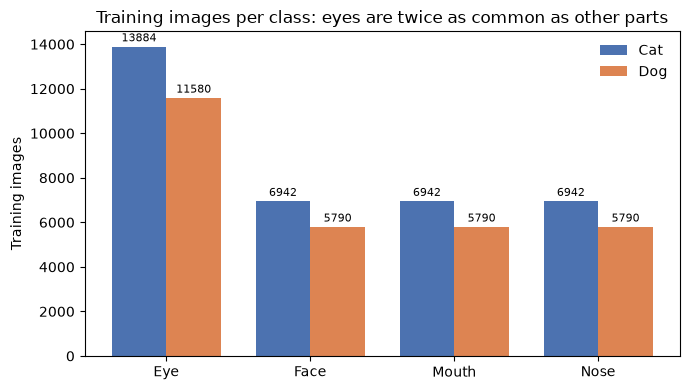

In [10]:
# Bar chart: one group of bars per facial part, cat and dog side by side
cat_counts = []                                         # Number of cat images for each part, in the same order as PARTS
dog_counts = []                                         # Number of dog images for each part, in the same order as PARTS
for part in PARTS:
    cat_counts.append(class_counts["Cat" + part])       # e.g. "Cat" + "Eye" -> "CatEye"
    dog_counts.append(class_counts["Dog" + part])

x_positions = np.arange(len(PARTS))   # 0, 1, 2, 3
bar_width = 0.38                                        # Width of each bar, so a cat bar and a dog bar fit side by side in each group

# Draw the cat bars just left of each x position and the dog bars just right of it
fig, ax = plt.subplots(figsize=(7, 4))
cat_bars = ax.bar(x_positions - bar_width / 2, cat_counts, bar_width, label="Cat", color=CAT_COLOUR)
dog_bars = ax.bar(x_positions + bar_width / 2, dog_counts, bar_width, label="Dog", color=DOG_COLOUR)
ax.bar_label(cat_bars, fontsize=8, padding=2)   # Write the count above each bar
ax.bar_label(dog_bars, fontsize=8, padding=2)

# Axis labels, title and legend
ax.set_xticks(x_positions)                              # One tick under the middle of each group of bars
ax.set_xticklabels(PARTS)                               # Label each tick with its facial part
ax.set_ylabel("Training images")
ax.set_title("Training images per class: eyes are twice as common as other parts")
ax.legend(frameon=False)                                # Legend without a border
plt.tight_layout()                                      # Stop the labels overlapping
plt.savefig(figures_folder / "class_distribution.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

### 1.4 Representative sample images from each class

Six random images per class (fixed seed). Every tile is shown at the same display size, so the caption gives the image's real size in pixels.

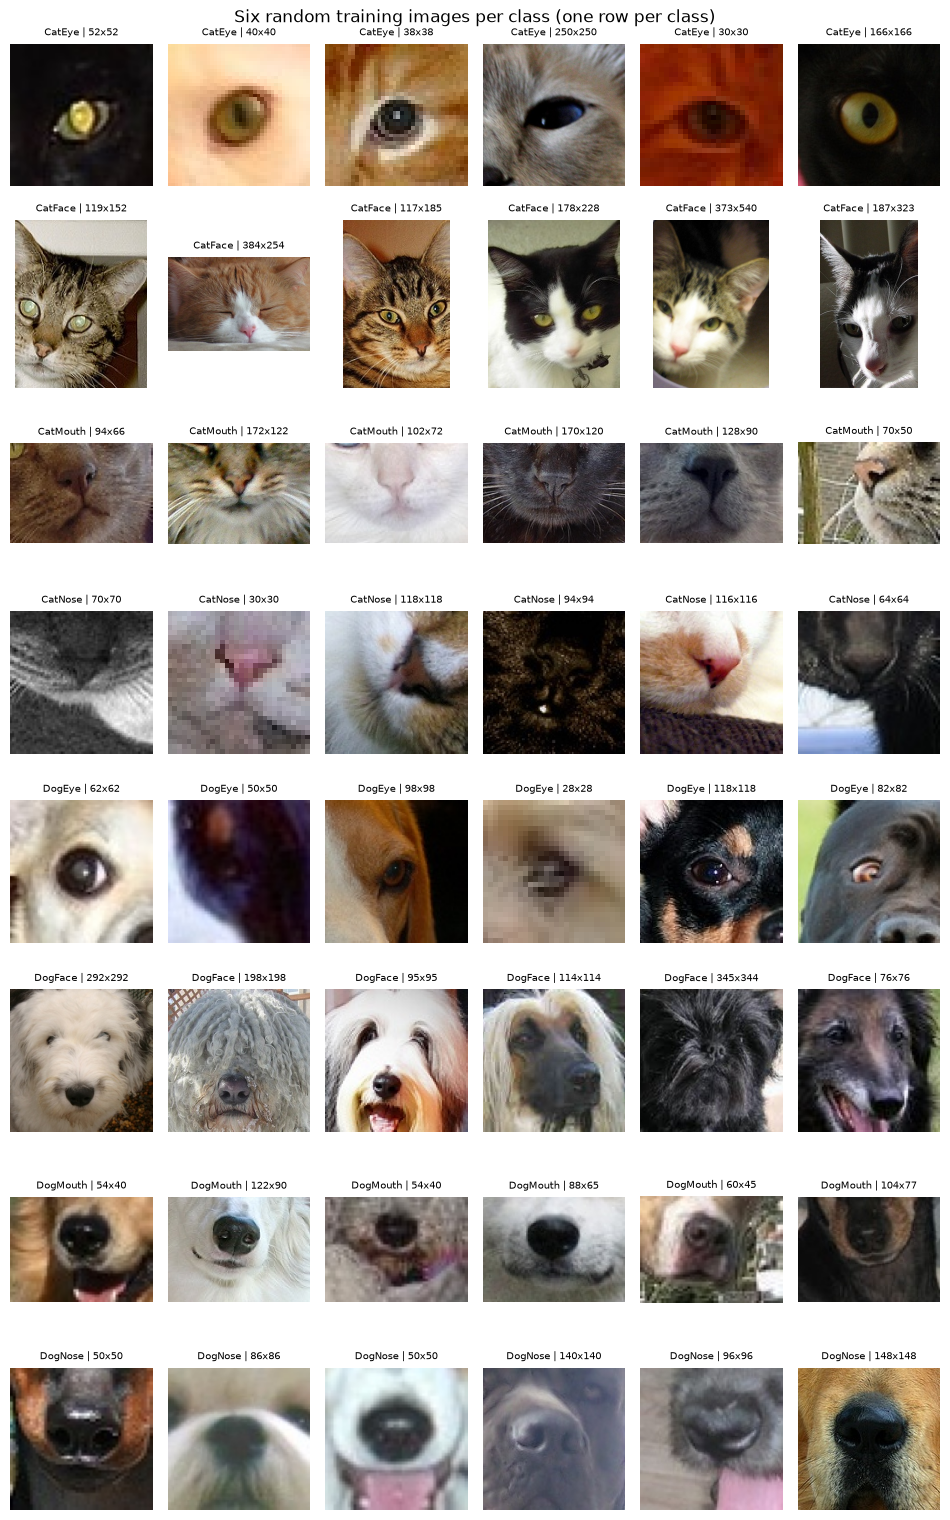

In [11]:
# Pick 6 random images from each class
sample_tables = []                                                      # One small table of 6 rows per class
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]      # Only the training images of this class
    sample_tables.append(df_class.sample(6, random_state=RANDOM_SEED))  # 6 random rows (the seed gives the same rows every run)
df_samples = pd.concat(sample_tables)                                   # Join the 8 tables into one table of 48 rows

# Caption each image with its class and real size, e.g. "CatEye | 36x36"
captions = []
for i in range(len(df_samples)):
    row = df_samples.iloc[i]                                            # The i-th row of the table
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

# 6 columns, so each class fills one row of the grid
show_images(df_samples, captions, n_columns=6,
            title="Six random training images per class (one row per class)",
            save_name="sample_images_per_class.png")

### 1.5 Image sizes

Sizes vary a lot, so this looks at the shorter side of each image.

In [12]:
# Table of image sizes for each class (the numbers in the f-strings set the width of each column)
print(f"{'Class':<10} {'Median W':>9} {'Median H':>9} {'Smallest':>9} {'Largest':>8} {'Small':>6} {'Small %':>8}")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]  # Only the training images of this class
    median_width = df_class["width"].median()                       # Middle value of the widths
    median_height = df_class["height"].median()                     # Middle value of the heights
    smallest_side = df_class["short_side"].min()                    # Shorter side of the smallest image
    largest_side = df_class["short_side"].max()                     # Shorter side of the largest image
    n_small = (df_class["short_side"] < SMALL_IMAGE_SIZE).sum()     # Count images whose shorter side is under the "small" limit
    percent_small = n_small / len(df_class) * 100                   # As a percentage of the class
    print(f"{class_name:<10} {median_width:>9.0f} {median_height:>9.0f} {smallest_side:>9} {largest_side:>8} {n_small:>6} {percent_small:>7.1f}%")
print(f"(Smallest/Largest = shorter side in pixels. Small = shorter side under {SMALL_IMAGE_SIZE} px.)")
print()

# Size checks across the whole dataset
n_sizes = len(df_info.groupby(["width", "height"]))                     # Number of different (width, height) combinations in train and test
n_square = (df_train_info["width"] == df_train_info["height"]).sum()    # Training images where the width equals the height
n_small = (df_train_info["short_side"] < SMALL_IMAGE_SIZE).sum()        # Training images whose shorter side is under the "small" limit
print("Different (width, height) sizes:", n_sizes)
print(f"Square training images: {n_square} ({n_square / total_train * 100:.1f}%)")   # Print as number and percentage
print(f"Small training images:  {n_small} ({n_small / total_train * 100:.1f}%)")

Class       Median W  Median H  Smallest  Largest  Small  Small %
CatEye            68        68         4      340   1459    10.5%
CatFace          182       215        22      945     14     0.2%
CatMouth         114        80         4      394    484     7.0%
CatNose           68        68         4      340    731    10.5%
DogEye            62        62        14      886    862     7.4%
DogFace          155       155        39     2219      0     0.0%
DogMouth         104        77        17     1107    149     2.6%
DogNose           62        62        14      886    431     7.4%
(Smallest/Largest = shorter side in pixels. Small = shorter side under 32 px.)

Different (width, height) sizes: 14347
Square training images: 41710 (65.5%)
Small training images:  4130 (6.5%)


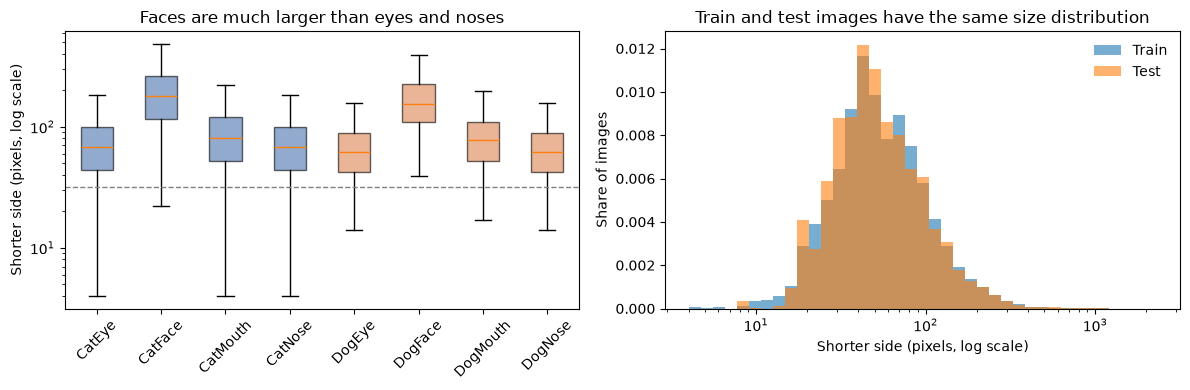

In [13]:
# Two plots side by side: shorter side per class (left) and train vs test sizes (right)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))

# Left: box plot of the shorter side for each class
box_data = []                                                           # One column of shorter sides per class
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]      # Only the training images of this class
    box_data.append(df_class["short_side"])

# showfliers=False hides the outlier dots, patch_artist=True lets the boxes be filled with colour
boxes = ax_left.boxplot(box_data, showfliers=False, patch_artist=True)
for i in range(len(CLASSES)):                                           # Colour cat boxes blue and dog boxes orange
    if CLASSES[i].startswith("Cat"):
        boxes["boxes"][i].set_facecolor(CAT_COLOUR)
    else:
        boxes["boxes"][i].set_facecolor(DOG_COLOUR)
    boxes["boxes"][i].set_alpha(0.6)                                    # Make the boxes slightly see-through

ax_left.set_xticks(range(1, len(CLASSES) + 1))                          # Box plot positions start at 1
ax_left.set_xticklabels(CLASSES, rotation=45)                           # Tilt the class names so they don't overlap
ax_left.set_yscale("log")                                               # Log scale, as sizes range from a few pixels to over 2000
ax_left.set_ylabel("Shorter side (pixels, log scale)")
ax_left.axhline(SMALL_IMAGE_SIZE, color="grey", linestyle="--", linewidth=1)   # Dashed line at the "small image" limit
ax_left.set_title("Faces are much larger than eyes and noses")

# Right: histogram of the shorter side, train vs test
bins = np.logspace(np.log10(4), np.log10(2300), 40)   # Evenly spaced bins on a log scale
# density=True shows the share of images instead of the count, so the larger training set can be compared with the test set
ax_right.hist(df_train_info["short_side"], bins=bins, density=True, alpha=0.6, label="Train")
ax_right.hist(df_test_info["short_side"], bins=bins, density=True, alpha=0.6, label="Test")
ax_right.set_xscale("log")                                              # Match the log-spaced bins
ax_right.set_xlabel("Shorter side (pixels, log scale)")
ax_right.set_ylabel("Share of images")
ax_right.set_title("Train and test images have the same size distribution")
ax_right.legend(frameon=False)                                          # Legend without a border

plt.tight_layout()                                                      # Stop the two plots overlapping
plt.savefig(figures_folder / "image_sizes.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

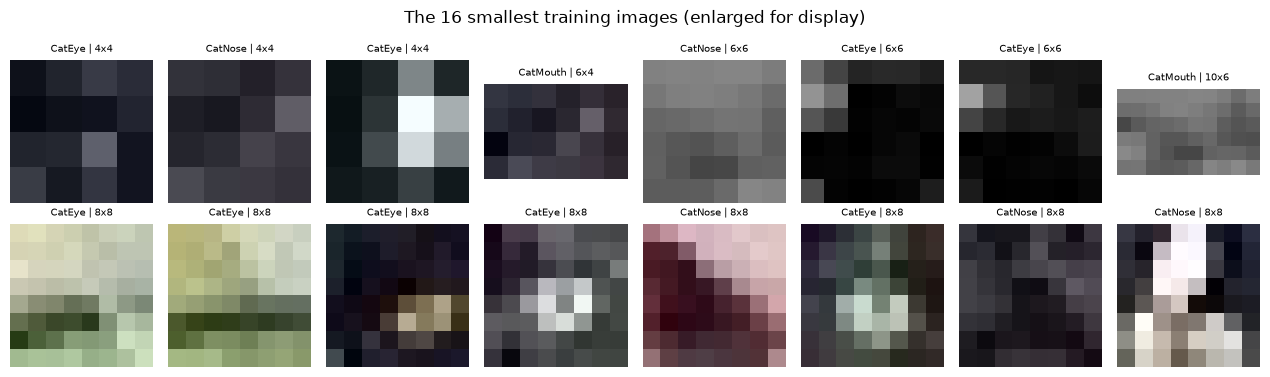

In [14]:
# The 16 smallest training images, enlarged so they can be seen
df_smallest = df_train_info.sort_values("total_pixels").head(16)    # Sort from fewest to most pixels and keep the first 16

# Caption each image with its class and real size
captions = []
for i in range(len(df_smallest)):
    row = df_smallest.iloc[i]                                       # The i-th row of the table
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

# 2 rows of 8 (show_images displays every image at the same size, which enlarges the small ones)
show_images(df_smallest, captions, n_columns=8,
            title="The 16 smallest training images (enlarged for display)",
            save_name="smallest_images.png")

### 1.6 Data quality issues

Checks for corrupt files, greyscale images, duplicates, blur, extreme brightness and unusual shapes.

In [15]:
# Corrupt files were flagged when images_info.csv was created (True counts as 1, so sum() counts them)
print("Corrupt or unreadable files:", df_info["is_corrupt"].sum())
print()

# Count the greyscale images in each split
n_grey_train = df_train_info["is_greyscale"].sum()
n_grey_test = df_test_info["is_greyscale"].sum()
print(f"Greyscale training images: {n_grey_train} ({n_grey_train / total_train * 100:.1f}%)")       # Print as number and percentage
print(f"Greyscale test images:     {n_grey_test} ({n_grey_test / len(df_test_info) * 100:.1f}%)")
print()

# Count the greyscale images in each class, to check whether one class has more than the others
print("Greyscale training images per class:")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]  # Only the training images of this class
    print(f"  {class_name:<10} {df_class['is_greyscale'].sum()}")

Corrupt or unreadable files: 0

Greyscale training images: 1011 (1.6%)
Greyscale test images:     423 (1.4%)

Greyscale training images per class:
  CatEye     395
  CatFace    195
  CatMouth   202
  CatNose    209
  DogEye     5
  DogFace    1
  DogMouth   2
  DogNose    2


**Duplicates.** Files with the same MD5 hash are identical copies.

Duplicate groups: 77 (154 files)
  within train only:       15
  within test only:        62
  across train and test:   0
  with conflicting labels: 0
Extra training copies to remove before splitting: 15


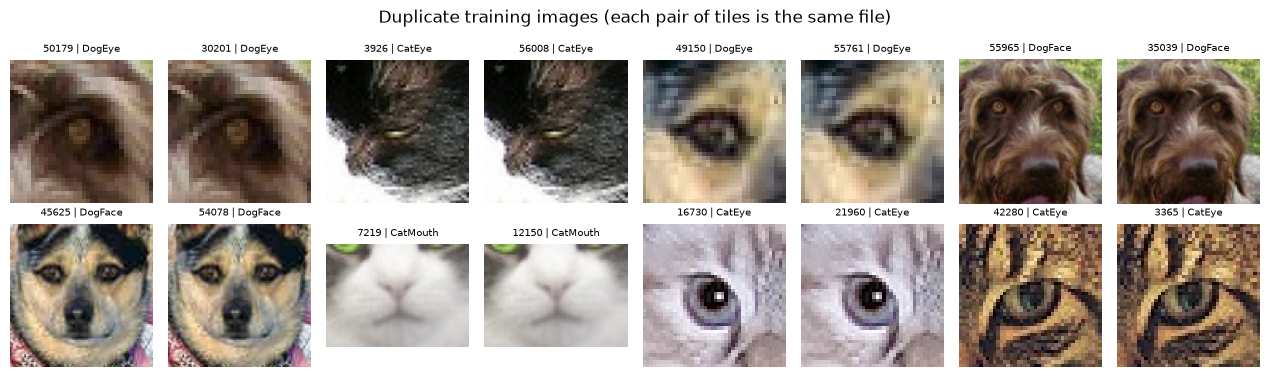

In [16]:
df_duplicates = df_info[df_info["is_duplicate"]]   # Every image that has at least one identical copy

# Counters for each kind of duplicate group
train_only = 0                  # All copies are in the training set
test_only = 0                   # All copies are in the test set
train_and_test = 0              # Copies in both sets (the model would have seen a test image during training)
conflicting_labels = 0          # Copies that have been given different classes

# Look at each group of identical files in turn
for md5_hash in df_duplicates["md5_hash"].unique():
    df_group = df_duplicates[df_duplicates["md5_hash"] == md5_hash]   # All copies of one file
    splits = set(df_group["split"])                                   # Which splits the copies are in, e.g. {"train"} or {"train", "test"}
    if splits == {"train"}:
        train_only += 1
    elif splits == {"test"}:
        test_only += 1
    else:
        train_and_test += 1

    labels = set(df_group["class"].dropna())                          # Different classes given to the copies (test copies have none, so are dropped)
    if len(labels) > 1:                                               # More than one class means the copies disagree
        conflicting_labels += 1

# Print the results
print("Duplicate groups:", df_duplicates["md5_hash"].nunique(), f"({len(df_duplicates)} files)")
print("  within train only:      ", train_only)
print("  within test only:       ", test_only)
print("  across train and test:  ", train_and_test)
print("  with conflicting labels:", conflicting_labels)

# Extra copies = every copy after the first one of each file
extra_train_copies = df_train_info.duplicated("md5_hash").sum()       # duplicated() marks every copy except the first as True
print("Extra training copies to remove before splitting:", extra_train_copies)

# Show some duplicate pairs (sorted by hash, so copies sit next to each other)
df_duplicate_examples = df_duplicates[df_duplicates["split"] == "train"].sort_values("md5_hash").head(16)
captions = []                                                         # Caption each image with its ID and class
for i in range(len(df_duplicate_examples)):
    row = df_duplicate_examples.iloc[i]
    captions.append(f"{row['image_id']} | {row['class']}")

show_images(df_duplicate_examples, captions, n_columns=8,
            title="Duplicate training images (each pair of tiles is the same file)",
            save_name="duplicate_images.png")

**Blur.** Sharpness is measured as the variance of the Laplacian, an edge-detection filter: a blurry or flat image has few edges, so a low value. Each image is resized to 64 x 64 first so big and small images can be compared. Measuring every image takes a few minutes, so the results are saved to `image_sharpness.csv` and loaded from there next time.

In [17]:
def measure_sharpness(image_path):
    """Return the variance of the Laplacian of an image (higher = sharper)."""
    image = Image.open(image_path).convert("L").resize((64, 64), Image.BILINEAR)   # "L" = greyscale
    pixels = np.array(image, dtype=np.float32)                                      # 64 x 64 array of brightness values (0 to 255)

    # Laplacian = (pixel above + below + left + right) - 4 x the pixel itself.
    # Each slice below is the 62 x 62 grid of those neighbours for every inner pixel.
    centre = pixels[1:-1, 1:-1]     # Every pixel except the outer border
    above = pixels[:-2, 1:-1]       # The pixel one row above each centre pixel
    below = pixels[2:, 1:-1]        # One row below
    left = pixels[1:-1, :-2]        # One column to the left
    right = pixels[1:-1, 2:]        # One column to the right
    laplacian = above + below + left + right - 4 * centre   # Close to 0 in flat areas, large at edges

    return float(laplacian.var())   # Variance = how spread out the values are (lots of strong edges = high variance)


# Only measure sharpness if it hasn't been saved before (it takes a few minutes)
if sharpness_csv_path.exists():
    df_sharpness = pd.read_csv(sharpness_csv_path)                  # Load the saved values
    print("Loaded sharpness values from", sharpness_csv_path)
else:
    print("Measuring sharpness of every image (a few minutes)...")
    sharpness_records = []                                          # One dictionary per image
    for split, image_id, file_name in zip(df_info["split"], df_info["image_id"], df_info["file_name"]):    # Loop over every train and test image
        value = measure_sharpness(get_image_path(split, file_name))
        sharpness_records.append({"split": split, "image_id": image_id, "sharpness": value})
    df_sharpness = pd.DataFrame(sharpness_records)
    df_sharpness.to_csv(sharpness_csv_path, index=False)            # Save so it only needs to run once

# Add the sharpness column to the image information
df_info = df_info.merge(df_sharpness, on=["split", "image_id"])     # Match on split and ID, as the same IDs are used in train and test
# Rebuild the train and test tables so they include the new sharpness column
df_train_info = df_info[df_info["split"] == "train"]
df_test_info = df_info[df_info["split"] == "test"]

Loaded sharpness values from image_sharpness.csv


Blurry training images (sharpness under 20): 868 (1.4%)
Blurry test images (sharpness under 20):     310 (1.1%)

Median sharpness per class:
  CatEye     468
  CatFace    994
  CatMouth   545
  CatNose    284
  DogEye     262
  DogFace    820
  DogMouth   527
  DogNose    301


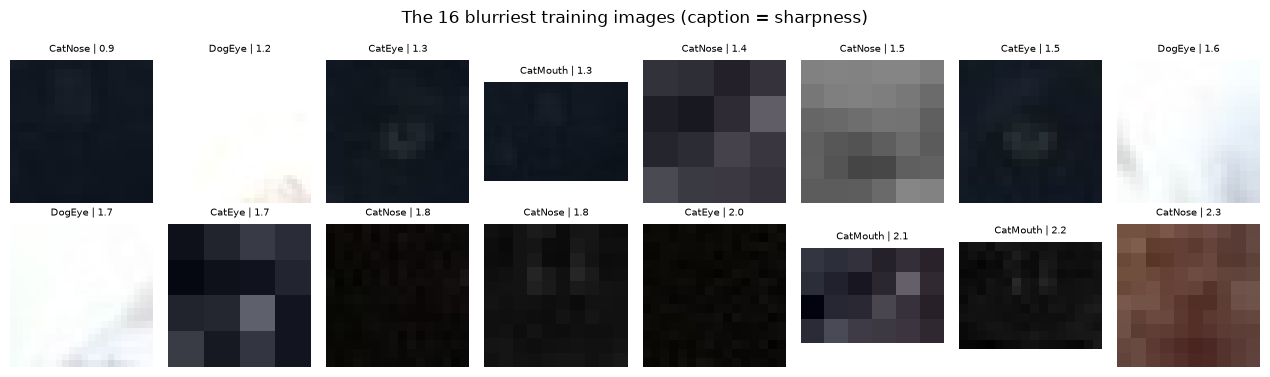

In [18]:
# Count the images below the blur threshold in each split
n_blurry_train = (df_train_info["sharpness"] < BLUR_THRESHOLD).sum()
n_blurry_test = (df_test_info["sharpness"] < BLUR_THRESHOLD).sum()
print(f"Blurry training images (sharpness under {BLUR_THRESHOLD}): {n_blurry_train} ({n_blurry_train / total_train * 100:.1f}%)")
print(f"Blurry test images (sharpness under {BLUR_THRESHOLD}):     {n_blurry_test} ({n_blurry_test / len(df_test_info) * 100:.1f}%)")
print()

# Median sharpness per class, to check whether some facial parts are blurrier than others
print("Median sharpness per class:")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]  # Only the training images of this class
    print(f"  {class_name:<10} {df_class['sharpness'].median():.0f}")

# The 16 blurriest training images
df_blurriest = df_train_info.sort_values("sharpness").head(16)      # Sort from least to most sharp and keep the first 16
captions = []                                                       # Caption each image with its class and sharpness
for i in range(len(df_blurriest)):
    row = df_blurriest.iloc[i]
    captions.append(f"{row['class']} | {row['sharpness']:.1f}")

show_images(df_blurriest, captions, n_columns=8,
            title="The 16 blurriest training images (caption = sharpness)",
            save_name="blurriest_images.png")

**Brightness and unusual shapes.**

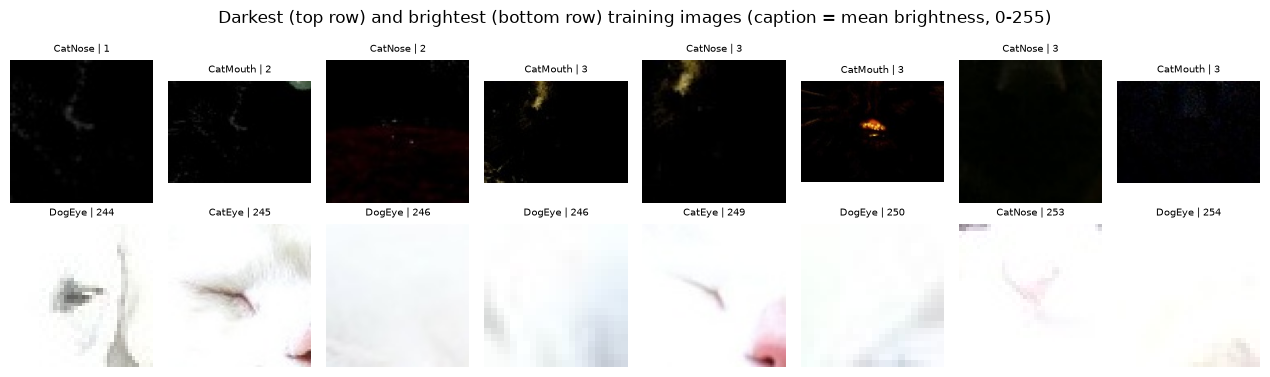

In [19]:
# Darkest 8 and brightest 8 training images
df_darkest = df_train_info.sort_values("mean_brightness").head(8)       # Sorted darkest first, so the first 8 are the darkest
df_brightest = df_train_info.sort_values("mean_brightness").tail(8)     # The last 8 are the brightest
df_dark_and_bright = pd.concat([df_darkest, df_brightest])              # Join into one table: dark images first, then bright

captions = []                                                           # Caption each image with its class and mean brightness
for i in range(len(df_dark_and_bright)):
    row = df_dark_and_bright.iloc[i]
    captions.append(f"{row['class']} | {row['mean_brightness']:.0f}")

# 8 columns, so the dark images fill the top row and the bright images the bottom row
show_images(df_dark_and_bright, captions, n_columns=8,
            title="Darkest (top row) and brightest (bottom row) training images (caption = mean brightness, 0-255)",
            save_name="darkest_brightest_images.png")

Training images with an extreme aspect ratio: 40


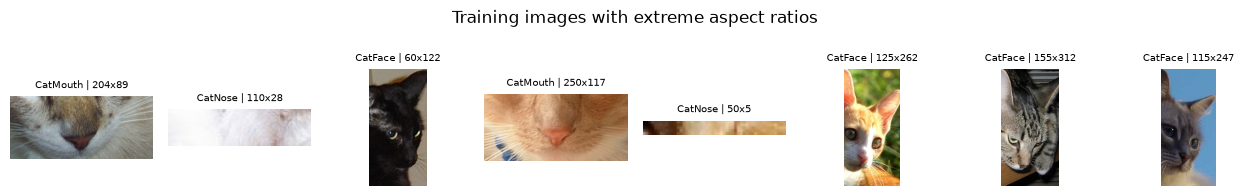

In [20]:
# Images more than twice as wide as tall, or more than twice as tall as wide
is_very_wide = df_train_info["aspect_ratio"] > 2                # True/False for each image (aspect ratio = width / height)
is_very_tall = df_train_info["aspect_ratio"] < 0.5
df_odd_shape = df_train_info[is_very_wide | is_very_tall]       # Keep images that are very wide or very tall (| means "or")
print("Training images with an extreme aspect ratio:", len(df_odd_shape))

# Show 8 random examples (fixed seed, so the same images every run)
df_odd_examples = df_odd_shape.sample(8, random_state=RANDOM_SEED)
captions = []                                                   # Caption each image with its class and real size
for i in range(len(df_odd_examples)):
    row = df_odd_examples.iloc[i]
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

show_images(df_odd_examples, captions, n_columns=8,
            title="Training images with extreme aspect ratios",
            save_name="extreme_aspect_ratio_images.png")

### 1.7 Training set versus test set

If the test images look like the training images, the validation score should be a good estimate of the Kaggle score.

In [21]:
def summarise(df):
    """Return a dictionary of summary numbers for a set of images."""
    n_images = len(df)
    summary = {}                                                    # Each key becomes one row of the comparison table
    summary["images"] = n_images
    summary["median width (px)"] = df["width"].median()
    summary["median height (px)"] = df["height"].median()
    # Percentage of images whose shorter side is under the "small" limit
    summary["small images (%)"] = round((df["short_side"] < SMALL_IMAGE_SIZE).sum() / n_images * 100, 1)
    summary["greyscale (%)"] = round(df["is_greyscale"].sum() / n_images * 100, 1)
    summary["mean brightness (0-255)"] = round(df["mean_brightness"].mean(), 1)
    summary["median sharpness"] = round(df["sharpness"].median(), 1)
    # Percentage of images with sharpness under the blur threshold
    summary["blurry (%)"] = round((df["sharpness"] < BLUR_THRESHOLD).sum() / n_images * 100, 1)
    return summary


# Work out the same summary numbers for both splits
train_summary = summarise(df_train_info)
test_summary = summarise(df_test_info)

# Print the two summaries side by side
print(f"{'':<26} {'Train':>8} {'Test':>8}")
for name in train_summary:                                          # One row per summary number
    print(f"{name:<26} {train_summary[name]:>8} {test_summary[name]:>8}")

# Save the table for the report
df_comparison = pd.DataFrame({"train": train_summary, "test": test_summary})    # One column per split, one row per summary number
df_comparison.to_csv(results_folder / "train_vs_test_summary.csv")

                              Train     Test
images                        63660    29443
median width (px)              84.0     82.0
median height (px)             80.0     80.0
small images (%)                6.5      8.2
greyscale (%)                   1.6      1.4
mean brightness (0-255)       110.3    110.4
median sharpness              489.8    484.6
blurry (%)                      1.4      1.1


## Task 2: Data Preprocessing and Pipeline Preparation

### Settings used in this section

PyTorch imports, the fixed random seeds and the preprocessing constants. Task 1 found the median image is about 80 x 84 pixels, and eyes and noses are only 62 to 68 pixels, so every image is resized to 64 x 64. A bigger size would mostly enlarge small images and make training much slower on this laptop's CPU.

In [22]:
import random
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Folder paths
splits_folder = Path("splits")                    # Folder to store the training and validation split CSV files
splits_folder.mkdir(exist_ok=True)                # Create the folder if it doesn't exist yet

# Preprocessing settings
IMAGE_SIZE = 64                                   # Every image is resized to IMAGE_SIZE x IMAGE_SIZE pixels
BATCH_SIZE = 64                                   # Number of images the model sees in each training step
VALIDATION_FRACTION = 0.2                         # Share of the labelled training images kept back for validation
NUM_WORKERS = 0                                   # Images are loaded in the main process (extra worker processes are unreliable in Jupyter on macOS)

# Mean and standard deviation of the red, green and blue channels of the ImageNet dataset.
# These are fixed, published ImageNet values, so nothing is calculated from the validation or test data (no data leakage).
# Every model uses them, and pretrained torchvision models expect images normalised with these values.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Fix every random number generator, so the split, augmentation and training are the same every run
random.seed(RANDOM_SEED)                          # Python's own random module
np.random.seed(RANDOM_SEED)                       # NumPy
torch.manual_seed(RANDOM_SEED)                    # PyTorch

# Use a GPU if there is one, otherwise the CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")                 # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")                  # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:    ", torch.__version__)
print("torchvision version:", torchvision.__version__)
print("Device:             ", DEVICE)
print("CPU threads:        ", torch.get_num_threads())
print()
print("Image size:         ", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Batch size:         ", BATCH_SIZE)
print("Validation fraction:", VALIDATION_FRACTION)
print("Number of classes:  ", len(CLASSES))

PyTorch version:     2.2.2
torchvision version: 0.17.2
Device:              cpu
CPU threads:         2

Image size:          64 x 64
Batch size:          64
Validation fraction: 0.2
Number of classes:   8


### 2.1 Remove duplicate training images

Task 1 found 15 extra copies of training images (identical MD5 hash, same label). Only the first copy of each file is kept, so the same image cannot end up in both the training and validation sets after the split.

In [23]:
n_before = len(df_train_info)                                               # Training images before removing copies

# Keep the first copy of each file (the rows are in image ID order, so this is the copy with the lowest ID)
df_train_clean = df_train_info.drop_duplicates("md5_hash", keep="first")
n_after = len(df_train_clean)                                               # Training images after removing copies
n_removed = n_before - n_after                                              # Number of extra copies dropped

print("Training images before removing duplicates:", n_before)
print("Training images after removing duplicates: ", n_after)
print("Duplicate copies removed:                  ", n_removed)
print()

# Check that every md5_hash now appears only once
n_repeated_hashes = df_train_clean["md5_hash"].duplicated().sum()          # Rows whose hash was already seen earlier in the table
print("Hashes appearing more than once:", n_repeated_hashes)
print("Every training image is now unique:", n_repeated_hashes == 0)

Training images before removing duplicates: 63660
Training images after removing duplicates:  63645
Duplicate copies removed:                   15

Hashes appearing more than once: 0
Every training image is now unique: True


### 2.2 Split into training and validation sets

The classes are unbalanced (CatEye is 2.4 times bigger than DogFace), so each class is split separately: a random 20% of its images go to validation and the rest to training. This is a stratified split, so both sets keep the same class proportions. The fixed seed gives the same split every run, and both splits are saved as CSV files so they can be reused. If the split CSVs already exist they are loaded instead (set `REMAKE_SPLIT = True` in the Run options to make the split again); the code that makes the split is in the `else` branch below. The saved CSVs are also what `kaggle_resnet18_baseline_notebook.ipynb` uses on Kaggle, so its validation images are exactly the same.

In [24]:
if train_split_csv_path.exists() and validation_split_csv_path.exists() and not REMAKE_SPLIT:
    # The split was made and saved before: load it, so it is exactly the same every run
    df_train_split = pd.read_csv(train_split_csv_path, dtype={"class": "string"})
    df_validation_split = pd.read_csv(validation_split_csv_path, dtype={"class": "string"})
    print("Loaded the saved split:", train_split_csv_path, "and", validation_split_csv_path, "(set REMAKE_SPLIT = True to make it again)")
else:
    training_tables = []                                                            # One table of training rows per class
    validation_tables = []                                                          # One table of validation rows per class

    for class_name in CLASSES:
        df_class = df_train_clean[df_train_clean["class"] == class_name]            # Only the images of this class
        df_class_validation = df_class.sample(frac=VALIDATION_FRACTION, random_state=RANDOM_SEED)  # Random 20% of the class for validation
        df_class_training = df_class.drop(df_class_validation.index)                # Every other row of the class goes to training
        training_tables.append(df_class_training)
        validation_tables.append(df_class_validation)

    df_train_split = pd.concat(training_tables)                                     # Join the 8 training tables into one
    df_validation_split = pd.concat(validation_tables)                              # Join the 8 validation tables into one

    # Save both splits so the same images are used in every later step
    df_train_split.to_csv(train_split_csv_path, index=False)
    df_validation_split.to_csv(validation_split_csv_path, index=False)
    print("Saved", train_split_csv_path, "and", validation_split_csv_path)
print()

# Size of each split
n_clean = len(df_train_clean)
n_train_split = len(df_train_split)
n_validation_split = len(df_validation_split)
print(f"Training split:   {n_train_split} images ({n_train_split / n_clean * 100:.1f}%)")
print(f"Validation split: {n_validation_split} images ({n_validation_split / n_clean * 100:.1f}%)")
print(f"Total:            {n_train_split + n_validation_split} images (should be {n_clean})")

# Leakage check: no image ID should be in both splits
train_ids = set(df_train_split["image_id"])
validation_ids = set(df_validation_split["image_id"])
print("Images in both splits:", len(train_ids & validation_ids))                # & keeps the IDs found in both sets
print()

# Table of each class's count and its share of each split (the percentages should match)
print(f"{'Class':<10} {'Train':>7} {'Train %':>8} {'Valid':>7} {'Valid %':>8}")
for class_name in CLASSES:
    n_class_train = (df_train_split["class"] == class_name).sum()              # Training images of this class
    n_class_validation = (df_validation_split["class"] == class_name).sum()    # Validation images of this class
    train_percent = n_class_train / n_train_split * 100                         # Share of the training split
    validation_percent = n_class_validation / n_validation_split * 100          # Share of the validation split
    print(f"{class_name:<10} {n_class_train:>7} {train_percent:>7.1f}% {n_class_validation:>7} {validation_percent:>7.1f}%")
print(f"{'Total':<10} {n_train_split:>7} {100:>7.1f}% {n_validation_split:>7} {100:>7.1f}%")

Loaded the saved split: splits/train_split.csv and splits/validation_split.csv (set REMAKE_SPLIT = True to make it again)

Training split:   50917 images (80.0%)
Validation split: 12728 images (20.0%)
Total:            63645 images (should be 63645)
Images in both splits: 0

Class        Train  Train %   Valid  Valid %
CatEye       11102    21.8%    2775    21.8%
CatFace       5554    10.9%    1388    10.9%
CatMouth      5553    10.9%    1388    10.9%
CatNose       5553    10.9%    1388    10.9%
DogEye        9261    18.2%    2315    18.2%
DogFace       4630     9.1%    1158     9.1%
DogMouth      4632     9.1%    1158     9.1%
DogNose       4632     9.1%    1158     9.1%
Total        50917   100.0%   12728   100.0%


### 2.3 Leakage check between the training and validation splits

If the same image is in both splits, the validation score would be too optimistic. This checks that no image ID and no file (MD5 hash) appears in both.

In [25]:
# Sets of image IDs and file hashes in each split
train_ids = set(df_train_split["image_id"])
validation_ids = set(df_validation_split["image_id"])

train_hashes = set(df_train_split["md5_hash"])
validation_hashes = set(df_validation_split["md5_hash"])

# & keeps only the values found in both sets
n_shared_ids = len(train_ids & validation_ids)                  # Image IDs used in both splits
n_shared_hashes = len(train_hashes & validation_hashes)         # Identical files found in both splits

print("Image IDs in both splits:   ", n_shared_ids)
print("MD5 hashes in both splits:  ", n_shared_hashes)
print()

if n_shared_ids == 0 and n_shared_hashes == 0:
    print("PASS: no image or file is shared between the training and validation splits")
else:
    print("FAIL: the training and validation splits share images, so the validation score would be too optimistic")

Image IDs in both splits:    0
MD5 hashes in both splits:   0

PASS: no image or file is shared between the training and validation splits


### 2.4 Encode the class labels as numbers

The model outputs one score per class, so each class name is given a number from 0 to 7, in the order of `CLASSES`. `index_to_class` turns the model's predicted numbers back into class names for the Kaggle submission.

In [26]:
class_to_index = {}                                             # Class name -> number, e.g. "CatEye" -> 0
index_to_class = {}                                             # Number -> class name, e.g. 0 -> "CatEye"
for index in range(len(CLASSES)):
    class_name = CLASSES[index]
    class_to_index[class_name] = index
    index_to_class[index] = class_name

print("class_to_index:", class_to_index)
print("index_to_class:", index_to_class)
print()

# Add the number for each image's class as a new "label" column
df_train_split["label"] = df_train_split["class"].map(class_to_index)            # Look up each class name in the dictionary
df_validation_split["label"] = df_validation_split["class"].map(class_to_index)

# Every row should have a label (map() gives an empty value for a class name not in the dictionary)
print("Missing labels in training split:  ", df_train_split["label"].isna().sum())
print("Missing labels in validation split:", df_validation_split["label"].isna().sum())
print()

print("First 5 rows of df_train_split:")
print(df_train_split[["image_id", "file_name", "class", "label"]].head())

class_to_index: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
index_to_class: {0: 'CatEye', 1: 'CatFace', 2: 'CatMouth', 3: 'CatNose', 4: 'DogEye', 5: 'DogFace', 6: 'DogMouth', 7: 'DogNose'}

Missing labels in training split:   0
Missing labels in validation split: 0

First 5 rows of df_train_split:
   image_id  file_name   class  label
0        15  00015.jpg  CatEye      0
1        17  00017.jpg  CatEye      0
2        30  00030.jpg  CatEye      0
3        33  00033.jpg  CatEye      0
4        39  00039.jpg  CatEye      0


### 2.5 Image transforms (resizing, normalisation and augmentation)

Two transforms, built with `transforms.Compose`:
- `evaluation_transform` is for the validation and test images. It only resizes and normalises, so every evaluation image is processed the same way every time.
- `training_transform` resizes and normalises in the same way, but first applies random changes (augmentation), so the model sees a slightly different version of each training image every epoch. This helps it generalise instead of memorising the training images.

In [27]:
# Validation and test images: no randomness, so predictions are repeatable
evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),                # Stretch or shrink to IMAGE_SIZE x IMAGE_SIZE, so every image has the same size for the model
    transforms.ToTensor(),                                      # PIL image -> 3 x height x width tensor, with pixel values rescaled from 0-255 to 0-1
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), # Subtract the ImageNet mean and divide by the std for each channel, so values are centred around 0
])                                                              # End of the list of steps, applied in order from top to bottom

# Training images: the same resize and normalisation, plus random augmentation
training_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)), # Crop a random 80-100% of the image and resize it to IMAGE_SIZE, so the feature is not always centred and the same size
    transforms.RandomHorizontalFlip(),                          # Mirror left-right half of the time (a flipped eye or face is still the same class)
    transforms.RandomRotation(15),                              # Rotate by up to 15 degrees either way, as faces in photos are often slightly tilted
    transforms.ColorJitter(brightness=0.2, contrast=0.2),       # Change brightness and contrast by up to 20%, as Task 1 found very dark and very bright images
    transforms.RandomGrayscale(p=0.1),                          # Make 10% of images greyscale, as Task 1 found 1001 of the 1011 greyscale images are cats, so this stops the model learning that greyscale means cat
    transforms.ToTensor(),                                      # PIL image -> 3 x height x width tensor, with pixel values rescaled from 0-255 to 0-1
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), # Same normalisation as evaluation_transform, so training and test images are on the same scale
])                                                              # End of the list of steps, applied in order from top to bottom

Test both transforms on one training image and check the output shapes.

In [28]:
first_row = df_train_split.iloc[0]                                              # The first image in the training split
test_image = Image.open(get_image_path("train", first_row["file_name"])).convert("RGB")   # Open it as an RGB PIL image
print("Image:", first_row["file_name"], "|", first_row["class"])
print("Original size (width x height):", test_image.width, "x", test_image.height)
print()

evaluation_tensor = evaluation_transform(test_image)                            # Apply the evaluation transform
training_tensor = training_transform(test_image)                                # Apply the training transform (random, so different every time)

# Shape is (channels, height, width)
print("evaluation_transform output shape:", tuple(evaluation_tensor.shape))
print("training_transform output shape:  ", tuple(training_tensor.shape))
print()

# After normalisation the values are no longer 0-1: roughly -2 to +2.6, centred near 0
print(f"evaluation_transform value range: {evaluation_tensor.min():.2f} to {evaluation_tensor.max():.2f}")
print(f"training_transform value range:   {training_tensor.min():.2f} to {training_tensor.max():.2f}")
print("Tensor data type:", evaluation_tensor.dtype)

Image: 00015.jpg | CatEye
Original size (width x height): 158 x 158

evaluation_transform output shape: (3, 64, 64)
training_transform output shape:   (3, 64, 64)

evaluation_transform value range: -2.12 to 2.32
training_transform value range:   -2.12 to 2.54
Tensor data type: torch.float32


### 2.6 Dataset classes

A PyTorch `Dataset` tells the DataLoader how many images there are (`__len__`) and how to load image number `i` (`__getitem__`). Images are opened from disk one at a time when they are needed, so the whole dataset never has to fit in memory.

`FacialFeatureDataset` is for the labelled training and validation images and returns `(image_tensor, label)`.

In [29]:
class FacialFeatureDataset(Dataset):
    """Labelled images: returns (image_tensor, label) for each row of a dataframe."""

    def __init__(self, df, transform):
        self.df = df                                                    # One row per image (needs split, file_name and label columns)
        self.transform = transform                                      # Transform applied to every image (training or evaluation)

    def __len__(self):
        return len(self.df)                                             # Number of images in the dataset

    def __getitem__(self, i):
        row = self.df.iloc[i]                                           # The i-th row of the dataframe
        image_path = get_image_path(row["split"], row["file_name"])     # Full path of the image file
        image = Image.open(image_path).convert("RGB")                   # Open the image and make sure it has 3 colour channels
        image_tensor = self.transform(image)                            # Resize, (augment) and normalise -> 3 x IMAGE_SIZE x IMAGE_SIZE tensor
        label = int(row["label"])                                       # Class number 0-7 (int, so the DataLoader makes a tensor of whole numbers)
        return image_tensor, label

`TestImageDataset` is for the Kaggle test images. They have no label, so it returns `(image_tensor, image_id)` instead, and the ID is used to match each prediction to its image in the submission file.

In [30]:
class TestImageDataset(Dataset):
    """Unlabelled test images: returns (image_tensor, image_id) for each row of a dataframe."""

    def __init__(self, df, transform):
        self.df = df                                                    # One row per image (needs split, file_name and image_id columns)
        self.transform = transform                                      # Transform applied to every image (always the evaluation transform)

    def __len__(self):
        return len(self.df)                                             # Number of images in the dataset

    def __getitem__(self, i):
        row = self.df.iloc[i]                                           # The i-th row of the dataframe
        image_path = get_image_path(row["split"], row["file_name"])     # Full path of the image file
        image = Image.open(image_path).convert("RGB")                   # Open the image and make sure it has 3 colour channels
        image_tensor = self.transform(image)                            # Resize and normalise -> 3 x IMAGE_SIZE x IMAGE_SIZE tensor
        image_id = int(row["image_id"])                                 # Image ID, used to write the prediction to the right row of the submission
        return image_tensor, image_id

Create the three datasets. Only the training dataset uses augmentation; validation and test both use the evaluation transform, so they are processed in exactly the same way.

In [31]:
train_dataset = FacialFeatureDataset(df_train_split, training_transform)             # Training split, with random augmentation
validation_dataset = FacialFeatureDataset(df_validation_split, evaluation_transform) # Validation split, resize and normalise only
test_dataset = TestImageDataset(df_test_info, evaluation_transform)                  # Kaggle test images, resize and normalise only

print("Images in train_dataset:     ", len(train_dataset))
print("Images in validation_dataset:", len(validation_dataset))
print("Images in test_dataset:      ", len(test_dataset))
print()

# Load the first item of each dataset to check it works
first_train_image, first_train_label = train_dataset[0]
first_validation_image, first_validation_label = validation_dataset[0]
first_test_image, first_test_id = test_dataset[0]

print("First training item:   shape", tuple(first_train_image.shape), "| label", first_train_label, "=", index_to_class[first_train_label])
print("First validation item: shape", tuple(first_validation_image.shape), "| label", first_validation_label, "=", index_to_class[first_validation_label])
print("First test item:       shape", tuple(first_test_image.shape), "| image_id", first_test_id)

Images in train_dataset:      50917
Images in validation_dataset: 12728
Images in test_dataset:       29443

First training item:   shape (3, 64, 64) | label 0 = CatEye
First validation item: shape (3, 64, 64) | label 0 = CatEye
First test item:       shape (3, 64, 64) | image_id 1


### 2.7 Data loaders

A `DataLoader` takes images from a dataset in batches of `BATCH_SIZE`. The training loader shuffles the images every epoch, so each batch has a mix of classes and the model does not see them in the same order each time. The validation and test loaders keep the images in order, so the results are repeatable and the test predictions line up with the image IDs.

In [32]:
import time

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)             # Shuffled every epoch
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)   # Same order every time
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)               # Same order as the image IDs

# Get one batch from the training loader and time how long it takes
start_time = time.perf_counter()                                    # Start the timer
images, labels = next(iter(train_loader))                           # Load the first batch of images and labels
batch_seconds = time.perf_counter() - start_time                    # Time taken in seconds

print("Image batch shape:", tuple(images.shape), "(batch size, channels, height, width)")
print("Label batch shape:", tuple(labels.shape))
print("Labels in the batch:", labels.tolist())
print(f"Minimum pixel value: {images.min():.2f}")
print(f"Maximum pixel value: {images.max():.2f}")
print()

# Number of batches = number of images / BATCH_SIZE, rounded up (the last batch can be smaller)
print("Batches in train_loader:     ", len(train_loader))
print("Batches in validation_loader:", len(validation_loader))
print("Batches in test_loader:      ", len(test_loader))
print()

print(f"Time to load one training batch: {batch_seconds:.3f} seconds")
print(f"Estimated time to load every training batch once (one epoch, loading only): {batch_seconds * len(train_loader) / 60:.1f} minutes")

Image batch shape: (64, 3, 64, 64) (batch size, channels, height, width)
Label batch shape: (64,)
Labels in the batch: [2, 4, 7, 5, 7, 4, 4, 6, 1, 0, 4, 4, 0, 0, 5, 0, 6, 2, 6, 3, 6, 7, 6, 0, 4, 1, 0, 0, 4, 0, 3, 3, 2, 2, 4, 0, 4, 0, 3, 1, 0, 0, 3, 3, 0, 3, 4, 7, 7, 3, 4, 6, 1, 0, 3, 0, 0, 5, 1, 7, 3, 1, 0, 1]
Minimum pixel value: -2.12
Maximum pixel value: 2.64

Batches in train_loader:      796
Batches in validation_loader: 199
Batches in test_loader:       461

Time to load one training batch: 0.723 seconds
Estimated time to load every training batch once (one epoch, loading only): 9.6 minutes


### 2.8 Augmentation examples

A check that the augmentation changes the images without hiding the facial feature. After normalisation the pixel values are roughly -2 to +2.6, which `plt.imshow` cannot show properly, so a small helper undoes the normalisation first.

In [33]:
def undo_normalisation(image_tensor):
    """Turn a normalised 3 x height x width tensor back into a height x width x 3 array with values 0-1, for plt.imshow."""
    image = image_tensor.clone()                                                # Copy, so the original tensor is not changed
    for channel in range(3):                                                    # Red, green and blue in turn
        image[channel] = image[channel] * IMAGENET_STD[channel] + IMAGENET_MEAN[channel]   # Reverse Normalize: multiply by the std, then add the mean
    image = image.clamp(0, 1)                                                   # Clip to 0-1 (rounding can push values slightly outside)
    return image.permute(1, 2, 0).numpy()                                       # Reorder to height x width x channels, as plt.imshow expects

Eight random training images: the top row is each image after `evaluation_transform` (resized only), and the bottom row is the same image after `training_transform` (random crop, flip, rotation, colour change and greyscale).

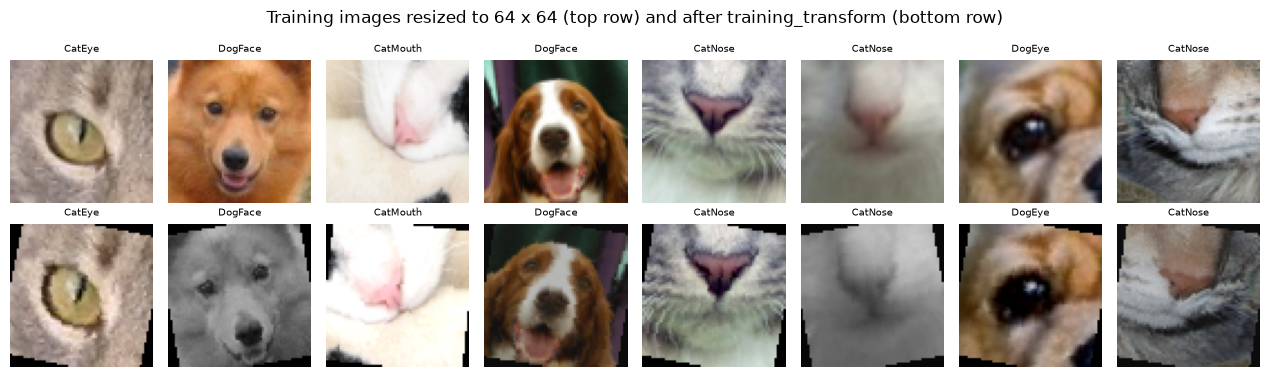

In [34]:
df_augmentation_examples = df_train_split.sample(8, random_state=RANDOM_SEED)  # 8 random training images (same ones every run)
torch.manual_seed(RANDOM_SEED)                                                  # Fix the random augmentation, so the figure is the same every run

n_images = len(df_augmentation_examples)
plt.figure(figsize=(n_images * 1.6, 2 * 1.95))                                  # Same tile size as show_images in Task 1

for i in range(n_images):
    row = df_augmentation_examples.iloc[i]                                      # The i-th example image
    image = Image.open(get_image_path(row["split"], row["file_name"])).convert("RGB")

    original_tensor = evaluation_transform(image)                               # Resized to IMAGE_SIZE x IMAGE_SIZE and normalised, no augmentation
    augmented_tensor = training_transform(image)                                # Resized, randomly augmented and normalised

    plt.subplot(2, n_images, i + 1)                                             # Top row: positions 1 to 8
    plt.imshow(undo_normalisation(original_tensor))
    plt.title(row["class"], fontsize=7)
    plt.axis("off")

    plt.subplot(2, n_images, n_images + i + 1)                                  # Bottom row: positions 9 to 16
    plt.imshow(undo_normalisation(augmented_tensor))
    plt.title(row["class"], fontsize=7)
    plt.axis("off")

plt.suptitle(f"Training images resized to {IMAGE_SIZE} x {IMAGE_SIZE} (top row) and after training_transform (bottom row)")
plt.tight_layout()                                                              # Stop the titles overlapping
plt.savefig(figures_folder / "augmentation_examples.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

### 2.9 Summary of preprocessing choices

| Choice | What was done | Reason |
|---|---|---|
| Duplicates | Kept the first copy of each MD5 hash: 63,660 → 63,645 training images (15 extra copies removed) | Stops the same image being in both the training and validation sets |
| Split | Stratified 80/20 split, done class by class with `RANDOM_SEED = 42`: 50,917 training and 12,728 validation images, 0 shared image IDs or MD5 hashes; saved to `splits/` | The classes are unbalanced (CatEye 21.8%, DogFace 9.1%), so splitting each class separately keeps the same proportions in both sets |
| Labels | `class_to_index` maps CatEye → 0 … DogNose → 7 (order of `CLASSES`); `index_to_class` reverses it | The model outputs one score per class number; `index_to_class` turns predictions back into names for the submission |
| Image size | `IMAGE_SIZE = 64` for the baseline CNN (ResNet-18 uses 128; the comparison of 128 and 224 px for ResNet-18 is done in Task 4) | The median training image is 84 x 80 pixels and eyes and noses are only 62-68 pixels, and 64 keeps training practical on a CPU |
| Resizing | `Resize((64, 64))` stretches every image to a square | Every image must be the same size for the model; 34.5% of training images are not square, but only 40 have an extreme aspect ratio |
| Normalisation | `ToTensor` rescales pixels from 0-255 to 0-1, then `Normalize` with the fixed ImageNet mean and std (values now -2.12 to 2.64) | Fixed published values, so nothing is calculated from validation or test data; pretrained models expect this normalisation |
| Augmentation (training only) | `RandomResizedCrop(scale=(0.8, 1.0))`, `RandomHorizontalFlip`, `RandomRotation(15)`, `ColorJitter(brightness=0.2, contrast=0.2)`, `RandomGrayscale(p=0.1)` | Varied position, tilt and lighting help the model generalise; 1,001 of the 1,011 greyscale training images are cats, so random greyscale stops it learning that greyscale means cat |
| Validation and test images | `evaluation_transform` only (resize and normalise, no randomness) | Validation and test images are processed in exactly the same way, so the validation score is a fair estimate of the Kaggle score |
| Data loaders | `BATCH_SIZE = 64`, `NUM_WORKERS = 0`; training loader shuffled, validation and test loaders in order: 796, 199 and 461 batches | Shuffling mixes the classes in every batch; keeping test images in order lines predictions up with the image IDs; one training batch takes about 0.37 s to load (about 5 minutes per epoch on this CPU) |

## Task 3: Model Selection and Pipeline Development

Two models are built and compared:
1. A small **custom CNN** trained from scratch, as a baseline. It is small enough to train on the laptop CPU.
2. A **pretrained ResNet-18** (trained on ImageNet), fine-tuned on a Kaggle Notebook GPU. It already knows general shapes and textures, so it should learn the facial features faster and more accurately than a model starting from nothing.

### Settings used in this section

Training settings, and the folders for saved model weights and Kaggle submission files.

In [35]:
import torch.nn as nn
import torchvision.models as models

# Training settings
EPOCHS = 10                                       # Number of full passes over the training images
LEARNING_RATE = 0.001                             # Adam's default learning rate, a common starting point

# Folder paths
models_folder = Path("models")                    # Folder to store the best weights of each model (ignored by git, as the files are large)
submissions_folder = Path("submissions")          # Folder to store the Kaggle submission CSV files
models_folder.mkdir(exist_ok=True)                # Create the folders if they don't exist yet
submissions_folder.mkdir(exist_ok=True)

print("Epochs:            ", EPOCHS)
print("Learning rate:     ", LEARNING_RATE)
print("Models folder:     ", models_folder, "| exists:", models_folder.exists())
print("Submissions folder:", submissions_folder, "| exists:", submissions_folder.exists())

Epochs:             10
Learning rate:      0.001
Models folder:      models | exists: True
Submissions folder: submissions | exists: True


### 3.1 Baseline model: a custom CNN

A small convolutional neural network (CNN) trained from scratch. It has 4 convolution blocks, and each block:
- **Conv2d** (3 x 3 filters) finds small patterns such as edges, fur texture and the outline of an eye or nose.
- **BatchNorm2d** rescales the outputs of each filter, which makes training faster and more stable.
- **ReLU** sets negative values to 0, so the network can learn non-linear patterns.
- **MaxPool2d(2)** halves the height and width, keeping the strongest response in each 2 x 2 area.

Each block halves the image size and has more filters than the one before, so later blocks combine simple patterns into larger, more complex ones. Global average pooling then averages each of the 256 feature maps down to one number, and a final linear layer turns those 256 numbers into 8 class scores. Dropout randomly switches off 30% of the 256 values during training, so the model cannot rely too heavily on any one of them (this reduces overfitting).

In [36]:
class BaselineCNN(nn.Module):
    """Custom CNN: 4 convolution blocks, global average pooling and one linear layer."""

    def __init__(self):
        super().__init__()                                                  # Set up the nn.Module parts of the class

        # Block 1: 3 colour channels in, 32 filters out
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),                     # 32 filters of 3 x 3; padding=1 keeps the size at 64 x 64
            nn.BatchNorm2d(32),                                             # Rescale each of the 32 feature maps
            nn.ReLU(),                                                      # Set negative values to 0
            nn.MaxPool2d(2),                                                # Halve the size: 64 x 64 -> 32 x 32
        )

        # Block 2: 32 channels in, 64 filters out
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),                    # 64 filters of 3 x 3, size stays 32 x 32
            nn.BatchNorm2d(64),                                             # Rescale each of the 64 feature maps
            nn.ReLU(),                                                      # Set negative values to 0
            nn.MaxPool2d(2),                                                # Halve the size: 32 x 32 -> 16 x 16
        )

        # Block 3: 64 channels in, 128 filters out
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),                   # 128 filters of 3 x 3, size stays 16 x 16
            nn.BatchNorm2d(128),                                            # Rescale each of the 128 feature maps
            nn.ReLU(),                                                      # Set negative values to 0
            nn.MaxPool2d(2),                                                # Halve the size: 16 x 16 -> 8 x 8
        )

        # Block 4: 128 channels in, 256 filters out
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),                  # 256 filters of 3 x 3, size stays 8 x 8
            nn.BatchNorm2d(256),                                            # Rescale each of the 256 feature maps
            nn.ReLU(),                                                      # Set negative values to 0
            nn.MaxPool2d(2),                                                # Halve the size: 8 x 8 -> 4 x 4
        )

        # Classifier: 256 feature maps -> 8 class scores
        self.global_pool = nn.AdaptiveAvgPool2d(1)                          # Average each 4 x 4 feature map to 1 x 1 (works for any input image size)
        self.flatten = nn.Flatten()                                         # 256 x 1 x 1 -> a list of 256 numbers per image
        self.dropout = nn.Dropout(0.3)                                      # During training, randomly set 30% of the 256 numbers to 0 to reduce overfitting
        self.output_layer = nn.Linear(256, len(CLASSES))                    # 256 numbers -> 8 class scores

    def forward(self, x):
        # x starts as a batch of images: batch size x 3 x 64 x 64
        x = self.block1(x)                                                  # -> batch x 32 x 32 x 32
        x = self.block2(x)                                                  # -> batch x 64 x 16 x 16
        x = self.block3(x)                                                  # -> batch x 128 x 8 x 8
        x = self.block4(x)                                                  # -> batch x 256 x 4 x 4
        x = self.global_pool(x)                                             # -> batch x 256 x 1 x 1
        x = self.flatten(x)                                                 # -> batch x 256
        x = self.dropout(x)                                                 # Same shape; only active during training (model.train())
        x = self.output_layer(x)                                            # -> batch x 8
        # These are raw scores (logits), with no softmax. CrossEntropyLoss applies softmax itself,
        # so adding it here would apply it twice. The highest score is the predicted class.
        return x

Create the model with a fixed seed (so the starting weights are the same every run), move it to `DEVICE`, and count its weights.

In [37]:
torch.manual_seed(RANDOM_SEED)                                      # Same random starting weights every run
baseline_model = BaselineCNN()                                      # Build the model
baseline_model = baseline_model.to(DEVICE)                          # Move its weights to the CPU or GPU

print(baseline_model)
print()

# Count every weight and bias in the model
total_weights = 0
for parameter in baseline_model.parameters():                       # One tensor of weights per layer (conv filters, biases, batch norm values, ...)
    total_weights += parameter.numel()                              # numel() = number of values in the tensor
print(f"Total number of weights: {total_weights:,}")

BaselineCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): 

Pass one batch of training images through the untrained model, to check the shapes and see what the output looks like. The model gives 8 raw scores (logits) per image; `torch.softmax` turns them into 8 probabilities that add up to 1. The model has not been trained yet, so its probabilities are close to equal and its guess is random.

In [38]:
images, labels = next(iter(train_loader))                          # One batch of 64 training images and their labels
images = images.to(DEVICE)                                          # Move the images to the same device as the model

baseline_model.eval()                                               # Evaluation mode: dropout off, batch norm uses its stored values
with torch.no_grad():                                               # No training here, so PyTorch does not need to track gradients
    scores = baseline_model(images)                                 # Raw scores (logits), one row of 8 per image

print("Input shape: ", tuple(images.shape), "(batch size, channels, height, width)")
print("Output shape:", tuple(scores.shape), "(batch size, number of classes)")
print()

# Turn the first image's 8 scores into probabilities
first_scores = scores[0]                                            # The 8 scores for the first image
first_probabilities = torch.softmax(first_scores, dim=0)            # e^score / sum of e^scores, so every value is 0-1 and they add up to 1

print("True class of the first image:", index_to_class[int(labels[0])])
print(f"{'Class':<10} {'Score':>8} {'Probability':>12}")
for index in range(len(CLASSES)):
    print(f"{index_to_class[index]:<10} {first_scores[index]:>8.3f} {first_probabilities[index]:>12.3f}")
print(f"{'Total':<10} {'':>8} {first_probabilities.sum():>12.3f}")

predicted_index = int(torch.argmax(first_scores))                   # The class with the highest score (same as the highest probability)
print()
print("Predicted class (untrained model):", index_to_class[predicted_index])

Input shape:  (64, 3, 64, 64) (batch size, channels, height, width)
Output shape: (64, 8) (batch size, number of classes)

True class of the first image: DogEye
Class         Score  Probability
CatEye        0.084        0.135
CatFace      -0.002        0.123
CatMouth     -0.048        0.118
CatNose       0.061        0.131
DogEye       -0.032        0.120
DogFace       0.023        0.127
DogMouth     -0.023        0.121
DogNose       0.013        0.125
Total                      1.000

Predicted class (untrained model): CatEye


### 3.2 Loss function and optimiser

- **Loss function: `CrossEntropyLoss`.** The standard loss for choosing one class out of several. It applies softmax to the model's 8 scores and takes minus the log of the probability given to the true class. A confident correct answer gives a loss near 0; a confident wrong answer gives a large loss.
- **Optimiser: Adam.** After each batch it adjusts every weight a little to lower the loss. It adapts the step size for each weight automatically, so it usually works well with its default learning rate of 0.001.

**Check before training:** an untrained model gives every class roughly the same chance, about 1/8. The loss for each image is then about -ln(1/8) = ln 8 = 2.08. If the starting loss is much higher than this, something is wrong (for example, labels that do not match the images, or softmax applied twice).

In [39]:
loss_function = nn.CrossEntropyLoss()                                           # Softmax + minus the log of the true class's probability, averaged over the batch
optimiser = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)    # Adjusts all 391,432 weights of the baseline model to lower the loss

labels = labels.to(DEVICE)                                                      # The labels of the step 3 batch, on the same device as the scores
untrained_loss = loss_function(scores, labels)                                  # Loss of the untrained model on that batch (scores from step 3)

print(f"Loss of the untrained model:       {untrained_loss.item():.3f}")       # .item() turns a 1-value tensor into a normal number
print(f"Expected loss for random guessing: {math.log(8):.3f}  (ln 8)")
print(f"Difference:                        {abs(untrained_loss.item() - math.log(8)):.3f}")

Loss of the untrained model:       2.081
Expected loss for random guessing: 2.079  (ln 8)
Difference:                        0.002


### 3.3 Training and evaluation functions

`train_one_epoch` passes every training batch through the model once and updates the weights after each batch, following the four steps of training a neural network (Lecture 9):
1. **Forward pass:** the images go through the model to get the 8 scores for each image.
2. **Loss:** the scores are compared with the true labels.
3. **Gradients (backpropagation):** `loss.backward()` works out how much each weight contributed to the loss.
4. **Weight update:** `optimiser.step()` moves every weight a small step in the direction that lowers the loss.

The function returns the average loss and the accuracy (share of images whose highest score is the true class) over the whole epoch.

In [40]:
def train_one_epoch(model, loader, loss_function, optimiser):
    """Train the model on every batch in loader once. Returns (average loss, accuracy)."""
    model.train()                                                   # Training mode: dropout on, batch norm learns from each batch

    total_loss = 0.0                                                # Sum of the loss over every image so far
    total_correct = 0                                               # Number of correct predictions so far
    total_images = 0                                                # Number of images seen so far

    for images, labels in loader:                                   # One batch at a time
        images = images.to(DEVICE)                                  # Move the batch to the same device as the model
        labels = labels.to(DEVICE)

        optimiser.zero_grad()                                       # Clear the gradients from the previous batch (PyTorch adds new gradients to old ones otherwise)
        outputs = model(images)                                     # Lecture 9 step 1, forward pass: images -> 8 scores per image
        loss = loss_function(outputs, labels)                       # Lecture 9 step 2, loss: how far the scores are from the true labels (batch average)
        loss.backward()                                             # Lecture 9 step 3, backpropagation: gradient of the loss for every weight
        optimiser.step()                                            # Lecture 9 step 4, weight update: Adam moves each weight to lower the loss

        batch_size = labels.size(0)                                 # Images in this batch (the last batch can be smaller than BATCH_SIZE)
        total_loss += loss.item() * batch_size                      # Batch average x batch size = batch total, so every image counts equally
        predictions = torch.argmax(outputs, dim=1)                  # Predicted class = index of the biggest score in each row
        total_correct += (predictions == labels).sum().item()       # Count the predictions that match the true label
        total_images += batch_size

    average_loss = total_loss / total_images                        # Average loss per image over the epoch
    accuracy = total_correct / total_images                         # Share of images predicted correctly (0 to 1)
    return average_loss, accuracy

`evaluate` measures the model on images it does not learn from (the validation set). It works out the same loss and accuracy, but only does the forward pass: there is no `backward()` or `step()`, so the weights do not change. `model.eval()` turns dropout off and makes batch norm use the values it learned during training, so the result is the same every time.

In [41]:
def evaluate(model, loader, loss_function):
    """Measure the model on every batch in loader without changing its weights. Returns (average loss, accuracy)."""
    model.eval()                                                    # Evaluation mode: dropout off, batch norm uses its stored values

    total_loss = 0.0                                                # Sum of the loss over every image so far
    total_correct = 0                                               # Number of correct predictions so far
    total_images = 0                                                # Number of images seen so far

    with torch.no_grad():                                           # No gradients needed (no backpropagation), which saves time and memory
        for images, labels in loader:                               # One batch at a time
            images = images.to(DEVICE)                              # Move the batch to the same device as the model
            labels = labels.to(DEVICE)

            outputs = model(images)                                 # Forward pass only: images -> 8 scores per image
            loss = loss_function(outputs, labels)                   # Loss for this batch (batch average)

            batch_size = labels.size(0)                             # Images in this batch
            total_loss += loss.item() * batch_size                  # Batch average x batch size = batch total
            predictions = torch.argmax(outputs, dim=1)              # Predicted class = index of the biggest score in each row
            total_correct += (predictions == labels).sum().item()   # Count the predictions that match the true label
            total_images += batch_size

    average_loss = total_loss / total_images                        # Average loss per image
    accuracy = total_correct / total_images                         # Share of images predicted correctly (0 to 1)
    return average_loss, accuracy

Test both functions on 200 random training images only (a fixed-seed sample, so all 8 classes are included), so the test takes seconds instead of minutes. A separate test model and optimiser are used, so `baseline_model` keeps its untrained starting weights for the real training run. The time taken is also used to estimate how long one full epoch will take.

In [42]:
df_small_train = df_train_split.sample(200, random_state=RANDOM_SEED)                         # 200 random rows of the training split (all 8 classes)
small_train_dataset = FacialFeatureDataset(df_small_train, training_transform)                 # With augmentation, as in real training
small_evaluation_dataset = FacialFeatureDataset(df_small_train, evaluation_transform)          # Without augmentation, as for validation
small_train_loader = DataLoader(small_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
small_evaluation_loader = DataLoader(small_evaluation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("Test images:", len(df_small_train), "| batches:", len(small_train_loader))
print("Classes in the test images:", df_small_train["class"].value_counts().to_dict())
print()

torch.manual_seed(RANDOM_SEED)                                                                  # Same starting weights as baseline_model
test_model = BaselineCNN().to(DEVICE)                                                           # Separate copy, so baseline_model is not changed
test_optimiser = torch.optim.Adam(test_model.parameters(), lr=LEARNING_RATE)

start_time = time.perf_counter()
train_loss, train_accuracy = train_one_epoch(test_model, small_train_loader, loss_function, test_optimiser)
train_seconds = time.perf_counter() - start_time                                                # Time for one training pass over the 200 images

start_time = time.perf_counter()
evaluation_loss, evaluation_accuracy = evaluate(test_model, small_evaluation_loader, loss_function)
evaluation_seconds = time.perf_counter() - start_time                                           # Time for one evaluation pass over the 200 images

print(f"train_one_epoch: loss {train_loss:.3f} | accuracy {train_accuracy * 100:.1f}% | {train_seconds:.1f} seconds")
print(f"evaluate:        loss {evaluation_loss:.3f} | accuracy {evaluation_accuracy * 100:.1f}% | {evaluation_seconds:.1f} seconds")
print()

# Estimate the time for one full epoch from the time per image
train_seconds_per_image = train_seconds / len(df_small_train)
evaluation_seconds_per_image = evaluation_seconds / len(df_small_train)
epoch_minutes = (train_seconds_per_image * len(train_dataset) + evaluation_seconds_per_image * len(validation_dataset)) / 60
print(f"Estimated time for one full epoch (train + validation): {epoch_minutes:.1f} minutes")
print(f"Estimated time for {EPOCHS} epochs:                         {epoch_minutes * EPOCHS:.0f} minutes")

Test images: 200 | batches: 4
Classes in the test images: {'CatEye': 48, 'DogEye': 39, 'CatMouth': 30, 'DogFace': 21, 'CatNose': 19, 'CatFace': 15, 'DogMouth': 14, 'DogNose': 14}

train_one_epoch: loss 2.077 | accuracy 23.0% | 5.3 seconds
evaluate:        loss 2.027 | accuracy 21.5% | 3.5 seconds

Estimated time for one full epoch (train + validation): 26.0 minutes
Estimated time for 10 epochs:                         260 minutes


### 3.4 Training loop

`train_model` trains for a set number of epochs. Each epoch it trains on every training batch, then measures the model on the validation set, so overfitting can be spotted (training accuracy keeps rising while validation accuracy stops improving). Whenever the validation accuracy is the best so far, the weights are saved, because accuracy is the competition metric. This means the final model is the best one seen, not just the last one. The loss and accuracy of every epoch are returned as a table, for the learning curves in Task 4.

In [43]:
def train_model(model, train_loader, validation_loader, loss_function, optimiser, epochs, model_name):
    """Train for a number of epochs, save the weights with the best validation accuracy, and return the history as a dataframe."""
    weights_path = models_folder / f"{model_name}_best.pt"                    # Where the best weights are saved
    best_validation_accuracy = 0.0                                             # Best validation accuracy so far
    history = []                                                               # One dictionary of results per epoch

    for epoch in range(1, epochs + 1):                                         # Epochs are numbered from 1
        start_time = time.perf_counter()                                       # Start the timer for this epoch

        train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimiser)   # Learn from every training batch once
        validation_loss, validation_accuracy = evaluate(model, validation_loader, loss_function)      # Measure on the validation images (no learning)

        epoch_minutes = (time.perf_counter() - start_time) / 60                # Time taken for this epoch, in minutes

        print(f"Epoch {epoch}/{epochs} | "
              f"train loss {train_loss:.3f}, accuracy {train_accuracy * 100:.1f}% | "
              f"validation loss {validation_loss:.3f}, accuracy {validation_accuracy * 100:.1f}% | "
              f"{epoch_minutes:.1f} min")

        # Record this epoch's results
        epoch_results = {}
        epoch_results["epoch"] = epoch
        epoch_results["train_loss"] = train_loss
        epoch_results["train_accuracy"] = train_accuracy
        epoch_results["validation_loss"] = validation_loss
        epoch_results["validation_accuracy"] = validation_accuracy
        epoch_results["minutes"] = epoch_minutes
        history.append(epoch_results)

        # Save the weights if this is the best validation accuracy so far
        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            torch.save(model.state_dict(), weights_path)                       # state_dict() = every weight of the model, by layer name
            print(f"    New best validation accuracy ({validation_accuracy * 100:.1f}%): weights saved to {weights_path}")

    df_history = pd.DataFrame(history)                                         # One row per epoch
    return df_history

**Smoke test:** a quick check that the whole loop works before a long run. A new `BaselineCNN` is trained for 1 epoch on 1,000 random training and 500 random validation images only (fixed-seed samples, so all 8 classes are included and the accuracy means something).

In [44]:
df_smoke_train = df_train_split.sample(1000, random_state=RANDOM_SEED)          # 1,000 random rows of the training split (all 8 classes)
df_smoke_validation = df_validation_split.sample(500, random_state=RANDOM_SEED) # 500 random rows of the validation split
print("Classes in the smoke-test training images:  ", df_smoke_train["class"].value_counts().to_dict())
print("Classes in the smoke-test validation images:", df_smoke_validation["class"].value_counts().to_dict())
print()
smoke_train_loader = DataLoader(FacialFeatureDataset(df_smoke_train, training_transform),
                                batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
smoke_validation_loader = DataLoader(FacialFeatureDataset(df_smoke_validation, evaluation_transform),
                                     batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

torch.manual_seed(RANDOM_SEED)                                                  # Same starting weights every run
smoke_model = BaselineCNN().to(DEVICE)                                          # New model, so baseline_model is not changed
smoke_optimiser = torch.optim.Adam(smoke_model.parameters(), lr=LEARNING_RATE)

df_smoke_history = train_model(smoke_model, smoke_train_loader, smoke_validation_loader,
                               loss_function, smoke_optimiser, epochs=1, model_name="smoke_test")
print()
print(df_smoke_history)

smoke_weights_path = models_folder / "smoke_test_best.pt"
print()
print("Weights file exists:", smoke_weights_path.exists(), f"| size: {smoke_weights_path.stat().st_size / 1024 / 1024:.1f} MB")

Classes in the smoke-test training images:   {'CatEye': 234, 'DogEye': 196, 'CatMouth': 110, 'CatFace': 104, 'CatNose': 93, 'DogMouth': 93, 'DogFace': 92, 'DogNose': 78}
Classes in the smoke-test validation images: {'CatEye': 106, 'DogEye': 93, 'CatFace': 58, 'CatNose': 57, 'CatMouth': 51, 'DogMouth': 49, 'DogNose': 46, 'DogFace': 40}

Epoch 1/1 | train loss 1.977, accuracy 23.1% | validation loss 2.149, accuracy 18.6% | 0.6 min
    New best validation accuracy (18.6%): weights saved to models/smoke_test_best.pt

   epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  \
0      1    1.977122           0.231         2.149098                0.186   

    minutes  
0  0.590397  

Weights file exists: True | size: 1.5 MB


### 3.5 Train the baseline CNN

The full training run: `baseline_model` (with its untrained starting weights from 3.1) is trained for `EPOCHS` epochs on all 50,917 training images and checked on all 12,728 validation images after every epoch. On this laptop's CPU each epoch takes roughly 12-17 minutes, so the whole run takes about 2-3 hours. The best weights are saved to `models/baseline_cnn_best.pt`, and the history is saved to `results/baseline_cnn_history.csv` for the learning curves in Task 4.

Training takes about 2 hours, so the baseline is only trained when `RETRAIN_BASELINE = True` in the Run options, or when its saved weights and history are missing. Otherwise the saved results of the original run are loaded. The output of that original training run is kept in the markdown cell below the training cell, so it stays visible after Run All.

Decide whether to train the baseline now, using `RETRAIN_BASELINE` from the Run options and whether the saved results exist.

In [45]:
baseline_results_saved = baseline_weights_path.exists() and baseline_history_csv_path.exists()   # Saved by the original training run

if RETRAIN_BASELINE or not baseline_results_saved:
    train_baseline_now = True
    print("The baseline CNN will be trained in the next cell (about 2 hours on the laptop CPU).")
else:
    train_baseline_now = False
    print("RETRAIN_BASELINE = False and the saved results exist, so the baseline is NOT trained again.")
    print("Saved weights:", baseline_weights_path)
    print("Saved history:", baseline_history_csv_path)

RETRAIN_BASELINE = False and the saved results exist, so the baseline is NOT trained again.
Saved weights: models/baseline_cnn_best.pt
Saved history: results/baseline_cnn_history.csv


In [46]:
if train_baseline_now:
    torch.manual_seed(RANDOM_SEED)                                                      # Same shuffling and augmentation every run

    df_baseline_history = train_model(baseline_model, train_loader, validation_loader,
                                      loss_function, optimiser, EPOCHS, model_name="baseline_cnn")
    df_baseline_history.to_csv(results_folder / "baseline_cnn_history.csv", index=False)   # Save the history for Task 4
else:
    df_baseline_history = pd.read_csv(baseline_history_csv_path)                     # Results of the original training run
    print("Loaded the saved history of the original training run from", baseline_history_csv_path)
print()
print(df_baseline_history)

# Epoch with the best validation accuracy (the weights saved to models/baseline_cnn_best.pt)
best_row = df_baseline_history.loc[df_baseline_history["validation_accuracy"].idxmax()]
print()
print(f"Best epoch: {int(best_row['epoch'])} | validation accuracy {best_row['validation_accuracy'] * 100:.2f}% | validation loss {best_row['validation_loss']:.3f}")
print(f"Total training time: {df_baseline_history['minutes'].sum():.0f} minutes")

Loaded the saved history of the original training run from results/baseline_cnn_history.csv

   epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  \
0      1    0.960446        0.655577         0.566243             0.808297   
1      2    0.451508        0.843333         0.395555             0.859679   
2      3    0.351194        0.878351         0.278699             0.895113   
3      4    0.289723        0.898030         0.195501             0.928190   
4      5    0.261435        0.908911         0.177554             0.939032   
5      6    0.230413        0.919320         0.137192             0.952153   
6      7    0.211211        0.925310         0.176157             0.935339   
7      8    0.196532        0.931064         0.131434             0.953646   
8      9    0.179623        0.936760         0.149865             0.945946   
9     10    0.173123        0.940374         0.130965             0.954667   

     minutes  
0  13.033015  
1  12.794199  
2  

**Output of the original training run** (22 October 2026, 128 minutes on the laptop CPU), copied from the training cell above before it was given the `RETRAIN_BASELINE` switch, so it stays visible after Run All:

```text
Epoch 1/10 | train loss 0.960, accuracy 65.6% | validation loss 0.566, accuracy 80.8% | 13.0 min
    New best validation accuracy (80.8%): weights saved to models/baseline_cnn_best.pt
Epoch 2/10 | train loss 0.452, accuracy 84.3% | validation loss 0.396, accuracy 86.0% | 12.8 min
    New best validation accuracy (86.0%): weights saved to models/baseline_cnn_best.pt
Epoch 3/10 | train loss 0.351, accuracy 87.8% | validation loss 0.279, accuracy 89.5% | 13.0 min
    New best validation accuracy (89.5%): weights saved to models/baseline_cnn_best.pt
Epoch 4/10 | train loss 0.290, accuracy 89.8% | validation loss 0.196, accuracy 92.8% | 12.9 min
    New best validation accuracy (92.8%): weights saved to models/baseline_cnn_best.pt
Epoch 5/10 | train loss 0.261, accuracy 90.9% | validation loss 0.178, accuracy 93.9% | 12.8 min
    New best validation accuracy (93.9%): weights saved to models/baseline_cnn_best.pt
Epoch 6/10 | train loss 0.230, accuracy 91.9% | validation loss 0.137, accuracy 95.2% | 13.0 min
    New best validation accuracy (95.2%): weights saved to models/baseline_cnn_best.pt
Epoch 7/10 | train loss 0.211, accuracy 92.5% | validation loss 0.176, accuracy 93.5% | 12.9 min
Epoch 8/10 | train loss 0.197, accuracy 93.1% | validation loss 0.131, accuracy 95.4% | 12.8 min
    New best validation accuracy (95.4%): weights saved to models/baseline_cnn_best.pt
Epoch 9/10 | train loss 0.180, accuracy 93.7% | validation loss 0.150, accuracy 94.6% | 12.6 min
Epoch 10/10 | train loss 0.173, accuracy 94.0% | validation loss 0.131, accuracy 95.5% | 12.2 min
    New best validation accuracy (95.5%): weights saved to models/baseline_cnn_best.pt

   epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  \
0      1    0.960446        0.655577         0.566243             0.808297   
1      2    0.451508        0.843333         0.395555             0.859679   
2      3    0.351194        0.878351         0.278699             0.895113   
3      4    0.289723        0.898030         0.195501             0.928190   
4      5    0.261435        0.908911         0.177554             0.939032   
5      6    0.230413        0.919320         0.137192             0.952153   
6      7    0.211211        0.925310         0.176157             0.935339   
7      8    0.196532        0.931064         0.131434             0.953646   
8      9    0.179623        0.936760         0.149865             0.945946   
9     10    0.173123        0.940374         0.130965             0.954667   

     minutes  
0  13.033015  
1  12.794199  
2  12.965709  
3  12.919612  
4  12.792004  
5  13.033361  
6  12.905887  
7  12.840385  
8  12.633846  
9  12.180648  

Best epoch: 10 | validation accuracy 95.47% | validation loss 0.131
Total training time: 128 minutes
```

### 3.6 Baseline results and learning curves

The 10-epoch run in 3.5 took 128 minutes, so its history is loaded from `results/baseline_cnn_history.csv` instead of training again. This also means this section and the ones after it can be run without re-running 3.5. A copy of the history is saved next to the model weights, and the best epoch is found.

In [47]:
df_baseline_history = pd.read_csv(baseline_history_csv_path)                       # History of the finished run in 3.5 (path set in the first code cell)
df_baseline_history.to_csv(models_folder / "baseline_history.csv", index=False)    # Copy next to the model weights

# Find the epoch with the best validation accuracy (the weights saved in models/baseline_cnn_best.pt)
best_index = df_baseline_history["validation_accuracy"].idxmax()                   # Row number of the highest validation accuracy
best_epoch = int(df_baseline_history.loc[best_index, "epoch"])
best_validation_accuracy = df_baseline_history.loc[best_index, "validation_accuracy"]
best_validation_loss = df_baseline_history.loc[best_index, "validation_loss"]

print("Saved", models_folder / "baseline_history.csv")
print()
print(f"Best validation accuracy: {best_validation_accuracy * 100:.2f}% at epoch {best_epoch} of {len(df_baseline_history)}")
print(f"Validation loss at that epoch: {best_validation_loss:.3f}")
print(f"Total training time: {df_baseline_history['minutes'].sum():.0f} minutes")

Saved models/baseline_history.csv

Best validation accuracy: 95.47% at epoch 10 of 10
Validation loss at that epoch: 0.131
Total training time: 128 minutes


Learning curves: training and validation loss (left) and accuracy (right) for each epoch. The dashed line marks the best epoch, whose weights were kept.

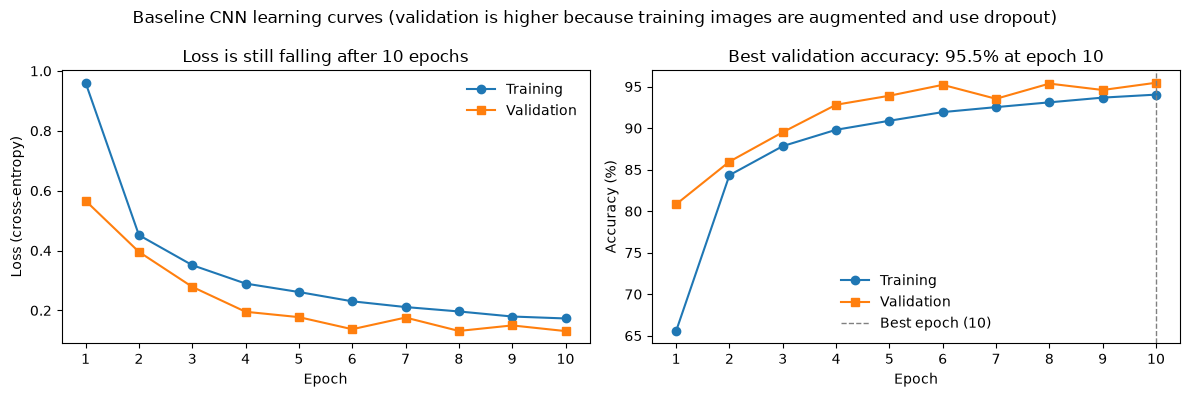

In [48]:
epochs = df_baseline_history["epoch"]                                               # 1 to 10, for the x axis
train_accuracy_percent = df_baseline_history["train_accuracy"] * 100               # 0-1 -> 0-100%
validation_accuracy_percent = df_baseline_history["validation_accuracy"] * 100

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))

# Left: loss per epoch (circles = training, squares = validation, so the lines differ in shape as well as colour)
ax_left.plot(epochs, df_baseline_history["train_loss"], marker="o", label="Training")
ax_left.plot(epochs, df_baseline_history["validation_loss"], marker="s", label="Validation")
ax_left.set_xlabel("Epoch")
ax_left.set_ylabel("Loss (cross-entropy)")
ax_left.set_title("Loss is still falling after 10 epochs")
ax_left.set_xticks(epochs)                                                          # One tick per epoch
ax_left.legend(frameon=False)                                                       # Legend without a border

# Right: accuracy per epoch
ax_right.plot(epochs, train_accuracy_percent, marker="o", label="Training")
ax_right.plot(epochs, validation_accuracy_percent, marker="s", label="Validation")
ax_right.axvline(best_epoch, color="grey", linestyle="--", linewidth=1, label=f"Best epoch ({best_epoch})")   # Dashed line at the best epoch
ax_right.set_xlabel("Epoch")
ax_right.set_ylabel("Accuracy (%)")
ax_right.set_title(f"Best validation accuracy: {best_validation_accuracy * 100:.1f}% at epoch {best_epoch}")
ax_right.set_xticks(epochs)
ax_right.legend(frameon=False)

plt.suptitle("Baseline CNN learning curves (validation is higher because training images are augmented and use dropout)")
plt.tight_layout()                                                                  # Stop the two plots overlapping
plt.savefig(figures_folder / "baseline_learning_curves.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

### 3.7 Predictions on the Kaggle test set

`predict` passes every test batch through the model and keeps the class with the highest score for each image. Like `evaluate`, it uses `model.eval()` and `torch.no_grad()`, so dropout is off and the weights do not change. The test loader is not shuffled, and each batch carries the image IDs, so every prediction stays matched to its image.

In [49]:
def predict(model, loader):
    """Predict a class number for every image in loader. Returns (list of image IDs, list of predicted class numbers)."""
    model.eval()                                                    # Evaluation mode: dropout off, batch norm uses its stored values

    all_image_ids = []                                              # Image IDs in the order they were predicted
    all_predictions = []                                            # Predicted class number (0-7) for each image

    with torch.no_grad():                                           # No gradients needed, which saves time and memory
        for images, image_ids in loader:                            # The test dataset returns (image, image_id)
            images = images.to(DEVICE)                              # Move the batch to the same device as the model
            outputs = model(images)                                 # Forward pass: 8 scores per image
            predictions = torch.argmax(outputs, dim=1)              # Predicted class = index of the biggest score
            all_image_ids.extend(image_ids.tolist())                # .tolist() turns the tensor into plain Python integers
            all_predictions.extend(predictions.tolist())

    return all_image_ids, all_predictions

Load the best baseline weights (epoch 10, 95.47% validation accuracy) into a new `BaselineCNN`, predict every test image, turn the class numbers into names with `index_to_class`, and save the submission file in the same format as `sample_submission.csv`.

In [50]:
# baseline_weights_path is set in the first code cell

best_baseline_model = BaselineCNN().to(DEVICE)                                              # New model with the same layers
best_baseline_model.load_state_dict(torch.load(baseline_weights_path, map_location=DEVICE, weights_only=True))   # Copy in the saved weights
print("Loaded weights from", baseline_weights_path)

start_time = time.perf_counter()
test_image_ids, test_predictions = predict(best_baseline_model, test_loader)               # One class number per test image
print(f"Predicted {len(test_predictions)} test images in {(time.perf_counter() - start_time) / 60:.1f} minutes")

# Turn each class number into its class name, e.g. 0 -> "CatEye"
predicted_class_names = []
for class_number in test_predictions:
    predicted_class_names.append(index_to_class[class_number])

# One row per test image, with the same columns as sample_submission.csv
df_submission_baseline = pd.DataFrame({"image_id": test_image_ids, "class": predicted_class_names})
submission_baseline_path = submissions_folder / "submission_baseline.csv"
df_submission_baseline.to_csv(submission_baseline_path, index=False)                       # index=False: no extra row-number column
print("Saved", submission_baseline_path)
print()
print(df_submission_baseline.head())
print("image_id data type:", df_submission_baseline["image_id"].dtype)

Loaded weights from models/baseline_cnn_best.pt
Predicted 29443 test images in 4.8 minutes
Saved submissions/submission_baseline.csv

   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth
image_id data type: int64


Check the submission file before uploading it to Kaggle: the right number of rows, exactly the test image IDs, only valid class names, and the same column names as the sample submission.

In [51]:
df_check = pd.read_csv(submission_baseline_path)                    # Read the saved file back, to check exactly what Kaggle will receive

def print_check(description, passed):
    """Print PASS or FAIL for one check."""
    if passed:
        print("PASS:", description)
    else:
        print("FAIL:", description)

# 1. One row per test image
print_check(f"{len(df_check)} rows (should be 29,443)", len(df_check) == 29443)

# 2. Exactly the same image IDs as the sample submission
submission_ids = set(df_check["image_id"])
sample_ids = set(df_sample_submission["image_id"])
print_check("same set of image IDs as sample_submission.csv", submission_ids == sample_ids)

# 3. Every class name is one of the 8 classes
all_classes_valid = True
for class_name in df_check["class"]:
    if class_name not in CLASSES:
        all_classes_valid = False
print_check("every class name is in CLASSES", all_classes_valid)

# 4. Same column names, in the same order, as the sample submission
print_check(f"columns {list(df_check.columns)} match sample_submission.csv", list(df_check.columns) == list(df_sample_submission.columns))

PASS: 29443 rows (should be 29,443)
PASS: same set of image IDs as sample_submission.csv
PASS: every class name is in CLASSES
PASS: columns ['image_id', 'class'] match sample_submission.csv


How many test images were predicted as each class. If the model works well and the test set is like the training set, these shares should be close to the class shares in training.

In [52]:
n_test = len(df_submission_baseline)
print(f"{'Class':<10} {'Predicted':>9} {'Predicted %':>12} {'Training %':>11}")
for class_name in CLASSES:
    n_predicted = (df_submission_baseline["class"] == class_name).sum()                   # Test images predicted as this class
    predicted_percent = n_predicted / n_test * 100
    training_percent = (df_train_split["class"] == class_name).sum() / len(df_train_split) * 100   # Share of this class in the training split
    print(f"{class_name:<10} {n_predicted:>9} {predicted_percent:>11.1f}% {training_percent:>10.1f}%")
print(f"{'Total':<10} {n_test:>9}")

Class      Predicted  Predicted %  Training %
CatEye          5705        19.4%       21.8%
CatFace         3178        10.8%       10.9%
CatMouth        3219        10.9%       10.9%
CatNose         2798         9.5%       10.9%
DogEye          5797        19.7%       18.2%
DogFace         2963        10.1%        9.1%
DogMouth        2675         9.1%        9.1%
DogNose         3108        10.6%        9.1%
Total          29443


### 3.8 Transfer learning with a pretrained ResNet-18

**Transfer learning** means starting from a model that has already been trained on a large dataset, instead of from random weights. ResNet-18 was trained on ImageNet (1.2 million photos of 1,000 kinds of object, including many cats and dogs). Its early layers have already learned general features such as edges, colours and textures, and its later layers have learned larger shapes such as eyes, ears and fur patterns. Only the last layer is specific to ImageNet's 1,000 classes, so it is replaced with a new layer that has 8 outputs, one for each facial-feature class.

Training then happens in two stages:
1. **Frozen backbone:** only the new 8-class layer is trained (4,104 weights), while the 11 million pretrained weights stay fixed. The new layer learns to use the pretrained features without damaging them with large early updates.
2. **Fine-tuning:** the whole network is unfrozen and trained with a small learning rate, so the pretrained features adapt to these images.

**Why 128 x 128 pixels instead of 64:** ResNet-18 halves the image size five times, so its last feature maps are 1/32 of the input size. ImageNet images are 224 x 224, which gives 7 x 7 feature maps. A 64 x 64 image would shrink to only 2 x 2, too small to keep the shape of an eye or nose, and the pretrained filters were learned on objects at a much larger scale. At 128 x 128 the feature maps are 4 x 4, and the images are close to their real size (the median training image is 84 x 80), so little detail is invented by enlarging them. 224 x 224 would be about 3 times slower again; the comparison of 128 and 224 px for ResNet-18 is done in Task 4.

The ResNet-18 settings used in `kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb` for the 128 px run (section 3.9). They are kept here because they describe the model, and Task 5 needs them to load the saved weights.

In [53]:
# The settings used in kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb for the 128 px run (section 3.9)
RESNET_IMAGE_SIZE = 128                           # ResNet-18 input size (64 is too small for its 5 halvings, 224 is about 3 times slower)

# Two-stage training (run on a Kaggle GPU in kaggle_resnet18_baseline_notebook.ipynb)
RESNET_FROZEN_EPOCHS = 3                          # Stage 1: train only the new fc layer, backbone frozen
RESNET_FROZEN_LEARNING_RATE = 0.001               # Adam's default: the new layer starts from random weights
RESNET_FINE_TUNE_EPOCHS = 7                       # Stage 2: train the whole network
RESNET_FINE_TUNE_LEARNING_RATE = 0.0001           # 10 times smaller, so the pretrained weights are adjusted gently, not overwritten

print("ResNet-18 image size:", RESNET_IMAGE_SIZE, "x", RESNET_IMAGE_SIZE)
print("Stage 1 (frozen backbone):", RESNET_FROZEN_EPOCHS, "epochs, learning rate", RESNET_FROZEN_LEARNING_RATE)
print("Stage 2 (fine-tuning):    ", RESNET_FINE_TUNE_EPOCHS, "epochs, learning rate", RESNET_FINE_TUNE_LEARNING_RATE)

ResNet-18 image size: 128 x 128
Stage 1 (frozen backbone): 3 epochs, learning rate 0.001
Stage 2 (fine-tuning):     7 epochs, learning rate 0.0001


`build_resnet18` loads ResNet-18 with its ImageNet weights (downloaded the first time, then loaded from the cache) and replaces its 1,000-class output layer, called `fc` ("fully connected"), with a new 8-class layer.

In [54]:
def build_resnet18():
    """ResNet-18 with pretrained ImageNet weights and a new 8-class output layer."""
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)    # ResNet-18 with the best available ImageNet weights
    model.fc = nn.Linear(512, len(CLASSES))                             # The last layer gets 512 features per image; new layer: 512 -> 8 class scores (random starting weights)
    return model

`set_backbone_trainable` freezes or unfreezes the pretrained part of the network (the "backbone", every layer except `fc`). A weight with `requires_grad = False` gets no gradient in `loss.backward()`, so `optimiser.step()` does not change it.

In [55]:
def set_backbone_trainable(model, trainable):
    """Freeze (trainable=False) or unfreeze (trainable=True) every layer except the fc output layer."""
    for name, parameter in model.named_parameters():                    # name is e.g. "layer1.0.conv1.weight" or "fc.weight"
        if not name.startswith("fc"):                                   # Skip the output layer, which is always trained
            parameter.requires_grad = trainable                         # False = frozen (no gradient, no update); True = trained

`count_trainable_weights` counts the weights that will be updated during training, to check the freezing worked.

In [56]:
def count_trainable_weights(model):
    """Return the number of weights with requires_grad = True."""
    trainable_weights = 0
    for parameter in model.parameters():
        if parameter.requires_grad:                                     # Only weights that get gradients are trained
            trainable_weights += parameter.numel()                      # numel() = number of values in the tensor
    return trainable_weights

Test on the CPU without training: build the model, freeze the backbone, count the weights, and pass one batch of 128 x 128 images through it.

In [57]:
torch.manual_seed(RANDOM_SEED)                                                  # Same random starting weights for the new fc layer every run
resnet_test_model = build_resnet18().to(DEVICE)
set_backbone_trainable(resnet_test_model, False)                                # Freeze everything except fc

total_weights = 0
for parameter in resnet_test_model.parameters():
    total_weights += parameter.numel()
trainable_weights = count_trainable_weights(resnet_test_model)

print(f"Total weights:     {total_weights:,}")
print(f"Trainable weights: {trainable_weights:,} (should be 4,104 = 512 x 8 weights + 8 biases)")
print(f"Frozen weights:    {total_weights - trainable_weights:,}")
print()

# The same evaluation steps as Task 2, but resized to RESNET_IMAGE_SIZE
resnet_evaluation_transform = transforms.Compose([
    transforms.Resize((RESNET_IMAGE_SIZE, RESNET_IMAGE_SIZE)),          # 128 x 128 instead of 64 x 64
    transforms.ToTensor(),                                              # PIL image -> 3 x height x width tensor, values 0-1
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),         # Same ImageNet normalisation that ResNet-18 was trained with
])
resnet_check_loader = DataLoader(FacialFeatureDataset(df_validation_split, resnet_evaluation_transform),
                                batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

images, labels = next(iter(resnet_check_loader))                                 # One batch of 64 validation images
images = images.to(DEVICE)

resnet_test_model.eval()                                                        # Evaluation mode, no training here
start_time = time.perf_counter()
with torch.no_grad():                                                           # No gradients needed
    outputs = resnet_test_model(images)
forward_seconds = time.perf_counter() - start_time

print("Input shape: ", tuple(images.shape), "(batch size, channels, height, width)")
print("Output shape:", tuple(outputs.shape), "(batch size, number of classes)")
print(f"Time for one forward pass on the {DEVICE}: {forward_seconds:.1f} seconds")

Total weights:     11,180,616
Trainable weights: 4,104 (should be 4,104 = 512 x 8 weights + 8 biases)
Frozen weights:    11,176,512

Input shape:  (64, 3, 128, 128) (batch size, channels, height, width)
Output shape: (64, 8) (batch size, number of classes)
Time for one forward pass on the cpu: 2.4 seconds


### 3.9 ResNet-18 training on a Kaggle GPU

ResNet-18 was not trained in this notebook: on the laptop CPU a single epoch at 128 x 128 would take more than an hour. It was trained in `kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb` on a Kaggle Notebook GPU (Tesla T4). That notebook is a cut-down copy of this one: it loads the same saved split and uses identical dataset classes, transforms, training, evaluation and prediction functions, and the same ResNet-18 functions and settings as sections 3.3 to 3.8 (3 frozen + 7 fine-tuning epochs, learning rates 0.001 then 0.0001). The real run's output, including the GPU check, every epoch and the submission checks, is in `kaggle_notebooks/resnet-18_notebook_run1_128px.ipynb`.

The files the run wrote were copied here: the history into `results/` and the learning-curve figure into `figures/`, the submission into `submissions/submission_resnet18_128px-imgsize.csv`, and the best weights into `models/resnet18_run1_best.pt` (not in git). The cells below load them.

In [58]:
# Results of the 128 px ResNet-18 run (kaggle_notebooks/resnet-18_notebook_run1_128px.ipynb)
df_resnet_history = pd.read_csv(results_folder / "resnet18_history.csv")          # One row per epoch, both stages
print(df_resnet_history)

# Epoch with the best validation accuracy (its weights are in models/resnet18_run1_best.pt)
best_resnet_index = df_resnet_history["validation_accuracy"].idxmax()
best_resnet_epoch = int(df_resnet_history.loc[best_resnet_index, "epoch"])
best_resnet_accuracy = df_resnet_history.loc[best_resnet_index, "validation_accuracy"]
best_resnet_stage = df_resnet_history.loc[best_resnet_index, "stage"]
print()
print(f"Best validation accuracy: {best_resnet_accuracy * 100:.2f}% at epoch {best_resnet_epoch} ({best_resnet_stage} stage)")
print(f"Total training time: {df_resnet_history['minutes'].sum():.1f} minutes on a Kaggle GPU")

   epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  \
0      1    0.689358        0.760905         0.529752             0.803897   
1      2    0.501092        0.818489         0.495341             0.817253   
2      3    0.472533        0.826816         0.466585             0.826367   
3      4    0.142429        0.949211         0.044460             0.986015   
4      5    0.072882        0.974488         0.034008             0.987272   
5      6    0.054271        0.980773         0.031897             0.988451   
6      7    0.048209        0.982894         0.034231             0.988136   
7      8    0.044823        0.984210         0.032191             0.987901   
8      9    0.039835        0.986193         0.032664             0.987901   
9     10    0.035252        0.987784         0.021316             0.992065   

    minutes      stage  
0  0.952952     frozen  
1  0.928229     frozen  
2  0.914518     frozen  
3  1.083271  fine-tune  
4  1.091893  fin

The learning-curve figure saved by the Kaggle run.

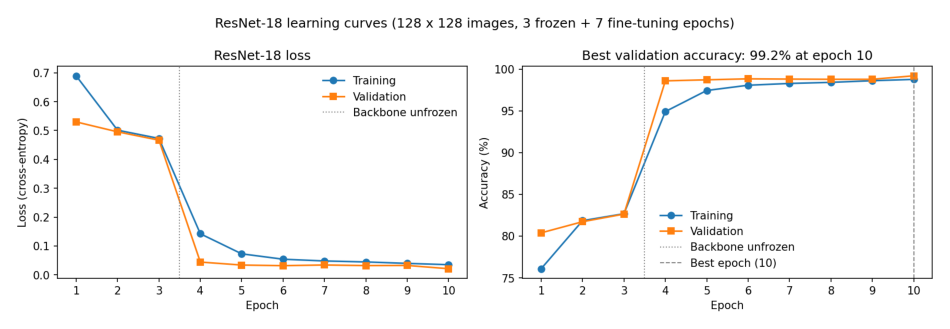

In [59]:
learning_curves_image = Image.open(figures_folder / "resnet18_learning_curves.png")   # Saved by kaggle_resnet18_baseline_notebook.ipynb
plt.figure(figsize=(12, 4.5))
plt.imshow(learning_curves_image)
plt.axis("off")                                                                   # The figure already has its own axes and labels
plt.show()

The same four checks as the baseline submission (3.7), on the ResNet-18 submission file from the Kaggle run.

In [60]:
submission_resnet18_path = submissions_folder / "submission_resnet18_128px-imgsize.csv"   # Written by the 128 px Kaggle run
df_check = pd.read_csv(submission_resnet18_path)                                # Read the file, to check exactly what Kaggle received

print_check(f"{len(df_check)} rows (should be 29,443)", len(df_check) == 29443)

submission_ids = set(df_check["image_id"])
sample_ids = set(df_sample_submission["image_id"])
print_check("same set of image IDs as sample_submission.csv", submission_ids == sample_ids)

all_classes_valid = True
for class_name in df_check["class"]:
    if class_name not in CLASSES:
        all_classes_valid = False
print_check("every class name is in CLASSES", all_classes_valid)

print_check(f"columns {list(df_check.columns)} match sample_submission.csv", list(df_check.columns) == list(df_sample_submission.columns))

PASS: 29443 rows (should be 29,443)
PASS: same set of image IDs as sample_submission.csv
PASS: every class name is in CLASSES
PASS: columns ['image_id', 'class'] match sample_submission.csv


### 3.10 Summary of model and training choices

| Choice | Baseline CNN | ResNet-18 | Reason |
|---|---|---|---|
| Architecture | Custom CNN trained from scratch | ResNet-18 pretrained on ImageNet (transfer learning) | The baseline shows what a small model can learn on its own; the pretrained model starts from features learned on 1.2 million photos |
| Main components | 4 blocks of Conv2d (3 x 3) → BatchNorm2d → ReLU → MaxPool2d (32, 64, 128, 256 filters), then global average pooling and Dropout(0.3) | 4 stages of residual blocks (2 per stage) with batch norm and ReLU, skip connections, then global average pooling | Convolutions find local patterns, pooling shrinks the image, batch norm stabilises training, dropout reduces overfitting; skip connections let the deeper ResNet train well |
| Input size | 3 x 64 x 64 | 3 x 128 x 128 | 64 matches the small images (median 84 x 80) and is fast on a CPU; ResNet-18 halves the size 5 times, so it needs 128 to keep 4 x 4 feature maps |
| Output layer and activation | `Linear(256, 8)` giving raw scores (logits) | New `fc` layer, `Linear(512, 8)`, giving logits | One score per class; softmax is applied inside `CrossEntropyLoss` (and by `torch.softmax` when probabilities are needed), so it is not added to the model |
| Number of classes | 8 | 8 | CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose |
| Loss function | `CrossEntropyLoss` | `CrossEntropyLoss` | The standard loss for choosing one class out of several; the untrained baseline's loss was 2.081, close to the expected ln 8 = 2.079 |
| Optimiser | Adam | Adam (a new optimiser for each stage) | Adapts the step size for each weight, so it works well without much tuning |
| Learning rate | 0.001 | 0.001 with the backbone frozen, then 0.0001 for fine-tuning | 0.001 is Adam's default for weights that start from scratch; 10 times smaller for fine-tuning, so the pretrained weights are adjusted gently instead of overwritten |
| Batch size | 64 | 64 | Small enough for the laptop's memory and gives frequent weight updates (796 batches per epoch) |
| Epochs | 10 (128 minutes on the laptop CPU, about 12.8 minutes per epoch) | 3 frozen + 7 fine-tuning = 10, on a Kaggle GPU (10.4 minutes, about 1 minute per epoch) | The baseline was still improving at epoch 10 but each epoch takes about 13 minutes on the CPU; the same total of 10 epochs keeps the two models comparable |
| Number of weights | 391,432 (all trained) | 11,180,616 (only 4,104 trained while the backbone is frozen) | The baseline is about 29 times smaller, which is why it can be trained on a CPU |
| Best validation accuracy | 95.47% (epoch 10, validation loss 0.131) | 99.21% (epoch 10, fine-tuning stage, validation loss 0.021) | Accuracy is the competition metric, so the weights with the best validation accuracy are kept |
| Kaggle score | 0.9338 (`submission_baseline.csv`) | 0.9728 (`submission_resnet18_128px-imgsize.csv`) | The public leaderboard score on the test images, to compare with the validation accuracy |

## Task 4: Training Strategy and Overfitting/Underfitting Management

Task 4 analyses how the models learned, using training runs that already exist; nothing is retrained in this notebook.

- **Baseline CNN** (section 3.5): 64 x 64 images, 10 epochs on the laptop CPU.
- **Six ResNet-18 runs** on a Kaggle GPU (Tesla T4), all made with `kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb`. Run 1 is the reference: 128 x 128 images, 3 frozen + 7 fine-tuning epochs. Every other run changed exactly one setting from run 1 (checked by comparing the code of the saved run notebooks): runs 3, 4 and 5 changed the image size (224, 96 and 64 px), run 6 changed the number of fine-tuning epochs (17 instead of 7), and run 8 switched off the augmentation of the training images. There are no runs 2 and 7 in `kaggle_notebooks/` (run 7 was not saved).

Because each run changes only one setting, a difference between two runs can be put down to that setting, as long as it is bigger than the normal run-to-run variation (up to about 0.24 percentage points, measured in 4.1).

### 4.1 All ResNet-18 experiment runs

The six ResNet-18 runs made on the Kaggle GPU. Each run's history was copied from its results folder in `kaggle_notebooks/` into `results/` with the run number and setting in its name (for example `resnet18_run4_96px_history.csv`). `RUNS` lists one dictionary per run, and `KAGGLE_SCORES` holds each run's Kaggle public score, filled in by hand (`None` = not submitted yet). The later sections read the runs from here.

In [61]:
KAGGLE_NOTEBOOKS_FOLDER = Path("kaggle_notebooks")              # Run notebooks saved from Kaggle

# One dictionary per ResNet-18 run; each run changed exactly one setting from run 1
RUNS = [
    {"run": 1, "image_size": 128, "frozen_epochs": 3, "fine_tune_epochs": 7, "augmentation": True,
     "history_file": results_folder / "resnet18_run1_128px_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run1_128px.ipynb",
     "description": "Reference run: 128 px, 3 frozen + 7 fine-tuning epochs"},
    {"run": 3, "image_size": 224, "frozen_epochs": 3, "fine_tune_epochs": 7, "augmentation": True,
     "history_file": results_folder / "resnet18_run3_224px_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run3_224px-imgsize.ipynb",
     "description": "Image size 224 px (ImageNet's size)"},
    {"run": 4, "image_size": 96, "frozen_epochs": 3, "fine_tune_epochs": 7, "augmentation": True,
     "history_file": results_folder / "resnet18_run4_96px_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run4_96px-imgsize.ipynb",
     "description": "Image size 96 px"},
    {"run": 5, "image_size": 64, "frozen_epochs": 3, "fine_tune_epochs": 7, "augmentation": True,
     "history_file": results_folder / "resnet18_run5_64px_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run5_64px-imgsize.ipynb",
     "description": "Image size 64 px (the baseline CNN's size)"},
    {"run": 6, "image_size": 128, "frozen_epochs": 3, "fine_tune_epochs": 17, "augmentation": True,
     "history_file": results_folder / "resnet18_run6_128px_20epochs_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run6_128px_20epochs.ipynb",
     "description": "17 fine-tuning epochs instead of 7 (20 in total)"},
    {"run": 8, "image_size": 128, "frozen_epochs": 3, "fine_tune_epochs": 7, "augmentation": False,
     "history_file": results_folder / "resnet18_run8_128px_noaug_history.csv",
     "notebook_file": KAGGLE_NOTEBOOKS_FOLDER / "resnet-18_notebook_run8_128px-noaug.ipynb",
     "description": "No augmentation: training images only resized and normalised (ablation)"},
]

# Kaggle public leaderboard score of each run's submission, by run number (None = not submitted yet)
KAGGLE_SCORES = {
    1: 0.9728,
    3: None,
    4: None,
    5: None,
    6: 0.9747,                                                 # Run 6 is the final model (4.6), submission_resnet18_final.csv
    8: 0.9696,                                                 # Run 8, no augmentation
}
BASELINE_KAGGLE_SCORE = 0.9338                                 # Baseline CNN, submission_baseline.csv

for run in RUNS:
    print(f"Run {run['run']}: {run['description']}")

Run 1: Reference run: 128 px, 3 frozen + 7 fine-tuning epochs
Run 3: Image size 224 px (ImageNet's size)
Run 4: Image size 96 px
Run 5: Image size 64 px (the baseline CNN's size)
Run 6: 17 fine-tuning epochs instead of 7 (20 in total)
Run 8: No augmentation: training images only resized and normalised (ablation)


Load every run's history into the dictionary `run_histories` (run number → dataframe) and check each has one row per epoch.

In [62]:
run_histories = {}                                             # Run number -> its history dataframe
for run in RUNS:
    df_history = pd.read_csv(run["history_file"])              # One row per epoch, both stages
    run_histories[run["run"]] = df_history
    expected_epochs = run["frozen_epochs"] + run["fine_tune_epochs"]
    if len(df_history) == expected_epochs:
        check = "OK"
    else:
        check = f"MISMATCH, expected {expected_epochs}"
    print(f"Run {run['run']} ({run['image_size']} px): {len(df_history)} epochs ({check})")

Run 1 (128 px): 10 epochs (OK)
Run 3 (224 px): 10 epochs (OK)
Run 4 (96 px): 10 epochs (OK)
Run 5 (64 px): 10 epochs (OK)
Run 6 (128 px): 20 epochs (OK)
Run 8 (128 px): 10 epochs (OK)


`summarise_run` works out the numbers used to compare runs from one run's history: the best validation accuracy and its epoch, the validation accuracy at the end of the frozen stage (how much the new `fc` layer learned on its own), the final training accuracy, the lowest validation loss and its epoch, the average minutes per fine-tuning epoch and the total minutes.

In [63]:
def summarise_run(df_history):
    """Return a dictionary of the comparison numbers for one run (accuracies as fractions 0-1)."""
    best_accuracy_index = df_history["validation_accuracy"].idxmax()             # Row with the best validation accuracy
    lowest_loss_index = df_history["validation_loss"].idxmin()                   # Row with the lowest validation loss
    df_frozen = df_history[df_history["stage"] == "frozen"]                      # Epochs with the backbone frozen
    df_fine_tune = df_history[df_history["stage"] == "fine-tune"]                # Epochs with the whole network trained
    last_row = df_history.iloc[len(df_history) - 1]                              # The final epoch

    summary = {}
    summary["best_val_accuracy"] = df_history.loc[best_accuracy_index, "validation_accuracy"]
    summary["best_val_accuracy_epoch"] = int(df_history.loc[best_accuracy_index, "epoch"])
    summary["frozen_end_val_accuracy"] = df_frozen.iloc[len(df_frozen) - 1]["validation_accuracy"]   # Last frozen epoch
    summary["final_train_accuracy"] = last_row["train_accuracy"]
    summary["lowest_val_loss"] = df_history.loc[lowest_loss_index, "validation_loss"]
    summary["lowest_val_loss_epoch"] = int(df_history.loc[lowest_loss_index, "epoch"])
    summary["minutes_per_fine_tune_epoch"] = df_fine_tune["minutes"].mean()
    summary["total_minutes"] = df_history["minutes"].sum()
    return summary

The comparison table, one row per run. The runs with the standard 7 fine-tuning epochs come first, sorted by image size, and runs 6 (17 fine-tuning epochs) and 8 (no augmentation) come last, because they differ in training, not image size.

In [64]:
# Table order: the standard runs (7 fine-tuning epochs, augmentation on), sorted by image size, then the other runs
standard_sizes = []
for run in RUNS:
    if run["fine_tune_epochs"] == RESNET_FINE_TUNE_EPOCHS and run["augmentation"]:   # 7 epochs (settings in 3.8) and augmentation on
        standard_sizes.append(run["image_size"])
standard_sizes.sort()                                                            # Smallest image size first

runs_in_table_order = []
for image_size in standard_sizes:
    for run in RUNS:
        if run["image_size"] == image_size and run["fine_tune_epochs"] == RESNET_FINE_TUNE_EPOCHS and run["augmentation"]:
            runs_in_table_order.append(run)
for run in RUNS:
    if run["fine_tune_epochs"] != RESNET_FINE_TUNE_EPOCHS or not run["augmentation"]:
        runs_in_table_order.append(run)                                          # Runs 6 and 8 last

print(f"{'Run':<4} {'Size':>5} {'Epochs':>7} {'Aug':>4} {'Best val acc':>13} {'Frozen-end val':>15} {'Final train':>12} "
      f"{'Lowest val loss':>16} {'Min/FT epoch':>13} {'Total min':>10} {'Kaggle':>14}")
for run in runs_in_table_order:
    summary = summarise_run(run_histories[run["run"]])
    kaggle_score = KAGGLE_SCORES[run["run"]]
    if kaggle_score is None:
        kaggle_text = "not submitted"
    else:
        kaggle_text = f"{kaggle_score:.4f}"
    epochs_text = f"{run['frozen_epochs']}+{run['fine_tune_epochs']}"
    if run["augmentation"]:
        augmentation_text = "yes"
    else:
        augmentation_text = "no"
    best_text = f"{summary['best_val_accuracy'] * 100:.2f}% (ep {summary['best_val_accuracy_epoch']})"
    loss_text = f"{summary['lowest_val_loss']:.4f} (ep {summary['lowest_val_loss_epoch']})"
    print(f"{run['run']:<4} {run['image_size']:>5} {epochs_text:>7} {augmentation_text:>4} {best_text:>13} {summary['frozen_end_val_accuracy'] * 100:>14.2f}% "
          f"{summary['final_train_accuracy'] * 100:>11.2f}% {loss_text:>16} {summary['minutes_per_fine_tune_epoch']:>13.2f} "
          f"{summary['total_minutes']:>10.1f} {kaggle_text:>14}")
print(f"Baseline CNN Kaggle score: {BASELINE_KAGGLE_SCORE:.4f} | 'ep' = epoch, 'Frozen-end val' = validation accuracy after the last frozen epoch, 'Aug' = training-image augmentation")

Run   Size  Epochs  Aug  Best val acc  Frozen-end val  Final train  Lowest val loss  Min/FT epoch  Total min         Kaggle
5       64     3+7  yes 98.92% (ep 10)          73.83%       98.20%   0.0298 (ep 10)          0.72        7.1  not submitted
4       96     3+7  yes 99.01% (ep 10)          81.68%       98.61%   0.0275 (ep 10)          0.88        8.6  not submitted
1      128     3+7  yes 99.21% (ep 10)          82.64%       98.78%   0.0213 (ep 10)          1.09       10.4         0.9728
3      224     3+7  yes 98.74% (ep 10)          82.31%       98.76%   0.0351 (ep 10)          3.01       26.6  not submitted
6      128    3+17  yes 99.36% (ep 17)          82.64%       99.23%   0.0220 (ep 17)          1.17       23.1         0.9747
8      128     3+7   no 99.29% (ep 8)          88.35%       99.61%    0.0235 (ep 8)          1.10        9.7         0.9696
Baseline CNN Kaggle score: 0.9338 | 'ep' = epoch, 'Frozen-end val' = validation accuracy after the last frozen epoch, 'Aug' = t

Validation accuracy per epoch for all six runs. The frozen epochs (left) and the fine-tuning epochs (right) are drawn in separate panels, because the accuracies are far apart (72-88% while frozen, 98-99.4% while fine-tuning); the right panel's y axis is zoomed to 97-100% so the differences between runs are visible. The dotted line marks where the backbone was unfrozen. Each run has its own colour and marker (the colours were checked for colour-blind readers).

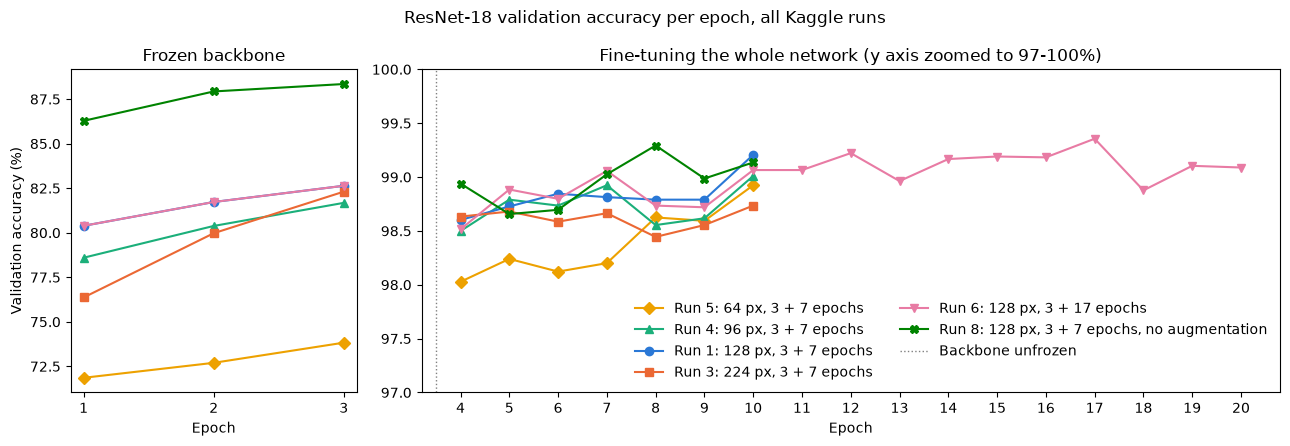

In [65]:
RUN_COLOURS = {1: "#2a78d6", 3: "#eb6834", 4: "#1baf7a", 5: "#eda100", 6: "#e87ba4", 8: "#008300"}   # One fixed colour per run (colour-blind-checked palette)
RUN_MARKERS = {1: "o", 3: "s", 4: "^", 5: "D", 6: "v", 8: "X"}                           # One marker per run, so the lines differ in shape too

# Two panels side by side; the fine-tuning panel is wider because it has more epochs
fig, (ax_frozen, ax_fine_tune) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 3]})

for run in runs_in_table_order:
    df_history = run_histories[run["run"]]
    df_frozen = df_history[df_history["stage"] == "frozen"]                      # Epochs 1-3
    df_fine_tune = df_history[df_history["stage"] == "fine-tune"]                # Epochs 4 onwards
    label = f"Run {run['run']}: {run['image_size']} px, {run['frozen_epochs']} + {run['fine_tune_epochs']} epochs"
    if not run["augmentation"]:
        label = label + ", no augmentation"
    ax_frozen.plot(df_frozen["epoch"], df_frozen["validation_accuracy"] * 100,
                   marker=RUN_MARKERS[run["run"]], color=RUN_COLOURS[run["run"]], label=label)
    ax_fine_tune.plot(df_fine_tune["epoch"], df_fine_tune["validation_accuracy"] * 100,
                      marker=RUN_MARKERS[run["run"]], color=RUN_COLOURS[run["run"]], label=label)

# Left: frozen backbone
ax_frozen.set_title("Frozen backbone")
ax_frozen.set_xlabel("Epoch")
ax_frozen.set_ylabel("Validation accuracy (%)")
ax_frozen.set_xticks(range(1, RESNET_FROZEN_EPOCHS + 1))                         # Epochs 1-3

# Right: fine-tuning, zoomed to 97-100%
ax_fine_tune.axvline(RESNET_FROZEN_EPOCHS + 0.5, color="grey", linestyle=":", linewidth=1, label="Backbone unfrozen")
ax_fine_tune.set_title("Fine-tuning the whole network (y axis zoomed to 97-100%)")
ax_fine_tune.set_xlabel("Epoch")
ax_fine_tune.set_ylim(97, 100)
ax_fine_tune.set_xticks(range(RESNET_FROZEN_EPOCHS + 1, 21))                     # Epochs 4-20
ax_fine_tune.legend(frameon=False, loc="lower right", ncol=2)                    # Two columns, in the empty space below the lines

plt.suptitle("ResNet-18 validation accuracy per epoch, all Kaggle runs")
plt.tight_layout()                                                               # Stop the panels overlapping
plt.savefig(figures_folder / "resnet18_runs_validation_accuracy.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

**Run-to-run noise.** Runs 1 and 6 used exactly the same code, data, seed and settings for their first 10 epochs; run 6 only carried on for 10 more fine-tuning epochs. There is no learning-rate schedule, so the total number of epochs changes nothing before epoch 10. Any difference between the two runs in epochs 1-10 is therefore not caused by a setting: it is run-to-run noise. GPU convolution algorithms are not bit-for-bit repeatable, so two runs with the same seed drift apart slightly once the convolution layers are being trained. This shows how big a difference between two runs has to be before it can be put down to a setting.

In [66]:
df_run1 = run_histories[1]                                                       # 128 px, 3 + 7 epochs
df_run6 = run_histories[6]                                                       # 128 px, 3 + 17 epochs (same settings for epochs 1-10)

total_difference = 0.0                                                           # Sum of the absolute differences, epochs 1-10
fine_tune_difference = 0.0                                                       # Sum of the absolute differences, fine-tuning epochs only
fine_tune_count = 0
largest_difference = 0.0

print(f"{'Epoch':>5} {'Stage':<10} {'Run 1':>8} {'Run 6':>8} {'Run 6 - run 1':>14}")
for row_number in range(len(df_run1)):                                           # Epochs 1-10 (run 1 has 10 epochs)
    epoch = int(df_run1.loc[row_number, "epoch"])
    stage = df_run1.loc[row_number, "stage"]
    accuracy_run1 = df_run1.loc[row_number, "validation_accuracy"] * 100        # As a percentage
    accuracy_run6 = df_run6.loc[row_number, "validation_accuracy"] * 100
    difference = accuracy_run6 - accuracy_run1                                   # In percentage points
    print(f"{epoch:>5} {stage:<10} {accuracy_run1:>7.2f}% {accuracy_run6:>7.2f}% {difference:>+13.3f}")

    total_difference += abs(difference)
    if stage == "fine-tune":
        fine_tune_difference += abs(difference)
        fine_tune_count += 1
    if abs(difference) > largest_difference:
        largest_difference = abs(difference)

print()
print(f"Average absolute difference, epochs 1-10:           {total_difference / len(df_run1):.3f} percentage points")
print(f"Average absolute difference, fine-tuning epochs:    {fine_tune_difference / fine_tune_count:.3f} percentage points")
print(f"Largest absolute difference:                        {largest_difference:.3f} percentage points")

Epoch Stage         Run 1    Run 6  Run 6 - run 1
    1 frozen       80.39%   80.39%        +0.000
    2 frozen       81.73%   81.73%        +0.000
    3 frozen       82.64%   82.64%        +0.000
    4 fine-tune    98.60%   98.52%        -0.086
    5 fine-tune    98.73%   98.88%        +0.157
    6 fine-tune    98.85%   98.80%        -0.047
    7 fine-tune    98.81%   99.06%        +0.244
    8 fine-tune    98.79%   98.74%        -0.055
    9 fine-tune    98.79%   98.72%        -0.071
   10 fine-tune    99.21%   99.07%        -0.141

Average absolute difference, epochs 1-10:           0.080 percentage points
Average absolute difference, fine-tuning epochs:    0.114 percentage points
Largest absolute difference:                        0.244 percentage points


**What this shows:** in the three frozen epochs the two runs are identical, because only the small new `fc` layer is trained and that part repeats exactly. Once the whole network is trained (epoch 4 onwards), the runs drift apart by up to about 0.24 percentage points at a single epoch. So a difference between two runs of a tenth of a point or so is within the noise; a difference needs to be clearly bigger than about 0.24 points before it can be put down to the setting that was changed. This matches the three repeat runs of the 128 px model (99.06%, 99.17% and 99.21% best validation accuracy) described in 4.2.

### 4.2 Image size

Runs 5, 4, 1 and 3 used the same 3 frozen + 7 fine-tuning epochs and changed only the image size (64, 96, 128 and 224 px). The figure shows, against image size:
- **top left:** the best validation accuracy after fine-tuning, with a shaded band of plus or minus the run-to-run noise measured in 4.1 (the largest difference between runs 1 and 6), so differences inside the band could be noise;
- **bottom left:** the validation accuracy at the end of the frozen stage, when only the new `fc` layer had been trained. It is on its own y axis below, because its values (74-83%) are far from the fine-tuned ones (98.7-99.2%) and would make both lines look flat on one axis;
- **right:** the average minutes per fine-tuning epoch on the Kaggle GPU.

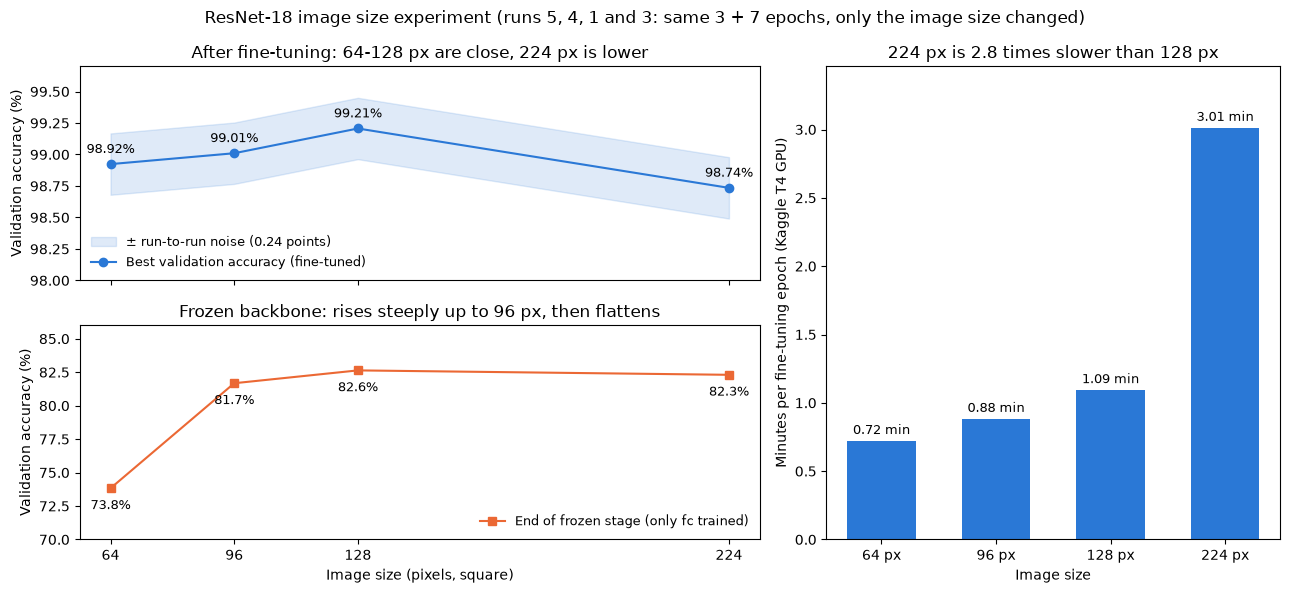

Image size   Best val acc   Frozen-end val acc   Minutes per fine-tuning epoch
    64 px         98.92%               73.83%           0.72
    96 px         99.01%               81.68%           0.88
   128 px         99.21%               82.64%           1.09
   224 px         98.74%               82.31%           3.01
Run-to-run noise estimate: ±0.244 points | 224 px vs 128 px: 2.76 times the time per epoch


In [67]:
# The image size runs: the standard number of fine-tuning epochs, sorted by image size (runs 5, 4, 1, 3)
size_runs = []
for run in runs_in_table_order:
    if run["fine_tune_epochs"] == RESNET_FINE_TUNE_EPOCHS and run["augmentation"]:   # Leaves out runs 6 and 8
        size_runs.append(run)

image_sizes = []                                                                 # 64, 96, 128, 224
best_accuracies = []                                                             # Best validation accuracy after fine-tuning (%)
frozen_end_accuracies = []                                                       # Validation accuracy after the last frozen epoch (%)
minutes_per_epoch = []                                                           # Average minutes per fine-tuning epoch
for run in size_runs:
    summary = summarise_run(run_histories[run["run"]])
    image_sizes.append(run["image_size"])
    best_accuracies.append(summary["best_val_accuracy"] * 100)
    frozen_end_accuracies.append(summary["frozen_end_val_accuracy"] * 100)
    minutes_per_epoch.append(summary["minutes_per_fine_tune_epoch"])

# Band of plus or minus the run-to-run noise around the best accuracies
noise_estimate = largest_difference                                              # Largest run 1 vs run 6 difference from 4.1 (percentage points)
band_low = []
band_high = []
for accuracy in best_accuracies:
    band_low.append(accuracy - noise_estimate)
    band_high.append(accuracy + noise_estimate)

# How much slower 224 px is than 128 px per fine-tuning epoch
for i in range(len(image_sizes)):
    if image_sizes[i] == 128:
        minutes_128px = minutes_per_epoch[i]
    if image_sizes[i] == 224:
        minutes_224px = minutes_per_epoch[i]
slowdown_224px = minutes_224px / minutes_128px

# Layout: two stacked panels on the left (sharing the image size axis), one bar chart on the right
fig = plt.figure(figsize=(13, 6))
grid = fig.add_gridspec(2, 2, width_ratios=[3, 2])
ax_best = fig.add_subplot(grid[0, 0])                                            # Top left
ax_frozen = fig.add_subplot(grid[1, 0], sharex=ax_best)                          # Bottom left, same x axis as the top
ax_time = fig.add_subplot(grid[:, 1])                                            # Right, full height

# Top left: best validation accuracy with the noise band
ax_best.fill_between(image_sizes, band_low, band_high, color="#2a78d6", alpha=0.15,
                     label=f"± run-to-run noise ({noise_estimate:.2f} points)")
ax_best.plot(image_sizes, best_accuracies, marker="o", color="#2a78d6", label="Best validation accuracy (fine-tuned)")
for i in range(len(image_sizes)):
    ax_best.annotate(f"{best_accuracies[i]:.2f}%", (image_sizes[i], best_accuracies[i]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)   # Value just above each point
ax_best.set_ylabel("Validation accuracy (%)")
ax_best.set_ylim(98.0, 99.7)
ax_best.set_title("After fine-tuning: 64-128 px are close, 224 px is lower")
ax_best.legend(frameon=False, loc="lower left", fontsize=9)
ax_best.tick_params(labelbottom=False)                                           # The x labels are shown on the bottom panel only

# Bottom left: validation accuracy at the end of the frozen stage
ax_frozen.plot(image_sizes, frozen_end_accuracies, marker="s", color="#eb6834", label="End of frozen stage (only fc trained)")
for i in range(len(image_sizes)):
    ax_frozen.annotate(f"{frozen_end_accuracies[i]:.1f}%", (image_sizes[i], frozen_end_accuracies[i]),
                       textcoords="offset points", xytext=(0, -15), ha="center", fontsize=9)   # Value just below each point
ax_frozen.set_xlabel("Image size (pixels, square)")
ax_frozen.set_ylabel("Validation accuracy (%)")
ax_frozen.set_ylim(70, 86)
ax_frozen.set_xticks(image_sizes)                                                # One tick per image size
ax_frozen.set_title("Frozen backbone: rises steeply up to 96 px, then flattens")
ax_frozen.legend(frameon=False, loc="lower right", fontsize=9)

# Right: average minutes per fine-tuning epoch as bars
bar_labels = []
for image_size in image_sizes:
    bar_labels.append(f"{image_size} px")
bars = ax_time.bar(bar_labels, minutes_per_epoch, color="#2a78d6", width=0.6)
ax_time.bar_label(bars, fmt="%.2f min", padding=3, fontsize=9)                   # Write the minutes above each bar
ax_time.set_xlabel("Image size")
ax_time.set_ylabel("Minutes per fine-tuning epoch (Kaggle T4 GPU)")
ax_time.set_title(f"224 px is {slowdown_224px:.1f} times slower than 128 px")
ax_time.set_ylim(0, max(minutes_per_epoch) * 1.15)                               # Room for the labels above the bars

plt.suptitle("ResNet-18 image size experiment (runs 5, 4, 1 and 3: same 3 + 7 epochs, only the image size changed)")
plt.tight_layout()                                                               # Stop the panels overlapping
plt.savefig(figures_folder / "resnet18_image_size_comparison.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

print("Image size   Best val acc   Frozen-end val acc   Minutes per fine-tuning epoch")
for i in range(len(image_sizes)):
    print(f"{image_sizes[i]:>6} px   {best_accuracies[i]:>11.2f}%   {frozen_end_accuracies[i]:>17.2f}%   {minutes_per_epoch[i]:>12.2f}")
print(f"Run-to-run noise estimate: ±{noise_estimate:.3f} points | 224 px vs 128 px: {slowdown_224px:.2f} times the time per epoch")

**What the image size experiment shows:**
- **Frozen stage:** with only the new `fc` layer trained, validation accuracy rises steeply from 64 px (73.8%) to 96 px (81.7%) and then flattens (82.6% at 128 px, 82.3% at 224 px). The pretrained ImageNet features need images of about 96 px or more to be useful without any fine-tuning.
- **After fine-tuning:** 64, 96 and 128 px end within about 0.3 points of each other (98.92%, 99.01% and 99.21%), which is close to the run-to-run noise of about ±0.24 points, so fine-tuning lets the network adapt even to small images.
- **224 px** is about 2.8 times slower per epoch than 128 px and not better: at 98.74% it is 0.47 points below 128 px, more than the noise.
- **Conclusion:** about 96-128 px is the best balance between accuracy and training time. This is close to the images' median size of 84 x 80 px (Task 1), so these sizes keep the real detail without enlarging small images much, whereas 224 px mostly enlarges them. Each size was run once, so the ranking of 64, 96 and 128 px is less certain than the gap to 224 px.

#### 128 vs 224 px in detail (the first image size experiment)

**Question:** does ResNet-18 do better at 224 x 224 pixels, the size it was pretrained on (7 x 7 final feature maps), than at 128 x 128 (4 x 4 final feature maps), and is it worth the extra training time?

**Why this is a controlled experiment:** only one variable is changed, `RESNET_IMAGE_SIZE`. Both runs use the same notebook (`kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb`) on the same type of Kaggle GPU (Tesla T4), with the same seed, the same saved split (50,917 training and 12,728 validation images), the same 3 frozen + 7 fine-tuning epochs, the same learning rates (0.001, then 0.0001), batch size 64, augmentation and ImageNet normalisation. So any difference in validation accuracy, loss or training time can be put down to the image size, not to some other change.

**How big a difference matters:** GPU training is not repeatable bit for bit. Three repeat runs of the 128 px model reached 99.06%, 99.17% and 99.21% best validation accuracy (a spread of 0.15 points), and runs 1 and 6, which were identical for their first 10 epochs, differed by up to about 0.24 points at a single epoch (4.1). So a difference between two runs smaller than about 0.24 percentage points could just be run-to-run variation.

The 128 px run is `kaggle_notebooks/resnet-18_notebook_run1_128px.ipynb` and the 224 px run is `kaggle_notebooks/resnet-18_notebook_run3_224px-imgsize.ipynb`. The 224 px run used the same code with only `RESNET_IMAGE_SIZE` changed. Every run of `kaggle_resnet18_baseline_notebook.ipynb` writes the same file names, so each run's output was downloaded into its own `kaggle_notebooks/resnet-18_results_run*` folder, and the 224 px files were renamed by hand with `224px` when they were copied into `results/` (history), `figures/` (learning curves) and `submissions/`. If those files are missing, the cells below print a message and skip.

Settings for the experiment: the history file of each run, and its Kaggle score from `KAGGLE_SCORES` in 4.1 (the 128 px run is run 1 and the 224 px run is run 3).

In [68]:
history_128px_path = results_folder / "resnet18_history.csv"            # 128 px run (kaggle_notebooks/resnet-18_notebook_run1_128px.ipynb)
history_224px_path = results_folder / "resnet18_224px_history.csv"      # 224 px run (kaggle_notebooks/resnet-18_notebook_run3_224px-imgsize.ipynb)

# Kaggle score of each image size, taken from KAGGLE_SCORES in 4.1 (keyed by run number)
KAGGLE_SCORES_BY_SIZE = {
    128: KAGGLE_SCORES[1],                                              # Run 1, submission_resnet18_128px-imgsize.csv
    224: KAGGLE_SCORES[3],                                              # Run 3, submission_resnet18_224px-imgsize.csv
}

print("128 px history:", history_128px_path, "| exists:", history_128px_path.exists())
print("224 px history:", history_224px_path, "| exists:", history_224px_path.exists())

128 px history: results/resnet18_history.csv | exists: True
224 px history: results/resnet18_224px_history.csv | exists: True


Load both histories. If either file is missing, `size_experiment_ready` is `False` and the comparison cells skip instead of failing.

In [69]:
if history_128px_path.exists() and history_224px_path.exists():
    df_history_128px = pd.read_csv(history_128px_path)                  # One row per epoch, both stages
    df_history_224px = pd.read_csv(history_224px_path)
    size_experiment_ready = True
    print(f"Loaded {len(df_history_128px)} epochs at 128 px and {len(df_history_224px)} epochs at 224 px")
else:
    size_experiment_ready = False
    for path in [history_128px_path, history_224px_path]:
        if not path.exists():
            print("Missing:", path)
    print("Skipping the image size comparison until both history files are in figures/.")
    print("Copy the 224 px history from kaggle_notebooks/resnet-18_results_run3_224px-imgsize/figures/ into results/ as resnet18_224px_history.csv.")

Loaded 10 epochs at 128 px and 10 epochs at 224 px


`summarise_size_run` works out the comparison numbers for one run: the best validation accuracy and its epoch, the final training and validation loss, the time per epoch and in total, and the Kaggle score.

In [70]:
def summarise_size_run(df_history, image_size):
    """Return a dictionary of the comparison numbers for one image size (each value already formatted as text)."""
    best_index = df_history["validation_accuracy"].idxmax()                    # Row with the best validation accuracy
    last_row = df_history.iloc[len(df_history) - 1]                            # The final epoch

    summary = {}                                                                # Each key becomes one row of the table
    summary["Best validation accuracy"] = f"{df_history.loc[best_index, 'validation_accuracy'] * 100:.2f}%"
    summary["Best epoch"] = f"{int(df_history.loc[best_index, 'epoch'])} ({df_history.loc[best_index, 'stage']})"
    summary["Final training loss"] = f"{last_row['train_loss']:.4f}"
    summary["Final validation loss"] = f"{last_row['validation_loss']:.4f}"
    summary["Average minutes per epoch"] = f"{df_history['minutes'].mean():.2f}"
    summary["Total minutes"] = f"{df_history['minutes'].sum():.1f}"

    kaggle_score = KAGGLE_SCORES_BY_SIZE[image_size]
    if kaggle_score is None:
        summary["Kaggle score"] = "not submitted"
    else:
        summary["Kaggle score"] = f"{kaggle_score:.4f}"
    return summary

The comparison table, one column per image size.

In [71]:
if size_experiment_ready:
    summary_128px = summarise_size_run(df_history_128px, 128)
    summary_224px = summarise_size_run(df_history_224px, 224)

    print(f"{'':<27} {'128 px':>15} {'224 px':>15}")
    for name in summary_128px:                                                  # One row per summary number
        print(f"{name:<27} {summary_128px[name]:>15} {summary_224px[name]:>15}")
else:
    print("Skipped: the 224 px history is not in figures/ yet.")

                                     128 px          224 px
Best validation accuracy             99.21%          98.74%
Best epoch                   10 (fine-tune)  10 (fine-tune)
Final training loss                  0.0353          0.0351
Final validation loss                0.0213          0.0351
Average minutes per epoch              1.04            2.66
Total minutes                          10.4            26.6
Kaggle score                         0.9728   not submitted


Validation accuracy (left) and validation loss (right) per epoch for both image sizes on the same axes. The dotted line marks where the backbone was unfrozen.

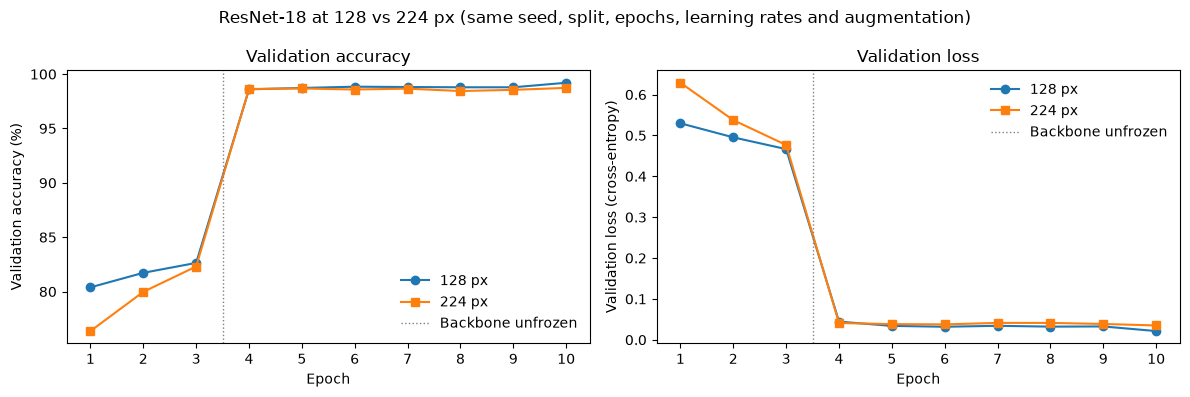

In [72]:
if size_experiment_ready:
    unfreeze_position = RESNET_FROZEN_EPOCHS + 0.5                              # Between the last frozen epoch and the first fine-tuning epoch

    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))

    # Left: validation accuracy per epoch (circles = 128 px, squares = 224 px)
    ax_left.plot(df_history_128px["epoch"], df_history_128px["validation_accuracy"] * 100, marker="o", label="128 px")
    ax_left.plot(df_history_224px["epoch"], df_history_224px["validation_accuracy"] * 100, marker="s", label="224 px")
    ax_left.axvline(unfreeze_position, color="grey", linestyle=":", linewidth=1, label="Backbone unfrozen")
    ax_left.set_xlabel("Epoch")
    ax_left.set_ylabel("Validation accuracy (%)")
    ax_left.set_title("Validation accuracy")
    ax_left.set_xticks(df_history_128px["epoch"])                               # One tick per epoch
    ax_left.legend(frameon=False)                                               # Legend without a border

    # Right: validation loss per epoch
    ax_right.plot(df_history_128px["epoch"], df_history_128px["validation_loss"], marker="o", label="128 px")
    ax_right.plot(df_history_224px["epoch"], df_history_224px["validation_loss"], marker="s", label="224 px")
    ax_right.axvline(unfreeze_position, color="grey", linestyle=":", linewidth=1, label="Backbone unfrozen")
    ax_right.set_xlabel("Epoch")
    ax_right.set_ylabel("Validation loss (cross-entropy)")
    ax_right.set_title("Validation loss")
    ax_right.set_xticks(df_history_128px["epoch"])
    ax_right.legend(frameon=False)

    plt.suptitle("ResNet-18 at 128 vs 224 px (same seed, split, epochs, learning rates and augmentation)")
    plt.tight_layout()                                                          # Stop the two plots overlapping
    plt.savefig(figures_folder / "resnet18_size_comparison.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
    plt.show()
else:
    print("Skipped: the 224 px history is not in figures/ yet.")

### 4.3 Overfitting and underfitting

- **Underfitting:** the model has not finished learning. Training and validation loss are both still falling at the last epoch, and validation accuracy is still improving, so more training (or a bigger model) would help.
- **Overfitting:** the model starts memorising the training images. Training loss keeps falling, but validation loss reaches a minimum and then rises for several epochs in a row, and the gap between them (validation loss minus training loss) grows.

`diagnose` prints the numbers that show which, if either, is happening for one model.

In [73]:
def diagnose(df_history, name):
    """Print the signs of overfitting or underfitting in one model's training history."""
    lowest_index = df_history["validation_loss"].idxmin()                       # Row with the lowest validation loss
    lowest_epoch = int(df_history.loc[lowest_index, "epoch"])
    last_row = df_history.iloc[len(df_history) - 1]                             # The final epoch

    # Longest run of epochs in a row where validation loss went up, after its minimum
    longest_rise = 0
    current_rise = 0
    for row_number in range(lowest_index + 1, len(df_history)):
        if df_history.loc[row_number, "validation_loss"] > df_history.loc[row_number - 1, "validation_loss"]:
            current_rise += 1                                                   # One more rise in a row
            if current_rise > longest_rise:
                longest_rise = current_rise
        else:
            current_rise = 0                                                    # The rise has ended
    if lowest_index == len(df_history) - 1:
        rise_text = "no (the minimum is at the last epoch)"
    elif longest_rise >= 2:
        rise_text = f"YES, for {longest_rise} epochs in a row"
    else:
        rise_text = f"no (longest rise in a row: {longest_rise} epoch)"

    # Did validation accuracy reach a new best in the last 3 epochs?
    best_before_last_3 = df_history["validation_accuracy"].iloc[0:len(df_history) - 3].max()
    best_in_last_3 = df_history["validation_accuracy"].iloc[len(df_history) - 3:len(df_history)].max()
    if best_in_last_3 > best_before_last_3:
        improved_text = f"yes ({best_in_last_3 * 100:.2f}%, up from {best_before_last_3 * 100:.2f}% before)"
    else:
        improved_text = f"no (best in the last 3 epochs {best_in_last_3 * 100:.2f}%, best before {best_before_last_3 * 100:.2f}%)"

    final_gap = last_row["validation_loss"] - last_row["train_loss"]            # Positive = validation loss above training loss

    print(f"=== {name} ({len(df_history)} epochs) ===")
    print(f"Lowest validation loss:                             {df_history.loc[lowest_index, 'validation_loss']:.4f} at epoch {lowest_epoch}")
    print(f"Validation loss rose 2+ epochs in a row after that: {rise_text}")
    print(f"Final training loss / validation loss:              {last_row['train_loss']:.4f} / {last_row['validation_loss']:.4f}")
    print(f"Final training accuracy / validation accuracy:      {last_row['train_accuracy'] * 100:.2f}% / {last_row['validation_accuracy'] * 100:.2f}%")
    print(f"Final gap (validation loss - training loss):        {final_gap:+.4f}")
    print(f"Validation accuracy improved in the last 3 epochs:  {improved_text}")
    print()

Run the diagnosis for the baseline CNN (section 3.5) and for ResNet-18 run 6, the longest run (20 epochs), where overfitting would be most likely to show.

In [74]:
diagnose(df_baseline_history, "Baseline CNN")                                    # 64 px, 10 epochs on the laptop CPU
diagnose(run_histories[6], "ResNet-18 run 6")                                   # 128 px, 3 frozen + 17 fine-tuning epochs

=== Baseline CNN (10 epochs) ===
Lowest validation loss:                             0.1310 at epoch 10
Validation loss rose 2+ epochs in a row after that: no (the minimum is at the last epoch)
Final training loss / validation loss:              0.1731 / 0.1310
Final training accuracy / validation accuracy:      94.04% / 95.47%
Final gap (validation loss - training loss):        -0.0422
Validation accuracy improved in the last 3 epochs:  yes (95.47%, up from 95.22% before)

=== ResNet-18 run 6 (20 epochs) ===
Lowest validation loss:                             0.0220 at epoch 17
Validation loss rose 2+ epochs in a row after that: no (longest rise in a row: 1 epoch)
Final training loss / validation loss:              0.0225 / 0.0233
Final training accuracy / validation accuracy:      99.23% / 99.09%
Final gap (validation loss - training loss):        +0.0008
Validation accuracy improved in the last 3 epochs:  no (best in the last 3 epochs 99.10%, best before 99.36%)



The same two models as learning curves: one row per model. Left, training and validation loss per epoch; right, the gap (validation loss minus training loss) per epoch, with a line at zero. Below zero, the validation loss is lower than the training loss. For run 6 the dotted line marks where the backbone was unfrozen.

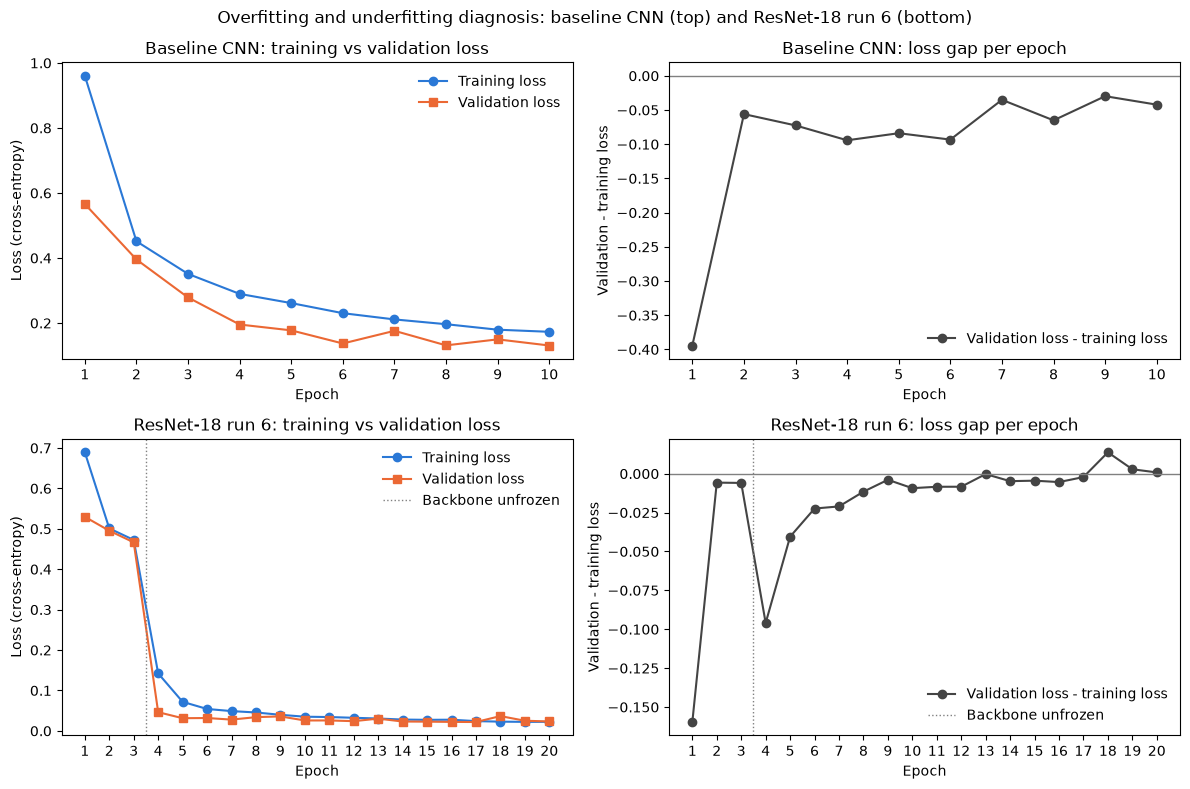

In [75]:
diagnosis_models = [
    {"name": "Baseline CNN", "history": df_baseline_history, "unfreeze_epoch": None},          # No frozen stage
    {"name": "ResNet-18 run 6", "history": run_histories[6], "unfreeze_epoch": RESNET_FROZEN_EPOCHS},
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row_number in range(len(diagnosis_models)):
    model = diagnosis_models[row_number]
    df_history = model["history"]
    ax_loss = axes[row_number][0]                                                # Left column
    ax_gap = axes[row_number][1]                                                 # Right column

    # Gap per epoch: validation loss minus training loss
    gaps = []
    for i in range(len(df_history)):
        gaps.append(df_history.loc[i, "validation_loss"] - df_history.loc[i, "train_loss"])

    # Left: training vs validation loss (circles = training, squares = validation)
    ax_loss.plot(df_history["epoch"], df_history["train_loss"], marker="o", color="#2a78d6", label="Training loss")
    ax_loss.plot(df_history["epoch"], df_history["validation_loss"], marker="s", color="#eb6834", label="Validation loss")
    ax_loss.set_title(f"{model['name']}: training vs validation loss")
    ax_loss.set_ylabel("Loss (cross-entropy)")

    # Right: the gap, with a zero line
    ax_gap.plot(df_history["epoch"], gaps, marker="o", color="#444444", label="Validation loss - training loss")
    ax_gap.axhline(0, color="grey", linewidth=1)                                 # Zero line: above it, validation loss is higher
    ax_gap.set_title(f"{model['name']}: loss gap per epoch")
    ax_gap.set_ylabel("Validation - training loss")

    for ax in [ax_loss, ax_gap]:
        ax.set_xlabel("Epoch")
        ax.set_xticks(df_history["epoch"])                                      # One tick per epoch
        if model["unfreeze_epoch"] is not None:
            ax.axvline(model["unfreeze_epoch"] + 0.5, color="grey", linestyle=":", linewidth=1, label="Backbone unfrozen")
        ax.legend(frameon=False)

plt.suptitle("Overfitting and underfitting diagnosis: baseline CNN (top) and ResNet-18 run 6 (bottom)")
plt.tight_layout()                                                               # Stop the panels overlapping
plt.savefig(figures_folder / "overfitting_diagnosis.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

**Diagnosis**

- **Baseline CNN: mild underfitting.** Its lowest validation loss (0.131) is at the last epoch, and validation accuracy was still reaching new bests at the end (95.47% at epoch 10, up from 95.22% before the last 3 epochs). Training loss was still falling too (0.173 at epoch 10), so the model had not finished learning when training stopped; more epochs would probably have helped. Validation loss is below training loss in every epoch (final gap -0.042) and validation accuracy is above training accuracy (95.47% vs 94.04%). This is not a sign of a problem: training images are made harder by augmentation and dropout is switched on during training, while validation images are clean and dropout is off.
- **ResNet-18 run 6: converged, no clear overfitting.** Validation accuracy levelled off at about 99.0-99.4% from around epoch 7 (short dips to 98.7-99.0% at epochs 8-9, 13 and 18). The lowest validation loss is at epoch 17 (0.022), and after it validation loss rose for only one epoch (to 0.037 at epoch 18) before falling again, so there is no sustained rise. At the end the training and validation loss are almost equal (0.0225 and 0.0233, gap +0.001), and validation accuracy did not improve in the last 3 epochs. The model had learned what it could with this setup. The last three epochs are the first where validation loss is slightly above training loss (by 0.014, 0.003 and 0.001): this is the point where more training would start to overfit, but the gap is tiny and not growing, so it is not overfitting yet.

**What overfitting would have looked like on these plots:** on the left, the training loss would keep falling while the validation loss turned upwards and kept rising for several epochs, so the two curves would move apart. On the right, the gap would cross above zero and keep climbing epoch after epoch instead of staying close to zero. Validation accuracy would also fall while training accuracy kept rising. None of this happens for either model: the baseline stopped too early to overfit, and from epoch 8 onwards run 6's gap stays within about ±0.015 and does not keep growing.

### 4.4 Strategies to improve generalisation

All nine strategies in the brief, with where each one was used, the exact setting in the code, and the evidence for it (or, if it was not used, the reason).

| Strategy | Used in | How (exact setting) | Evidence or reason |
|---|---|---|---|
| Data augmentation | Baseline and ResNet-18 | Training images only (2.5, 3.9): `RandomResizedCrop(scale=(0.8, 1.0))`, `RandomHorizontalFlip()`, `RandomRotation(15)`, `ColorJitter(brightness=0.2, contrast=0.2)`, `RandomGrayscale(p=0.1)`. Validation and test images are only resized and normalised. | Training accuracy stays below validation accuracy: baseline 94.04% vs 95.47% at epoch 10, ResNet-18 run 1 98.78% vs 99.21%. The augmented training images are harder than the clean validation images, so the models do not memorise them (4.3). Random greyscale stops the shortcut "greyscale means cat" (1,001 of the 1,011 greyscale training images are cats, Task 1). Switching it off (run 8, otherwise identical to run 1) kept the best validation accuracy the same within the noise (99.29% vs 99.21%), but the training loss fell to 0.011 (vs 0.035) and validation loss stayed above training loss in every fine-tuning epoch from epoch 5 (final gap +0.017 vs -0.014): without augmentation ResNet-18 starts to overfit, and it scored 0.32 points lower on Kaggle (0.9696 vs 0.9728; comparison below). |
| Dropout | Baseline only | `nn.Dropout(0.3)` before the final `Linear(256, 8)` (3.1). ResNet-18 has no dropout layer. | The baseline's validation loss is below its training loss in every epoch (final gap -0.042, 4.3). ResNet-18 did not overfit without dropout either (run 6 final gap +0.001), so none was added. Possible improvement for Task 6 if longer training starts to overfit. |
| Weight decay | Neither | Adam with its default `weight_decay=0` in both models. | No overfitting was seen in any run with augmentation: validation loss never rose for 2 or more epochs in a row after its minimum and stayed at or below training loss (4.3), so there was nothing for it to correct. The only early sign was in run 8, without augmentation. Possible improvement for Task 6, for example AdamW with a small weight decay, if more epochs are used. |
| Batch normalisation | Baseline and ResNet-18 | Baseline: `BatchNorm2d` after each of its 4 convolutions (3.1). ResNet-18: 20 pretrained `BatchNorm2d` layers built in; they keep updating their running averages even while the backbone is frozen, because the model is in training mode. | Both models trained stably at a learning rate of 0.001: the training loss fell in every single epoch, from 0.960 to 0.173 for the baseline and from 0.689 to 0.035 for ResNet-18 run 1. |
| Early stopping | Baseline and ResNet-18 (as best-checkpoint saving) | No patience rule: every run trains for all its epochs, but `train_model` saves the weights whenever validation accuracy beats the best so far, and that checkpoint is used for predictions (3.4). | It protects against a bad last epoch: run 6's best was epoch 17 (99.36%) and epoch 18 dropped to 98.88%, but the epoch 17 checkpoint was kept. A patience rule (stop after 3 epochs without a new best) would have stopped run 6 after epoch 15 with 99.22% (epoch 12), only 0.14 points lower (within the noise) and 5 epochs shorter. Possible improvement for Task 6 to save training time. |
| Learning-rate scheduling | ResNet-18 (one manual drop only) | No scheduler. Stage 1 trains the new `fc` layer with Adam at 0.001; stage 2 starts a new Adam at 0.0001 when the backbone is unfrozen. The rate is constant within each stage, and the baseline uses a constant 0.001. | The 10 times smaller rate lets the pretrained weights adapt without being overwritten: validation accuracy jumped from 82.64% to 98.60% in the first fine-tuning epoch (run 1). Afterwards run 6 levelled off at about 99.0-99.4% from epoch 7, so a gradual schedule (for example cosine decay or ReduceLROnPlateau) is a possible improvement for Task 6. |
| Transfer learning | ResNet-18 | `models.resnet18(weights=models.ResNet18_Weights.DEFAULT)` (ImageNet weights) with a new `fc = nn.Linear(512, 8)` (3.8). | With only the new `fc` layer trained (4,104 of 11,180,616 weights), run 1 reached 82.64% validation accuracy in 3 epochs using the ImageNet features unchanged. After fine-tuning it reached 99.21%, against the baseline's 95.47% trained from scratch. |
| Fine-tuning | ResNet-18 | After 3 frozen epochs, `set_backbone_trainable(model, True)` unfreezes all 11,180,616 weights, which are trained for 7 more epochs (17 in run 6) at 0.0001 (3.9). | Validation accuracy rose from 82.64% to 98.60% in the first fine-tuning epoch and to 99.21% by epoch 10 (run 1). At 64 px it lifted the frozen 73.83% to 98.92% (4.2). |
| Model adjustment | Both (changes between runs) | Baseline CNN (391,432 weights) replaced by ResNet-18 (11,180,616); image size tried at 64, 96, 128 and 224 px; fine-tuning epochs 7 and 17 (4.1, 4.2). | The baseline was underfitting at epoch 10 and took 12.8 minutes per epoch on the CPU. ResNet-18 reached 99.21% (Kaggle 0.9728 vs 0.9338). 128 px was the best size; 224 px was 0.47 points lower and 2.8 times slower. 17 fine-tuning epochs added 0.15 points, within the noise. See 4.5. |

**Augmentation ablation: run 1 vs run 8.** The two runs are identical (128 px, 3 frozen + 7 fine-tuning epochs, same seed, split and learning rates) except that run 8 trained on images that were only resized and normalised, like the validation images. The figure shows training and validation accuracy (left) and loss (right) for the 7 fine-tuning epochs, where the difference shows; the frozen epochs are in the printout below it. Colour = run, dashed line and circles = training, solid line and squares = validation.

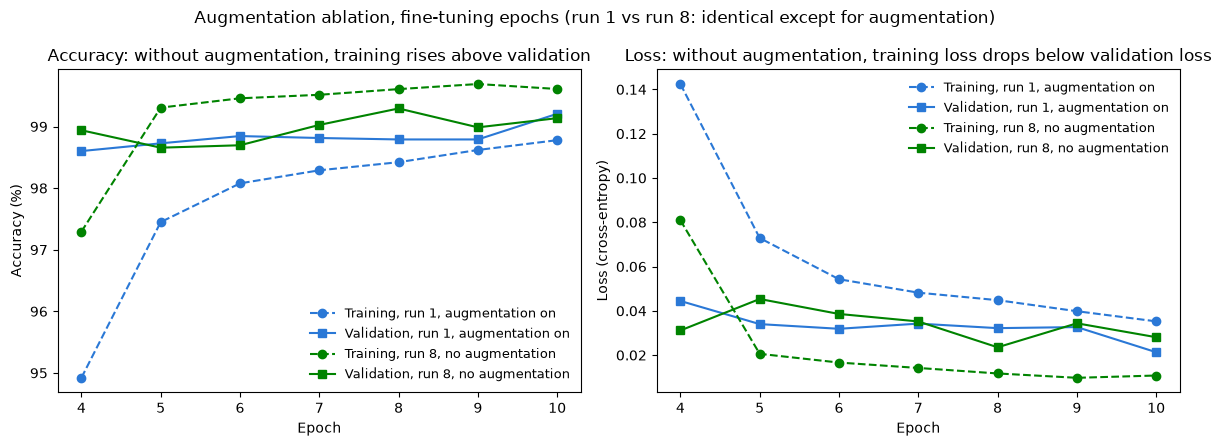

Epoch Stage       Gap, run 1  Gap, run 8
    1 frozen         -0.1596     -0.1806
    2 frozen         -0.0058     -0.0367
    3 frozen         -0.0059     -0.0120
    4 fine-tune      -0.0980     -0.0498
    5 fine-tune      -0.0389     +0.0248
    6 fine-tune      -0.0224     +0.0219
    7 fine-tune      -0.0140     +0.0210
    8 fine-tune      -0.0126     +0.0118
    9 fine-tune      -0.0072     +0.0246
   10 fine-tune      -0.0139     +0.0173

=== ResNet-18 run 1 (augmentation on) (10 epochs) ===
Lowest validation loss:                             0.0213 at epoch 10
Validation loss rose 2+ epochs in a row after that: no (the minimum is at the last epoch)
Final training loss / validation loss:              0.0353 / 0.0213
Final training accuracy / validation accuracy:      98.78% / 99.21%
Final gap (validation loss - training loss):        -0.0139
Validation accuracy improved in the last 3 epochs:  yes (99.21%, up from 98.85% before)

=== ResNet-18 run 8 (no augmentation) (10 epochs

In [76]:
ablation_runs = [1, 8]                                                           # 1 = augmentation on, 8 = augmentation off
ABLATION_LABELS = {1: "run 1, augmentation on", 8: "run 8, no augmentation"}

fig, (ax_accuracy, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.5))
for run_number in ablation_runs:
    df_history = run_histories[run_number]
    df_fine_tune = df_history[df_history["stage"] == "fine-tune"]                # Epochs 4-10
    colour = RUN_COLOURS[run_number]                                             # Same colour as in the 4.1 figure
    ax_accuracy.plot(df_fine_tune["epoch"], df_fine_tune["train_accuracy"] * 100, color=colour, linestyle="--", marker="o",
                     label=f"Training, {ABLATION_LABELS[run_number]}")
    ax_accuracy.plot(df_fine_tune["epoch"], df_fine_tune["validation_accuracy"] * 100, color=colour, linestyle="-", marker="s",
                     label=f"Validation, {ABLATION_LABELS[run_number]}")
    ax_loss.plot(df_fine_tune["epoch"], df_fine_tune["train_loss"], color=colour, linestyle="--", marker="o",
                 label=f"Training, {ABLATION_LABELS[run_number]}")
    ax_loss.plot(df_fine_tune["epoch"], df_fine_tune["validation_loss"], color=colour, linestyle="-", marker="s",
                 label=f"Validation, {ABLATION_LABELS[run_number]}")

ax_accuracy.set_title("Accuracy: without augmentation, training rises above validation")
ax_accuracy.set_xlabel("Epoch")
ax_accuracy.set_ylabel("Accuracy (%)")
ax_accuracy.legend(frameon=False, fontsize=9)
ax_loss.set_title("Loss: without augmentation, training loss drops below validation loss")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Loss (cross-entropy)")
ax_loss.legend(frameon=False, fontsize=9)

plt.suptitle("Augmentation ablation, fine-tuning epochs (run 1 vs run 8: identical except for augmentation)")
plt.tight_layout()                                                               # Stop the panels overlapping
plt.savefig(figures_folder / "augmentation_ablation.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

# Loss gap per epoch (validation loss minus training loss) for both runs
print(f"{'Epoch':>5} {'Stage':<10} {'Gap, run 1':>11} {'Gap, run 8':>11}")
df_run1 = run_histories[1]
df_run8 = run_histories[8]
for row_number in range(len(df_run1)):
    gap_run1 = df_run1.loc[row_number, "validation_loss"] - df_run1.loc[row_number, "train_loss"]
    gap_run8 = df_run8.loc[row_number, "validation_loss"] - df_run8.loc[row_number, "train_loss"]
    print(f"{int(df_run1.loc[row_number, 'epoch']):>5} {df_run1.loc[row_number, 'stage']:<10} {gap_run1:>+11.4f} {gap_run8:>+11.4f}")
print()

# The same diagnosis as in 4.3, including the final gap
diagnose(run_histories[1], "ResNet-18 run 1 (augmentation on)")
diagnose(run_histories[8], "ResNet-18 run 8 (no augmentation)")

Validation accuracy against the Kaggle public score for every submitted model, and the gap between them (best validation accuracy minus Kaggle score, in percentage points).

In [77]:
KAGGLE_COMPARISON_RUNS = [1, 6, 8]                                              # The ResNet-18 runs that have been submitted

print(f"{'Model':<36} {'Best val acc':>12} {'Kaggle':>8} {'Gap (val - Kaggle)':>19}")
baseline_best = df_baseline_history["validation_accuracy"].max() * 100           # Baseline CNN, section 3.5
print(f"{'Baseline CNN':<36} {baseline_best:>11.2f}% {BASELINE_KAGGLE_SCORE * 100:>7.2f}% {baseline_best - BASELINE_KAGGLE_SCORE * 100:>18.2f}")
for run_number in KAGGLE_COMPARISON_RUNS:
    run_summary = summarise_run(run_histories[run_number])
    best_accuracy = run_summary["best_val_accuracy"] * 100                       # As a percentage
    kaggle_percent = KAGGLE_SCORES[run_number] * 100                             # Kaggle score as a percentage
    for run in RUNS:
        if run["run"] == run_number:
            this_run = run                                                       # The run's settings from 4.1
    if this_run["augmentation"]:
        augmentation_text = "augmentation"
    else:
        augmentation_text = "no augmentation"
    label = f"Run {run_number}: {this_run['image_size']} px, {this_run['frozen_epochs']}+{this_run['fine_tune_epochs']}, {augmentation_text}"
    print(f"{label:<36} {best_accuracy:>11.2f}% {kaggle_percent:>7.2f}% {best_accuracy - kaggle_percent:>18.2f}")
print("Gap in percentage points. The Kaggle public leaderboard scores only part of the test set.")

Model                                Best val acc   Kaggle  Gap (val - Kaggle)
Baseline CNN                               95.47%   93.38%               2.09
Run 1: 128 px, 3+7, augmentation           99.21%   97.28%               1.93
Run 6: 128 px, 3+17, augmentation          99.36%   97.47%               1.89
Run 8: 128 px, 3+7, no augmentation        99.29%   96.96%               2.33
Gap in percentage points. The Kaggle public leaderboard scores only part of the test set.


**What switching augmentation off shows:**
- **Validation accuracy:** the same within the noise: 99.29% at epoch 8 without augmentation, 99.21% with it (0.08 points apart, inside the ±0.24 noise).
- **Training fit:** without augmentation the model fits the training images much more closely: final training loss 0.0108 vs 0.0353, training accuracy 99.61% vs 98.78%.
- **The loss gap changes sign:** with augmentation, validation loss is below training loss in every epoch (final gap -0.014). Without it, validation loss is above training loss in every fine-tuning epoch from epoch 5 (by 0.012 to 0.025; final gap +0.017), and the final validation loss is higher (0.0281 vs 0.0213). This is the first sign of overfitting: the model is starting to learn the particular training images rather than features that carry over to new ones. It has not yet hurt validation accuracy in 10 epochs; with longer training the gap might keep growing.
- **Frozen stage:** without augmentation the frozen stage reaches 88.35% instead of 82.64%, because the training images then look exactly like the validation images.
- **Kaggle test score:** run 8 tied run 1 on validation (99.29% vs 99.21%) but scored 0.32 points lower on Kaggle (0.9696 vs 0.9728), with the largest gap between validation accuracy and Kaggle score of all the submitted models (2.33 points, table above). This is consistent with augmentation reducing overfitting to individual animals: without it the model fits the particular training images more closely, which helps less on new test images. The difference is close to the noise, though: identical training runs differ by up to about 0.24 points, and the public leaderboard scores only part of the test set, so one pair of runs cannot prove it.
- **Conclusion:** within 10 epochs augmentation does not raise validation accuracy, but it keeps validation loss at or below training loss and gave the better Kaggle score, so it acts as a regulariser and was kept.

### 4.5 Changes made and why

Every change, in the order it was made, with the evidence that prompted it and its effect (numbers from the comparison table in 4.1; ResNet-18 times are on a Kaggle Tesla T4 GPU, the baseline's on the laptop CPU).

| # | Change | Reason (evidence that prompted it) | Effect on best validation accuracy and training time |
|---|---|---|---|
| 1 | Baseline CNN at 64 px, trained on the laptop CPU (3.5) | A small model trained from scratch as a reference. 64 px suits the small images (median 84 x 80 px, Task 1) and keeps CPU training practical. | 95.47% at epoch 10; 128.1 minutes (12.8 per epoch); Kaggle 0.9338. |
| 2 | ResNet-18 at 128 px on a Kaggle GPU (run 1) | The baseline was still improving at epoch 10 (underfitting, 4.3), but each CPU epoch took 12.8 minutes, so more epochs or a bigger model were not practical on the laptop. A pretrained model brings features learned on ImageNet, and 128 px gives ResNet-18 4 x 4 final feature maps (64 px would give only 2 x 2). | 99.21% (+3.74 points); 10.4 minutes (1.04 per epoch); Kaggle 0.9728. |
| 3 | Two-stage training: 3 epochs with the backbone frozen, then fine-tuning at a 10 times smaller learning rate (part of run 1) | The new `fc` layer starts with random weights; training everything at once at 0.001 could damage the pretrained features with large early updates. | Frozen stage alone: 82.64% after 3 epochs. First fine-tuning epoch: 98.60%. Final: 99.21%. |
| 4 | Image size 224 px (run 3) | ImageNet's own size (7 x 7 feature maps): does a larger input help? | 98.74% (-0.47 points, more than the noise); 26.6 minutes (2.8 times slower per epoch). Not kept. |
| 5 | Image size 96 px (run 4) | Closer to the median image size, and faster. | 99.01% (-0.20, within the noise); 8.6 minutes. |
| 6 | Image size 64 px (run 5) | The baseline's size, the fastest option. | 98.92% (-0.29); 7.1 minutes. The frozen stage only reached 73.83%. 128 px was kept. |
| 7 | 17 fine-tuning epochs instead of 7 (run 6) | Every 10-epoch run had its best validation accuracy and lowest validation loss at the last epoch, so it might still have been improving. | 99.36% at epoch 17 (+0.15 points, within the ±0.24 noise); 23.1 minutes (2.2 times as long). Levelled off from about epoch 7 with no overfitting. Kaggle 0.9747. Chosen as the final model (4.6). |
| 8 | No augmentation (run 8, ablation) | To measure how much the augmentation contributes (an earlier attempt, run 7, was not saved). | 99.29% at epoch 8 (+0.08 points, within the noise); 9.7 minutes. Training loss 0.011 vs 0.035, and validation loss above training loss from epoch 5 (final gap +0.017): the first sign of overfitting. Kaggle 0.9696, 0.32 below run 1. Augmentation was kept (4.4). |

### 4.6 Final model

The final model is **ResNet-18 at 128 px, run 6's best checkpoint: epoch 17 of 20, 99.36% validation accuracy**. Its weights were copied from `kaggle_notebooks/resnet-18_results_run6_128px-imgsize_20epochs/models/resnet18_best.pt` to `models/resnet18_final_best.pt` (not in git, 43 MB), and its submission to `submissions/submission_resnet18_final.csv`.

It was chosen on **validation accuracy and training time, not on the Kaggle score**: the public leaderboard is part of the test data, and choosing between models by it would tune the model to that particular set of test images. Run 6 has the best validation accuracy, and it took 23 minutes on the GPU, which is affordable, whereas 224 px was slower and less accurate.

Run 6 is only 0.15 points above run 1 (99.21%), which is within the run-to-run noise of up to 0.24 points (4.1). So the evidence does not show that 17 fine-tuning epochs are better than 7; the real decision is **128 px with enough fine-tuning epochs for validation accuracy to level off**. Run 6 meets that, and its checkpoint was picked from more epochs.

**Kaggle score:** the final model's submission scored **0.9747** on the public leaderboard, the best of the submitted models (run 1: 0.9728, run 8: 0.9696, baseline: 0.9338). The score came after the choice above and agrees with it. **Runs 1 and 6 are the two submissions selected for the final leaderboard:** run 1 as the 10-epoch reference and run 6 as the final model.

The cell below checks that the saved weights load into `build_resnet18()` on the CPU.

In [78]:
FINAL_RUN = 6                                                                    # The run whose best checkpoint is the final model
final_weights_path = models_folder / "resnet18_final_best.pt"                    # Copy of run 6's resnet18_best.pt (epoch 17)
final_submission_path = submissions_folder / "submission_resnet18_final.csv"     # Copy of run 6's submission

final_model = build_resnet18()                                                   # Same layers as in kaggle_resnet18_baseline_notebook.ipynb, on the CPU
load_result = final_model.load_state_dict(torch.load(final_weights_path, map_location="cpu", weights_only=True))   # Copy in the saved weights
print("Loaded", final_weights_path)
print("Weights missing from the file:", len(load_result.missing_keys), "| unexpected weights in the file:", len(load_result.unexpected_keys))

total_weights = 0
for parameter in final_model.parameters():
    total_weights += parameter.numel()
print(f"Total weights: {total_weights:,} (should be 11,180,616)")

final_summary = summarise_run(run_histories[FINAL_RUN])
print(f"Run {FINAL_RUN}: best validation accuracy {final_summary['best_val_accuracy'] * 100:.2f}% at epoch {final_summary['best_val_accuracy_epoch']}")
if KAGGLE_SCORES[FINAL_RUN] is None:
    print(f"Kaggle score: not submitted yet (fill in KAGGLE_SCORES[{FINAL_RUN}] in 4.1)")
else:
    print(f"Kaggle score: {KAGGLE_SCORES[FINAL_RUN]:.4f}")

Loaded models/resnet18_final_best.pt
Weights missing from the file: 0 | unexpected weights in the file: 0
Total weights: 11,180,616 (should be 11,180,616)
Run 6: best validation accuracy 99.36% at epoch 17
Kaggle score: 0.9747


The same four checks as the earlier submissions (3.7, 3.9), on the final submission file.

In [79]:
df_check = pd.read_csv(final_submission_path)                                    # Read the file, to check exactly what Kaggle will receive

print_check(f"{len(df_check)} rows (should be 29,443)", len(df_check) == 29443)

submission_ids = set(df_check["image_id"])
sample_ids = set(df_sample_submission["image_id"])
print_check("same set of image IDs as sample_submission.csv", submission_ids == sample_ids)

all_classes_valid = True
for class_name in df_check["class"]:
    if class_name not in CLASSES:
        all_classes_valid = False
print_check("every class name is in CLASSES", all_classes_valid)

print_check(f"columns {list(df_check.columns)} match sample_submission.csv", list(df_check.columns) == list(df_sample_submission.columns))

PASS: 29443 rows (should be 29,443)
PASS: same set of image IDs as sample_submission.csv
PASS: every class name is in CLASSES
PASS: columns ['image_id', 'class'] match sample_submission.csv


### 4.7 Summary

- **Training the selected model:** ResNet-18, pretrained on ImageNet, was trained on a Kaggle Tesla T4 GPU in `kaggle_notebooks/kaggle_resnet18_baseline_notebook.ipynb`: 128 px images, batch size 64, Adam, 3 frozen epochs at 0.001 then fine-tuning at 0.0001. It reached 99.21% validation accuracy in 10 epochs (run 1) and 99.36% in 20 (run 6), against the baseline CNN's 95.47% (comparison table in 4.1). Their Kaggle public scores were 0.9728 and 0.9747, against the baseline's 0.9338; every submitted model scored about 1.9-2.3 points lower on Kaggle than on validation (table in 4.4).
- **Monitoring:** `train_model` records the training and validation loss and accuracy after every epoch, and every run's history is saved in `figures/` and compared in 4.1 (table and `resnet18_runs_validation_accuracy.png`). Runs 1 and 6 share identical settings for their first 10 epochs, which measured the run-to-run noise: up to 0.24 percentage points (4.1).
- **Signs of overfitting and underfitting:** the baseline was mildly underfitting: its best validation loss (0.131) and accuracy (95.47%) were at its last epoch. ResNet-18 run 6 converged without overfitting: validation accuracy levelled off at about 99.0-99.4% from epoch 7, validation loss never rose for 2 or more epochs in a row, and the final gap between validation and training loss was +0.001 (4.3, `overfitting_diagnosis.png`). Only without augmentation (run 8) did validation loss stay above training loss from epoch 5, an early sign of overfitting (4.4, `augmentation_ablation.png`).
- **Strategies applied:** data augmentation, batch normalisation, dropout (baseline), transfer learning, two-stage fine-tuning with a learning-rate drop from 0.001 to 0.0001, and keeping the best-validation-accuracy checkpoint. Switching augmentation off (run 8) kept validation accuracy the same within the noise (99.29%) but made the model start to overfit (gap +0.017) and scored 0.32 points lower on Kaggle (0.9696 vs 0.9728), with the largest validation-to-Kaggle gap (2.33 points); this is close to the noise, but consistent with augmentation acting as a regulariser, so it was kept. Weight decay, a learning-rate scheduler and a patience-based early-stopping rule were not needed because no overfitting was seen with augmentation on; they are possible improvements for Task 6 (4.4 table).
- **Learning curves:** `baseline_learning_curves.png` (3.6), `resnet18_learning_curves.png` (3.9), `resnet18_runs_validation_accuracy.png` (4.1), `resnet18_image_size_comparison.png` (4.2), `overfitting_diagnosis.png` (4.3) and `augmentation_ablation.png` (4.4).
- **Justified changes:** moving from the baseline to ResNet-18 added 3.74 points; 128 px was kept because 224 px was 0.47 points lower and 2.8 times slower while 64 and 96 px were within about 0.3 points; 17 fine-tuning epochs added 0.15 points, within the noise. The final model is run 6's epoch 17 checkpoint (Kaggle 0.9747); runs 1 and 6 are the two submissions selected for the final leaderboard (4.5 table, 4.6).

## Task 5: Model Evaluation and Kaggle Submission

Task 5 evaluates the final model, ResNet-18 at 128 px (run 6's epoch 17 checkpoint, chosen in 4.6), on the 12,728 validation images, with the baseline CNN for comparison: accuracy and loss, then precision, recall and F1-score per class, a confusion matrix and the accuracy of each class. It then documents the Kaggle submissions and compares the validation results with the leaderboard scores.

Nothing is retrained. Both models are evaluated with their saved best weights on the laptop CPU, and the test-set predictions were already made on the Kaggle GPU and checked (3.7 and 4.6).

### Settings used in this section

`REPREDICT = False` reuses the saved validation predictions if they exist; set it to `True` to predict again. Predicting all 12,728 validation images with ResNet-18 at 128 px takes several minutes on the laptop CPU, so the results are saved to CSV files and loaded on later runs, following the same "load if saved" pattern as the Run options at the top.

In [80]:
REPREDICT = False                                                                # True = predict the validation set again and overwrite the saved CSV files

final_predictions_path = results_folder / "validation_predictions_final.csv"     # One row per validation image, final model (ResNet-18 run 6)
baseline_predictions_path = results_folder / "validation_predictions_baseline.csv"   # One row per validation image, baseline CNN
final_loss_path = results_folder / "validation_loss_final.csv"                   # Validation loss and accuracy of the final model, from evaluate()
baseline_loss_path = results_folder / "validation_loss_baseline.csv"             # Validation loss and accuracy of the baseline CNN, from evaluate()
final_weights_path = models_folder / "resnet18_final_best.pt"                    # Run 6's epoch 17 checkpoint (4.6)

print("REPREDICT:", REPREDICT)
for path in [final_predictions_path, baseline_predictions_path, final_loss_path, baseline_loss_path, final_weights_path]:
    print(f"  {str(path):<45} exists: {path.exists()}")

REPREDICT: False
  results/validation_predictions_final.csv      exists: True
  results/validation_predictions_baseline.csv   exists: True
  results/validation_loss_final.csv             exists: True
  results/validation_loss_baseline.csv          exists: True
  models/resnet18_final_best.pt                 exists: True


`predict_with_details` passes every validation image through a model and keeps, for each image in order, the true label, the predicted label and the model's confidence: the highest of the 8 probabilities from `torch.softmax`. The validation loader is not shuffled, so the results stay in the same order as `df_validation_split`.

In [81]:
def predict_with_details(model, loader):
    """Predict every image in loader. Returns three lists, in the loader's order: true labels, predicted labels, confidences."""
    model.eval()                                                                 # Evaluation mode: batch norm uses its stored values
    true_labels = []                                                             # Class number of each image (0-7)
    predicted_labels = []                                                        # Predicted class number of each image
    confidences = []                                                             # Highest probability for each image (0-1)

    with torch.no_grad():                                                        # No gradients needed
        for images, labels in loader:                                            # The validation dataset returns (image, label)
            images = images.to(DEVICE)
            outputs = model(images)                                              # 8 raw scores per image
            probabilities = torch.softmax(outputs, dim=1)                        # 8 probabilities per image, adding up to 1
            highest_probabilities, predictions = torch.max(probabilities, dim=1) # The highest probability and its class number
            true_labels.extend(labels.tolist())                                  # .tolist() gives plain Python numbers
            predicted_labels.extend(predictions.tolist())
            confidences.extend(highest_probabilities.tolist())

    return true_labels, predicted_labels, confidences

Predict the validation set with the final model, or load the saved results. When predicting, the weights are loaded fresh from `models/resnet18_final_best.pt` into `build_resnet18()`, the validation images are prepared at 128 px with the ResNet evaluation transform (no shuffling), `predict_with_details` gives the per-image results and `evaluate()` gives the loss. One row per image is saved, with the image's shorter side from `df_info` (used later to see whether small images are harder).

In [82]:
if REPREDICT or not final_predictions_path.exists() or not final_loss_path.exists():
    final_eval_model = build_resnet18()                                          # Same layers as in kaggle_resnet18_baseline_notebook.ipynb
    final_eval_model.load_state_dict(torch.load(final_weights_path, map_location=DEVICE, weights_only=True))   # Run 6, epoch 17
    final_eval_model = final_eval_model.to(DEVICE)
    final_validation_loader = DataLoader(FacialFeatureDataset(df_validation_split, resnet_evaluation_transform),
                                         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)   # 128 px, same order as df_validation_split

    print(f"Predicting {len(df_validation_split)} validation images on the {DEVICE} ...")
    start_time = time.perf_counter()
    true_labels, predicted_labels, confidences = predict_with_details(final_eval_model, final_validation_loader)
    predict_minutes = (time.perf_counter() - start_time) / 60
    print(f"predict_with_details: {predict_minutes:.1f} minutes")

    start_time = time.perf_counter()
    final_validation_loss, final_evaluate_accuracy = evaluate(final_eval_model, final_validation_loader, loss_function)
    evaluate_minutes = (time.perf_counter() - start_time) / 60
    print(f"evaluate():           {evaluate_minutes:.1f} minutes")

    # Shorter side of every training image, by image ID (validation images are training images)
    short_side_of_image = {}
    df_train_rows = df_info[df_info["split"] == "train"]
    for image_id, short_side in zip(df_train_rows["image_id"], df_train_rows["short_side"]):
        short_side_of_image[int(image_id)] = int(short_side)

    # One row per validation image, in the order of df_validation_split
    prediction_rows = []
    for i in range(len(df_validation_split)):
        image_id = int(df_validation_split.iloc[i]["image_id"])
        row = {}
        row["image_id"] = image_id
        row["file_name"] = df_validation_split.iloc[i]["file_name"]
        row["true_class"] = index_to_class[true_labels[i]]
        row["predicted_class"] = index_to_class[predicted_labels[i]]
        row["confidence"] = confidences[i]
        row["correct"] = true_labels[i] == predicted_labels[i]
        row["short_side"] = short_side_of_image[image_id]
        prediction_rows.append(row)
    df_final_predictions = pd.DataFrame(prediction_rows)
    df_final_predictions.to_csv(final_predictions_path, index=False)

    df_final_loss = pd.DataFrame([{"model": "ResNet-18 run 6 (final)", "validation_loss": final_validation_loss,
                                   "validation_accuracy": final_evaluate_accuracy,
                                   "predict_minutes": predict_minutes, "evaluate_minutes": evaluate_minutes}])
    df_final_loss.to_csv(final_loss_path, index=False)
    print("Saved", final_predictions_path, "and", final_loss_path)
else:
    df_final_predictions = pd.read_csv(final_predictions_path)                   # Saved by an earlier run of this cell
    df_final_loss = pd.read_csv(final_loss_path)
    print("Loaded the saved predictions:", final_predictions_path, "and", final_loss_path, "(set REPREDICT = True to predict again)")

# Check the rows are in the same order as df_validation_split
same_order = list(df_final_predictions["image_id"]) == list(df_validation_split["image_id"])
print("Same order as df_validation_split:", same_order)

Loaded the saved predictions: results/validation_predictions_final.csv and results/validation_loss_final.csv (set REPREDICT = True to predict again)
Same order as df_validation_split: True


The evaluation results next to the values recorded during training on the Kaggle GPU (run 6, epoch 17). They should be almost the same: the weights and validation images are the same, but the laptop CPU and the GPU round some calculations slightly differently.

In [83]:
final_row = df_final_loss.iloc[0]                                                # The one row of the loss CSV
n_images = len(df_final_predictions)
n_correct = int(df_final_predictions["correct"].sum())                           # True counts as 1
evaluation_accuracy = n_correct / n_images
evaluation_loss = final_row["validation_loss"]

final_best_index = run_histories[FINAL_RUN]["validation_accuracy"].idxmax()     # Row of run 6's best epoch (epoch 17)
recorded_accuracy = run_histories[FINAL_RUN].loc[final_best_index, "validation_accuracy"]   # 0.9936 from the training history
recorded_loss = run_histories[FINAL_RUN].loc[final_best_index, "validation_loss"]           # 0.0220 from the training history

print(f"Rows (validation images):  {n_images}")
print(f"Correct predictions:       {n_correct} of {n_images}")
print()
print(f"{'':<22} {'This evaluation':>16} {'Training history':>17} {'Difference':>11}")
print(f"{'Validation accuracy':<22} {evaluation_accuracy * 100:>15.2f}% {recorded_accuracy * 100:>16.2f}% {(evaluation_accuracy - recorded_accuracy) * 100:>+10.3f}")
print(f"{'Validation loss':<22} {evaluation_loss:>16.4f} {recorded_loss:>17.4f} {evaluation_loss - recorded_loss:>+11.4f}")
print()
print(f"Accuracy from evaluate(): {final_row['validation_accuracy'] * 100:.2f}% (should equal the accuracy above)")
print(f"Images that differ from the training-history count: {n_correct - round(recorded_accuracy * n_images):+d}")

Rows (validation images):  12728
Correct predictions:       12646 of 12728

                        This evaluation  Training history  Difference
Validation accuracy              99.36%            99.36%     -0.000
Validation loss                  0.0220            0.0220     +0.0000

Accuracy from evaluate(): 99.36% (should equal the accuracy above)
Images that differ from the training-history count: +0


The same for the baseline CNN: predict the validation set, or load the saved results. When predicting, the weights are loaded fresh from `models/baseline_cnn_best.pt` into `BaselineCNN()`, and the validation images are prepared at 64 px with the Task 2 `evaluation_transform` (no shuffling), the way the baseline was trained. The saved CSV has the same columns as the final model's.

In [84]:
if REPREDICT or not baseline_predictions_path.exists() or not baseline_loss_path.exists():
    baseline_eval_model = BaselineCNN()                                          # The custom CNN from 3.1
    baseline_eval_model.load_state_dict(torch.load(baseline_weights_path, map_location=DEVICE, weights_only=True))   # Epoch 10 of the 3.5 run
    baseline_eval_model = baseline_eval_model.to(DEVICE)
    baseline_validation_loader = DataLoader(FacialFeatureDataset(df_validation_split, evaluation_transform),
                                            batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)   # 64 px, same order as df_validation_split

    print(f"Predicting {len(df_validation_split)} validation images on the {DEVICE} ...")
    start_time = time.perf_counter()
    true_labels, predicted_labels, confidences = predict_with_details(baseline_eval_model, baseline_validation_loader)
    predict_minutes = (time.perf_counter() - start_time) / 60
    print(f"predict_with_details: {predict_minutes:.1f} minutes")

    start_time = time.perf_counter()
    baseline_validation_loss, baseline_evaluate_accuracy = evaluate(baseline_eval_model, baseline_validation_loader, loss_function)
    evaluate_minutes = (time.perf_counter() - start_time) / 60
    print(f"evaluate():           {evaluate_minutes:.1f} minutes")

    # Shorter side of every training image, by image ID (validation images are training images)
    short_side_of_image = {}
    df_train_rows = df_info[df_info["split"] == "train"]
    for image_id, short_side in zip(df_train_rows["image_id"], df_train_rows["short_side"]):
        short_side_of_image[int(image_id)] = int(short_side)

    # One row per validation image, in the order of df_validation_split
    prediction_rows = []
    for i in range(len(df_validation_split)):
        image_id = int(df_validation_split.iloc[i]["image_id"])
        row = {}
        row["image_id"] = image_id
        row["file_name"] = df_validation_split.iloc[i]["file_name"]
        row["true_class"] = index_to_class[true_labels[i]]
        row["predicted_class"] = index_to_class[predicted_labels[i]]
        row["confidence"] = confidences[i]
        row["correct"] = true_labels[i] == predicted_labels[i]
        row["short_side"] = short_side_of_image[image_id]
        prediction_rows.append(row)
    df_baseline_predictions = pd.DataFrame(prediction_rows)
    df_baseline_predictions.to_csv(baseline_predictions_path, index=False)

    df_baseline_loss = pd.DataFrame([{"model": "Baseline CNN", "validation_loss": baseline_validation_loss,
                                      "validation_accuracy": baseline_evaluate_accuracy,
                                      "predict_minutes": predict_minutes, "evaluate_minutes": evaluate_minutes}])
    df_baseline_loss.to_csv(baseline_loss_path, index=False)
    print("Saved", baseline_predictions_path, "and", baseline_loss_path)
else:
    df_baseline_predictions = pd.read_csv(baseline_predictions_path)             # Saved by an earlier run of this cell
    df_baseline_loss = pd.read_csv(baseline_loss_path)
    print("Loaded the saved predictions:", baseline_predictions_path, "and", baseline_loss_path, "(set REPREDICT = True to predict again)")

same_order = list(df_baseline_predictions["image_id"]) == list(df_validation_split["image_id"])
print("Same order as df_validation_split:", same_order)

Loaded the saved predictions: results/validation_predictions_baseline.csv and results/validation_loss_baseline.csv (set REPREDICT = True to predict again)
Same order as df_validation_split: True


The baseline's evaluation next to the values recorded during its training run on the laptop (epoch 10, section 3.5). This time the same computer was used for both, so they should match exactly.

In [85]:
baseline_row = df_baseline_loss.iloc[0]                                          # The one row of the loss CSV
n_images = len(df_baseline_predictions)
n_correct = int(df_baseline_predictions["correct"].sum())                        # True counts as 1
baseline_evaluation_accuracy = n_correct / n_images
baseline_evaluation_loss = baseline_row["validation_loss"]

baseline_best_index = df_baseline_history["validation_accuracy"].idxmax()        # Row of the baseline's best epoch (epoch 10)
baseline_recorded_accuracy = df_baseline_history.loc[baseline_best_index, "validation_accuracy"]   # 0.9547 from the training history
baseline_recorded_loss = df_baseline_history.loc[baseline_best_index, "validation_loss"]          # 0.131 from the training history

print(f"Rows (validation images):  {n_images}")
print(f"Correct predictions:       {n_correct} of {n_images}")
print()
print(f"{'':<22} {'This evaluation':>16} {'Training history':>17} {'Difference':>11}")
print(f"{'Validation accuracy':<22} {baseline_evaluation_accuracy * 100:>15.2f}% {baseline_recorded_accuracy * 100:>16.2f}% {(baseline_evaluation_accuracy - baseline_recorded_accuracy) * 100:>+10.3f}")
print(f"{'Validation loss':<22} {baseline_evaluation_loss:>16.4f} {baseline_recorded_loss:>17.4f} {baseline_evaluation_loss - baseline_recorded_loss:>+11.4f}")
print()
print(f"Accuracy from evaluate(): {baseline_row['validation_accuracy'] * 100:.2f}% (should equal the accuracy above)")
print(f"Images that differ from the training-history count: {n_correct - round(baseline_recorded_accuracy * n_images):+d}")

Rows (validation images):  12728
Correct predictions:       12151 of 12728

                        This evaluation  Training history  Difference
Validation accuracy              95.47%            95.47%     +0.000
Validation loss                  0.1310            0.1310     +0.0000

Accuracy from evaluate(): 95.47% (should equal the accuracy above)
Images that differ from the training-history count: +0


### 5.1 Confusion matrix

**How to read a confusion matrix:** each row is a **true** class and each column is a **predicted** class, both in the order of `CLASSES`. The cell in row *t* and column *p* counts the validation images whose true class is *t* that the model predicted as *p*. The diagonal (top left to bottom right) holds the correct predictions; every cell off the diagonal is a mistake, and it shows exactly which class was mistaken for which. Each row adds up to the number of validation images of that class. In the row-percentage version, each cell is divided by its row total, so the diagonal value is the percentage of that class the model got right (its recall), and the off-diagonal values show where the rest went.

`build_confusion_matrix` counts, with a for loop over the rows of a predictions table, how many images of each true class were predicted as each class.

In [86]:
def build_confusion_matrix(df_predictions):
    """Return an 8 x 8 list of lists: matrix[t][p] = number of images of true class t predicted as class p (CLASSES order)."""
    matrix = []
    for true_index in range(len(CLASSES)):
        matrix.append([0] * len(CLASSES))                                        # One row of 8 zeros per true class

    for true_class, predicted_class in zip(df_predictions["true_class"], df_predictions["predicted_class"]):
        true_index = class_to_index[true_class]                                  # Row: the true class
        predicted_index = class_to_index[predicted_class]                        # Column: the predicted class
        matrix[true_index][predicted_index] += 1
    return matrix

The final model's confusion matrix as a table, with two checks: each row must add up to that class's number of validation images, and the diagonal (the correct predictions) divided by the number of images must equal the accuracy found by the evaluation above.

In [87]:
final_confusion = build_confusion_matrix(df_final_predictions)

# Table: one row per true class, one column per predicted class
print("Final model (ResNet-18 run 6): rows = true class, columns = predicted class")
header = f"{'':<10}"
for name in CLASSES:
    header += f"{name:>9}"
print(header + f"{'Total':>8}")
for true_index in range(len(CLASSES)):
    line = f"{CLASSES[true_index]:<10}"
    row_total = 0
    for predicted_index in range(len(CLASSES)):
        line += f"{final_confusion[true_index][predicted_index]:>9}"
        row_total += final_confusion[true_index][predicted_index]
    print(line + f"{row_total:>8}")
print()

# Check 1: each row adds up to that class's number of validation images
all_rows_match = True
for true_index in range(len(CLASSES)):
    row_total = 0
    for count in final_confusion[true_index]:
        row_total += count
    expected = int((df_validation_split["class"] == CLASSES[true_index]).sum())  # Validation images of this class
    if row_total != expected:
        all_rows_match = False
        print(f"  {CLASSES[true_index]}: row total {row_total}, expected {expected}")
print_check("every row adds up to that class's number of validation images", all_rows_match)

# Check 2: the diagonal total divided by the number of images equals the accuracy
diagonal_total = 0
for index in range(len(CLASSES)):
    diagonal_total += final_confusion[index][index]                              # Correct predictions of this class
diagonal_accuracy = diagonal_total / len(df_final_predictions)
accuracy_from_predictions = df_final_predictions["correct"].sum() / len(df_final_predictions)
print_check(f"diagonal total {diagonal_total} / {len(df_final_predictions)} = {diagonal_accuracy * 100:.2f}% equals the accuracy ({accuracy_from_predictions * 100:.2f}%)",
            diagonal_accuracy == accuracy_from_predictions)

Final model (ResNet-18 run 6): rows = true class, columns = predicted class
             CatEye  CatFace CatMouth  CatNose   DogEye  DogFace DogMouth  DogNose   Total
CatEye         2758        1        1        6        8        0        0        1    2775
CatFace           0     1388        0        0        0        0        0        0    1388
CatMouth          0        1     1370       13        3        0        1        0    1388
CatNose           0        0       18     1366        3        1        0        0    1388
DogEye            7        0        0        3     2302        2        0        1    2315
DogFace           0        1        0        0        0     1157        0        0    1158
DogMouth          0        0        0        1        0        3     1153        1    1158
DogNose           0        0        0        3        1        0        2     1152    1158

PASS: every row adds up to that class's number of validation images
PASS: diagonal total 12646 / 12728 =

The same matrix as two heatmaps: counts (left) and row percentages (right, each cell divided by its row total). The colour runs from white to dark blue, a single colour that only changes in lightness, so it stays readable for colour-blind readers; every cell also shows its number, in white on dark cells and black on light ones.

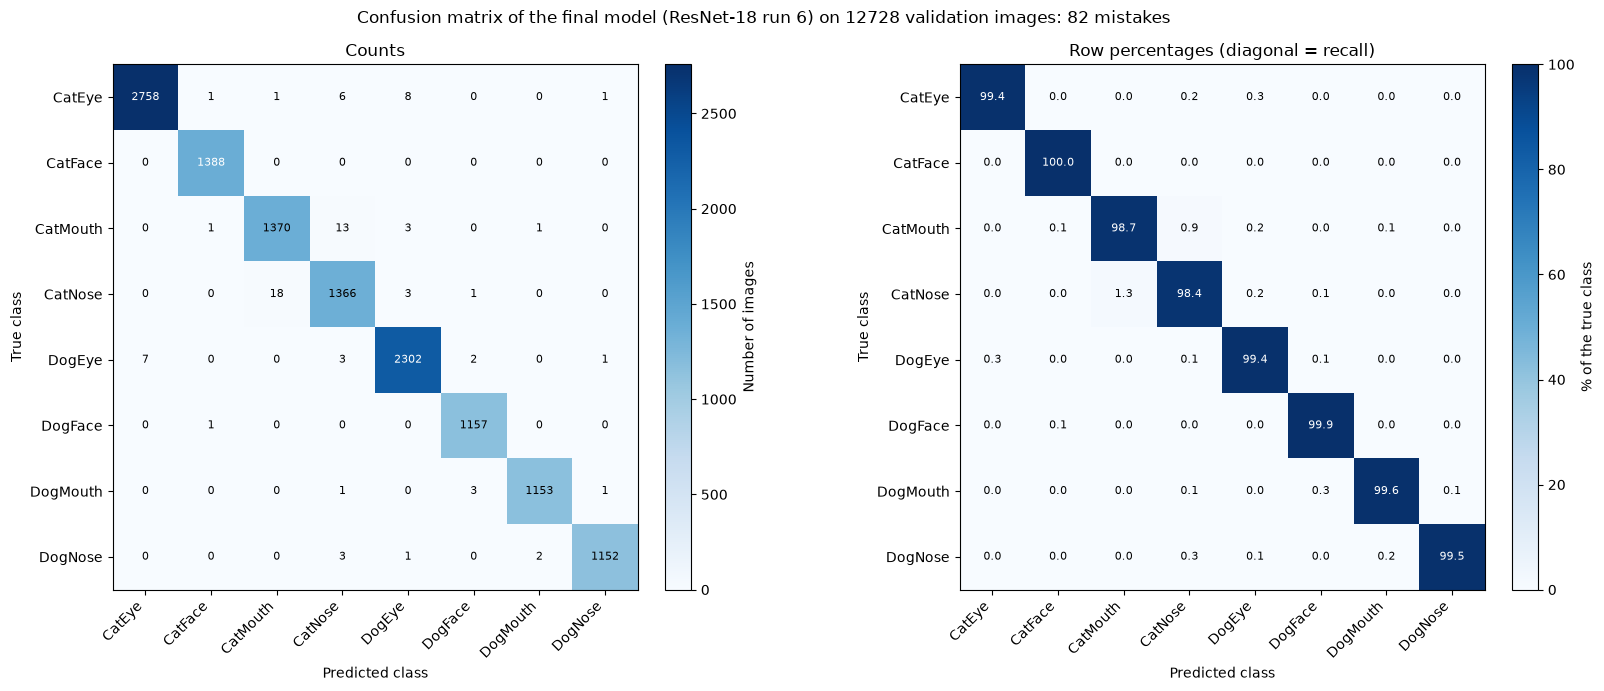

In [88]:
# Row percentages: each cell divided by its row total
final_confusion_percent = []
for true_index in range(len(CLASSES)):
    row_total = 0
    for count in final_confusion[true_index]:
        row_total += count
    percent_row = []
    for count in final_confusion[true_index]:
        percent_row.append(count / row_total * 100)
    final_confusion_percent.append(percent_row)

fig, (ax_counts, ax_percent) = plt.subplots(1, 2, figsize=(17, 7))
panels = [
    {"ax": ax_counts, "values": final_confusion, "title": "Counts", "colour_label": "Number of images", "number_format": "{:.0f}"},
    {"ax": ax_percent, "values": final_confusion_percent, "title": "Row percentages (diagonal = recall)", "colour_label": "% of the true class", "number_format": "{:.1f}"},
]
for panel in panels:
    ax = panel["ax"]
    values = np.array(panel["values"], dtype=float)                              # 8 x 8 array for imshow
    image = ax.imshow(values, cmap="Blues")                                      # White (low) to dark blue (high)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label=panel["colour_label"])
    highest = values.max()
    for true_index in range(len(CLASSES)):
        for predicted_index in range(len(CLASSES)):
            value = values[true_index][predicted_index]
            if value > highest * 0.5:
                text_colour = "white"                                            # White text on dark cells
            else:
                text_colour = "black"                                            # Black text on light cells
            ax.text(predicted_index, true_index, panel["number_format"].format(value),
                    ha="center", va="center", color=text_colour, fontsize=8)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(panel["title"])

plt.suptitle(f"Confusion matrix of the final model (ResNet-18 run 6) on {len(df_final_predictions)} validation images: "
             f"{len(df_final_predictions) - diagonal_total} mistakes")
plt.tight_layout()                                                               # Stop the panels overlapping
plt.savefig(figures_folder / "confusion_matrix_final.png", dpi=150, bbox_inches="tight")   # Save the figure for the report
plt.show()

### 5.2 Precision, recall and F1

The confusion matrix from 5.1 turned into a score per class. Accuracy treats every image the same, so with 8 classes of different sizes it can hide a weak class; precision, recall and F1 show how well each class is recognised on its own.

`per_class_metrics` works out, with plain arithmetic from a confusion matrix, each class's true positives, false positives, false negatives, precision, recall, F1-score and support (number of images). `average_metrics` then gives the macro average (the simple mean over the 8 classes, so every class counts equally) and the weighted average (each class weighted by its support, so big classes count more).

In [89]:
def per_class_metrics(confusion_matrix):
    """Return one dictionary per class (CLASSES order) with TP, FP, FN, precision, recall, F1 and support."""
    rows = []
    for k in range(len(CLASSES)):
        true_positives = confusion_matrix[k][k]                                  # Diagonal: class k predicted as class k

        column_total = 0                                                         # Everything predicted as class k
        for t in range(len(CLASSES)):
            column_total += confusion_matrix[t][k]
        false_positives = column_total - true_positives                          # Predicted as k, but really another class

        row_total = 0                                                            # Every image whose true class is k
        for p in range(len(CLASSES)):
            row_total += confusion_matrix[k][p]
        false_negatives = row_total - true_positives                             # Really k, but predicted as another class

        if true_positives + false_positives > 0:
            precision = true_positives / (true_positives + false_positives)
        else:
            precision = 0.0                                                      # Nothing was predicted as this class
        recall = true_positives / (true_positives + false_negatives)
        if precision + recall > 0:
            f1 = 2 * precision * recall / (precision + recall)
        else:
            f1 = 0.0

        row = {}
        row["class"] = CLASSES[k]
        row["true_positives"] = true_positives
        row["false_positives"] = false_positives
        row["false_negatives"] = false_negatives
        row["precision"] = precision
        row["recall"] = recall
        row["f1"] = f1
        row["support"] = row_total
        rows.append(row)
    return rows


def average_metrics(rows):
    """Return the macro average and the weighted average of precision, recall and F1 over the per-class rows."""
    total_support = 0
    for row in rows:
        total_support += row["support"]

    macro = {"class": "macro average", "support": total_support}
    weighted = {"class": "weighted average", "support": total_support}
    for metric in ["precision", "recall", "f1"]:
        metric_sum = 0.0
        weighted_sum = 0.0
        for row in rows:
            metric_sum += row[metric]
            weighted_sum += row[metric] * row["support"]
        macro[metric] = metric_sum / len(rows)                                   # Every class counts equally
        weighted[metric] = weighted_sum / total_support                          # Bigger classes count more
    return macro, weighted

The table for the final model, saved to `results/per_class_metrics_final.csv`. Weighted recall must equal the accuracy: it adds up each class's correct predictions and divides by all the images, which is exactly what accuracy does.

In [90]:
final_metric_rows = per_class_metrics(final_confusion)
final_macro, final_weighted = average_metrics(final_metric_rows)

print(f"{'Class':<17} {'TP':>5} {'FP':>4} {'FN':>4} {'Precision':>10} {'Recall':>8} {'F1':>8} {'Support':>8}")
for row in final_metric_rows:
    print(f"{row['class']:<17} {row['true_positives']:>5} {row['false_positives']:>4} {row['false_negatives']:>4} "
          f"{row['precision']:>10.4f} {row['recall']:>8.4f} {row['f1']:>8.4f} {row['support']:>8}")
for average in [final_macro, final_weighted]:
    print(f"{average['class']:<17} {'':>5} {'':>4} {'':>4} {average['precision']:>10.4f} {average['recall']:>8.4f} {average['f1']:>8.4f} {average['support']:>8}")

# Save the table (the average rows have no TP, FP or FN)
df_final_metrics = pd.DataFrame(final_metric_rows + [final_macro, final_weighted])
for column in ["true_positives", "false_positives", "false_negatives"]:
    df_final_metrics[column] = df_final_metrics[column].astype("Int64")          # Whole numbers, blank for the two average rows
df_final_metrics.to_csv(results_folder / "per_class_metrics_final.csv", index=False)
print("\nSaved", results_folder / "per_class_metrics_final.csv")

# Check: weighted recall equals the accuracy
final_accuracy = df_final_predictions["correct"].sum() / len(df_final_predictions)
print_check(f"weighted recall {final_weighted['recall'] * 100:.4f}% equals the accuracy {final_accuracy * 100:.4f}%",
            abs(final_weighted["recall"] - final_accuracy) < 1e-12)

Class                TP   FP   FN  Precision   Recall       F1  Support
CatEye             2758    7   17     0.9975   0.9939   0.9957     2775
CatFace            1388    3    0     0.9978   1.0000   0.9989     1388
CatMouth           1370   19   18     0.9863   0.9870   0.9867     1388
CatNose            1366   26   22     0.9813   0.9841   0.9827     1388
DogEye             2302   15   13     0.9935   0.9944   0.9940     2315
DogFace            1157    6    1     0.9948   0.9991   0.9970     1158
DogMouth           1153    3    5     0.9974   0.9957   0.9965     1158
DogNose            1152    3    6     0.9974   0.9948   0.9961     1158
macro average                         0.9933   0.9936   0.9934    12728
weighted average                      0.9936   0.9936   0.9936    12728

Saved results/per_class_metrics_final.csv
PASS: weighted recall 99.3558% equals the accuracy 99.3558%


A cross-check with scikit-learn's `classification_report`, which calculates the same metrics independently. If scikit-learn is not installed, this is skipped.

In [91]:
try:
    from sklearn.metrics import classification_report                           # Optional library, only used for this cross-check
    print(classification_report(df_final_predictions["true_class"], df_final_predictions["predicted_class"],
                                labels=CLASSES, digits=4))
except ImportError:
    print("scikit-learn is not installed, so the cross-check is skipped")

              precision    recall  f1-score   support

      CatEye     0.9975    0.9939    0.9957      2775
     CatFace     0.9978    1.0000    0.9989      1388
    CatMouth     0.9863    0.9870    0.9867      1388
     CatNose     0.9813    0.9841    0.9827      1388
      DogEye     0.9935    0.9944    0.9940      2315
     DogFace     0.9948    0.9991    0.9970      1158
    DogMouth     0.9974    0.9957    0.9965      1158
     DogNose     0.9974    0.9948    0.9961      1158

    accuracy                         0.9936     12728
   macro avg     0.9933    0.9936    0.9934     12728
weighted avg     0.9936    0.9936    0.9936     12728



**What each metric means, in plain words:**
- **Precision:** of all the images the model *called* this class, the share that really were this class. It drops when other classes are wrongly put into this one (false positives).
- **Recall:** of all the images that really *are* this class, the share the model found. It drops when images of this class are put somewhere else (false negatives). Recall is the same as that class's accuracy.
- **F1-score:** a single score that combines the two, the harmonic mean `2 x precision x recall / (precision + recall)`. It is only high when both precision and recall are high.
- **Support:** the number of validation images of the class.
- **Macro average:** the plain mean over the 8 classes, so a small class counts as much as a big one. **Weighted average:** each class weighted by its support, so it is pulled towards the big classes (CatEye and DogEye); weighted recall equals the overall accuracy.

**Worked example, CatNose (the weakest class):** the model got 1,366 cat noses right (true positives). 26 images that were not cat noses were called CatNose (false positives: 13 cat mouths, 6 cat eyes, 3 dog eyes, 3 dog noses and 1 dog mouth), and 22 real cat noses were called something else (false negatives: 18 cat mouths, 3 dog eyes and 1 dog face).
- Precision = 1366 / (1366 + 26) = 1366 / 1392 = 0.9813
- Recall = 1366 / (1366 + 22) = 1366 / 1388 = 0.9841
- F1 = 2 x 0.9813 x 0.9841 / (0.9813 + 0.9841) = 0.9827

Most of CatNose's errors in both directions involve CatMouth, probably because the nose and mouth sit right next to each other on a cat's face, so a crop of one can easily include part of the other.

### 5.3 Baseline vs final model

The baseline CNN's confusion matrix and per-class metrics, worked out with the same functions as the final model's (5.1, 5.2), side by side: recall and F1 for each class, the change in F1, and the overall accuracy and macro F1 of both models.

In [92]:
baseline_confusion = build_confusion_matrix(df_baseline_predictions)
baseline_metric_rows = per_class_metrics(baseline_confusion)
baseline_macro, baseline_weighted = average_metrics(baseline_metric_rows)

print(f"{'Class':<10} {'Baseline recall':>16} {'Final recall':>13} {'Baseline F1':>12} {'Final F1':>9} {'Change in F1':>13}")
for k in range(len(CLASSES)):
    baseline_row = baseline_metric_rows[k]                                       # Same class order (CLASSES) in both lists
    final_row = final_metric_rows[k]
    f1_change = (final_row["f1"] - baseline_row["f1"]) * 100                     # In percentage points
    print(f"{CLASSES[k]:<10} {baseline_row['recall'] * 100:>15.2f}% {final_row['recall'] * 100:>12.2f}% "
          f"{baseline_row['f1'] * 100:>11.2f}% {final_row['f1'] * 100:>8.2f}% {f1_change:>+12.2f}")

baseline_accuracy = df_baseline_predictions["correct"].sum() / len(df_baseline_predictions)
final_accuracy = df_final_predictions["correct"].sum() / len(df_final_predictions)
print()
print(f"{'Accuracy':<10} {baseline_accuracy * 100:>15.2f}% {final_accuracy * 100:>12.2f}%   (change {(final_accuracy - baseline_accuracy) * 100:+.2f} points)")
print(f"{'Macro F1':<10} {baseline_macro['f1'] * 100:>15.2f}% {final_macro['f1'] * 100:>12.2f}%   (change {(final_macro['f1'] - baseline_macro['f1']) * 100:+.2f} points)")
print(f"Wrong images: baseline {len(df_baseline_predictions) - int(df_baseline_predictions['correct'].sum())}, "
      f"final {len(df_final_predictions) - int(df_final_predictions['correct'].sum())}")
print()

# The baseline's largest mistakes, to compare with the final model's (below)
print("Baseline's largest mistakes (true -> predicted):")
baseline_mistakes = []
for true_index in range(len(CLASSES)):
    for predicted_index in range(len(CLASSES)):
        if true_index != predicted_index:
            baseline_mistakes.append({"true_class": CLASSES[true_index], "predicted_class": CLASSES[predicted_index],
                                      "count": baseline_confusion[true_index][predicted_index]})


def get_count(mistake):
    """Sort key: the number of images in a mistake."""
    return mistake["count"]


baseline_mistakes.sort(key=get_count, reverse=True)                              # Most images first
for mistake in baseline_mistakes[0:5]:
    print(f"  {mistake['true_class']} -> {mistake['predicted_class']}: {mistake['count']} "
          f"(final model: {final_confusion[class_to_index[mistake['true_class']]][class_to_index[mistake['predicted_class']]]})")

Class       Baseline recall  Final recall  Baseline F1  Final F1  Change in F1
CatEye               92.32%        99.39%       95.94%    99.57%        +3.63
CatFace              98.70%       100.00%       97.89%    99.89%        +2.00
CatMouth             94.96%        98.70%       94.55%    98.67%        +4.12
CatNose              90.92%        98.41%       92.90%    98.27%        +5.38
DogEye               96.46%        99.44%       94.74%    99.40%        +4.66
DogFace              98.62%        99.91%       96.05%    99.70%        +3.65
DogMouth             96.29%        99.57%       97.38%    99.65%        +2.27
DogNose              99.22%        99.48%       94.61%    99.61%        +5.00

Accuracy             95.47%        99.36%   (change +3.89 points)
Macro F1             95.51%        99.34%   (change +3.84 points)
Wrong images: baseline 577, final 82

Baseline's largest mistakes (true -> predicted):
  CatEye -> DogEye: 138 (final model: 8)
  CatNose -> CatMouth: 70 (final mod

**What changed from the baseline to the final model:**
- **Every class improved.** Accuracy rose from 95.47% to 99.36% and macro F1 from 95.51% to 99.34%, and the number of wrong validation images fell from 577 to 82.
- **The small facial parts improved most:** CatNose (+5.38 points of F1, from 92.90% to 98.27%), DogNose (+5.00), DogEye (+4.66) and CatMouth (+4.12). The faces, which the baseline already recognised well (recall 98.6-98.7%), gained least (CatFace +2.00, DogFace +3.65).
- **Why this might be:** the baseline's largest mistake was 138 cat eyes predicted as dog eyes (5.0% of CatEye), against 8 for the final model. A close-up eye or nose carries few clues about the animal, and ResNet-18's ImageNet pretraining (ImageNet includes many cat and dog breeds) gives it fine texture and shape features that a small CNN trained from scratch for 10 epochs does not learn. Resolution is not the main reason: in 4.2, ResNet-18 at the baseline's own 64 px still reached 98.92%, far above the baseline's 95.47%.
- **DogNose is a precision story:** the baseline already found 99.22% of dog noses, but it also called many eyes noses (44 dog eyes and 38 cat eyes), so its precision and F1 were low. The final model makes almost none of these mistakes.
- **Cat nose vs cat mouth is the hardest pair for both models** (baseline 70 + 34 images, final 18 + 13), which fits the nose being visible in mouth crops (see below).

**How big a difference is:** each class has between 1,158 and 2,775 validation images, so one image is worth roughly 0.04-0.09 points of recall (1 / 2,775 = 0.036 and 1 / 1,158 = 0.086). The F1 gains of 2.0 to 5.4 points per class correspond to tens to hundreds of images, so they are real (DogNose's recall itself changed by only 0.26 points, 3 images: its gain was in precision); differences of a few tenths of a point between classes of the final model are only a handful of images.

#### Most common mistakes of the final model

Every off-diagonal cell of the final model's confusion matrix (5.1) is one kind of mistake. They are collected into a list of dictionaries with a loop, sorted from most to fewest images (with `get_count` from the cell above), and the five largest are listed with their share of the true class.

In [93]:
# Every off-diagonal cell: one kind of mistake (true class -> predicted class)
mistakes = []
for true_index in range(len(CLASSES)):
    class_total = 0
    for count in final_confusion[true_index]:
        class_total += count                                                     # Validation images of this true class
    for predicted_index in range(len(CLASSES)):
        if true_index != predicted_index and final_confusion[true_index][predicted_index] > 0:
            mistake = {}
            mistake["true_class"] = CLASSES[true_index]
            mistake["predicted_class"] = CLASSES[predicted_index]
            mistake["count"] = final_confusion[true_index][predicted_index]
            mistake["share"] = mistake["count"] / class_total                    # Share of that true class
            mistakes.append(mistake)

mistakes.sort(key=get_count, reverse=True)                                       # Most images first (get_count is defined in the cell above)

total_mistakes = 0
for mistake in mistakes:
    total_mistakes += mistake["count"]
print(f"{len(mistakes)} different kinds of mistake, {total_mistakes} wrong images in total. The five largest:")
for mistake in mistakes[0:5]:
    print(f"  {mistake['true_class']} -> {mistake['predicted_class']}: {mistake['count']} ({mistake['share'] * 100:.1f}% of {mistake['true_class']})")

23 different kinds of mistake, 82 wrong images in total. The five largest:
  CatNose -> CatMouth: 18 (1.3% of CatNose)
  CatMouth -> CatNose: 13 (0.9% of CatMouth)
  CatEye -> DogEye: 8 (0.3% of CatEye)
  DogEye -> CatEye: 7 (0.3% of DogEye)
  CatEye -> CatNose: 6 (0.2% of CatEye)


To see what kind of mistakes these are, each wrong image is put into one of three groups using the class names (the first 3 letters are the animal, the rest is the facial part): **same animal, different part** (for example CatNose -> CatMouth), **cat vs dog, same part** (for example CatEye -> DogEye), or **different animal and part**. The size and sharpness of the wrong images are then compared with the correct ones, using the shorter side from `df_info` and the sharpness from section 1.6, with Task 1's limits for "small" (`SMALL_IMAGE_SIZE`) and "blurry" (`BLUR_THRESHOLD`).

In [94]:
# Mistakes by type
type_counts = {"same animal, different part": 0, "cat vs dog, same part": 0, "different animal and part": 0}
for mistake in mistakes:
    true_animal = mistake["true_class"][0:3]                                     # "Cat" or "Dog"
    true_part = mistake["true_class"][3:]                                        # "Eye", "Face", "Mouth" or "Nose"
    predicted_animal = mistake["predicted_class"][0:3]
    predicted_part = mistake["predicted_class"][3:]
    if true_animal == predicted_animal:
        type_counts["same animal, different part"] += mistake["count"]
    elif true_part == predicted_part:
        type_counts["cat vs dog, same part"] += mistake["count"]
    else:
        type_counts["different animal and part"] += mistake["count"]

print("Mistakes by type:")
for mistake_type in type_counts:
    print(f"  {mistake_type:<29} {type_counts[mistake_type]:>3} ({type_counts[mistake_type] / total_mistakes * 100:.0f}%)")
print()

# Size and sharpness of the wrong images compared with the correct ones
sharpness_of_image = {}                                                          # Image ID -> sharpness (validation images are training images)
df_train_rows = df_info[df_info["split"] == "train"]
for image_id, sharpness in zip(df_train_rows["image_id"], df_train_rows["sharpness"]):
    sharpness_of_image[int(image_id)] = sharpness

groups = {"Wrong": df_final_predictions[df_final_predictions["correct"] == False],
          "Correct": df_final_predictions[df_final_predictions["correct"] == True]}
print(f"{'':<8} {'Images':>7} {'Median shorter side':>20} {'Small (< 32 px)':>16} {'Median sharpness':>17} {'Blurry (< 20)':>14} {'Mean confidence':>16}")
for group_name in groups:
    df_group = groups[group_name]
    sharpness_values = []
    for image_id in df_group["image_id"]:
        sharpness_values.append(sharpness_of_image[int(image_id)])
    n_small = int((df_group["short_side"] < SMALL_IMAGE_SIZE).sum())
    n_blurry = 0
    for value in sharpness_values:
        if value < BLUR_THRESHOLD:
            n_blurry += 1
    print(f"{group_name:<8} {len(df_group):>7} {df_group['short_side'].median():>17.0f} px {n_small / len(df_group) * 100:>15.1f}% "
          f"{np.median(sharpness_values):>17.0f} {n_blurry / len(df_group) * 100:>13.1f}% {df_group['confidence'].mean():>16.3f}")

# The largest mistake: cat noses predicted as cat mouths, compared with all cat noses
df_cat_noses = df_final_predictions[df_final_predictions["true_class"] == "CatNose"]
df_noses_as_mouths = df_cat_noses[df_cat_noses["predicted_class"] == "CatMouth"]
print()
print(f"CatNose -> CatMouth: median shorter side {df_noses_as_mouths['short_side'].median():.0f} px ({len(df_noses_as_mouths)} images); "
      f"all cat noses: {df_cat_noses['short_side'].median():.0f} px")

Mistakes by type:
  same animal, different part    50 (61%)
  cat vs dog, same part          20 (24%)
  different animal and part      12 (15%)

          Images  Median shorter side  Small (< 32 px)  Median sharpness  Blurry (< 20)  Mean confidence
Wrong         82                56 px            18.3%               216          14.6%            0.762
Correct    12646                78 px             6.4%               493           1.2%            0.995

CatNose -> CatMouth: median shorter side 99 px (18 images); all cat noses: 68 px


**What the mistakes show:**
- **Mostly the same animal, a neighbouring part.** 50 of the 82 wrong images (61%) were given the right animal but the wrong part, and the two largest mistakes are cat nose and cat mouth swapped both ways (CatNose -> CatMouth 18, CatMouth -> CatNose 13, together 38% of all mistakes). This connects to Task 1's sample images (1.4): every CatMouth and DogMouth crop also shows the nose just above the mouth, so the two classes share much of their content and the boundary between them is not sharp. The cat noses mistaken for mouths are in fact larger than usual (median shorter side 99 px for those 18, against 68 px for all cat noses), which fits wider nose crops that take in the mouth below.
- **Cat vs dog for the same part is the second group:** 20 wrong images (24%), mostly eyes (CatEye -> DogEye 8 and DogEye -> CatEye 7), plus 3 dog noses called cat noses. A close-up eye or nose shows little of the fur or face shape that tells cats and dogs apart. The other 12 (15%) differ in both animal and part.
- **Small, blurry images are much harder.** The wrong images have a median shorter side of 56 px against 78 px for the correct ones, 18.3% of them are under 32 px (against 6.4%), and 14.6% are blurry (against 1.2%), with a median sharpness of 216 against 493. Task 1 (1.5, 1.6) found that eyes and noses are the smallest crops (about 10% of CatEye and CatNose images are under 32 px) and that DogEye, CatNose and DogNose are the least sharp classes, while faces are large and sharp; in line with that, the face classes have almost no mistakes (CatFace none, DogFace 1).
- **The model knows when it is unsure:** its average confidence is 0.995 on correct predictions but 0.762 on wrong ones, so most mistakes are low-confidence guesses on hard images rather than confident errors.

### 5.4 Kaggle submissions and evidence

**Kaggle username:** KAGGLE_USERNAME

Every submission made to the competition, with its public leaderboard score (the scores are the ones recorded in `KAGGLE_SCORES` and `BASELINE_KAGGLE_SCORE` in 4.1). Runs 1 and 6 are the two submissions selected for the final leaderboard. All four passed the format checks before they were submitted: 29,443 rows, the same image IDs as `sample_submission.csv`, valid class names and the columns `image_id, class` (3.7, 3.9, 4.6).

| File | Model | Short description | Public score | Selected for the final leaderboard |
|---|---|---|---|---|
| `submissions/submission_baseline.csv` | Baseline CNN | Custom 4-block CNN, 64 px, 10 epochs on the laptop CPU (3.5) | 0.9338 | no |
| `submissions/submission_resnet18_128px-imgsize.csv` | ResNet-18, run 1 | Pretrained, 128 px, 3 frozen + 7 fine-tuning epochs, augmentation on (3.9) | 0.9728 | **yes** |
| `submissions/submission_resnet18_final.csv` | ResNet-18, run 6 (final model) | Same as run 1 with 17 fine-tuning epochs; best checkpoint at epoch 17 (4.6) | **0.9747** | **yes** |
| `kaggle_notebooks/resnet-18_results_run8_128px-noaug/submissions/submission_resnet-18_run8.csv` | ResNet-18, run 8 | Same as run 1 without augmentation (augmentation ablation, 4.4) | 0.9696 | no |

**Public and private leaderboard:** the public leaderboard is calculated on only part of the test set; the final ranking uses the private part, which is kept hidden until the competition ends. A public score is therefore an estimate of the final score, and small differences between submissions (such as 0.9747 against 0.9728) may change on the private part. This is one reason the final model was chosen on validation accuracy rather than on the public score (4.6).

**Evidence:** the screenshots are saved in `evidence/`: `kaggle_my_submissions.png` (every submission, with runs 1 and 6 selected) and `kaggle_leaderboard.png` (my row on the leaderboard, with username and score). The cell below shows them.

In [95]:
EVIDENCE_FOLDER = Path("evidence")                                               # Screenshots from the Kaggle website
EVIDENCE_SCREENSHOTS = [
    {"file": EVIDENCE_FOLDER / "kaggle_my_submissions.png", "title": "My submissions (runs 1 and 6 selected for the final leaderboard)"},
    {"file": EVIDENCE_FOLDER / "kaggle_leaderboard.png", "title": "Leaderboard: my row with username and score"},
]

for screenshot in EVIDENCE_SCREENSHOTS:
    if screenshot["file"].exists():
        screenshot_image = Image.open(screenshot["file"])                        # Load the saved screenshot
        plt.figure(figsize=(12, 12 * screenshot_image.height / screenshot_image.width))   # Keep the screenshot's shape
        plt.imshow(screenshot_image)
        plt.axis("off")                                                          # A screenshot needs no axes
        plt.title(screenshot["title"])
        plt.show()
    else:
        print(f"Not found: {screenshot['file']} (save the screenshot there, then run this cell again)")

Not found: evidence/kaggle_my_submissions.png (save the screenshot there, then run this cell again)
Not found: evidence/kaggle_leaderboard.png (save the screenshot there, then run this cell again)


### 5.5 Validation vs Kaggle performance

Every submitted model scores about 2 points lower on the Kaggle public leaderboard than on the validation set. First the gap for each model (the same numbers as in 4.4), then the parts of the gap that can be measured.

In [96]:
print(f"{'Model':<36} {'Best val acc':>12} {'Kaggle':>8} {'Gap (val - Kaggle)':>19}")
baseline_best = df_baseline_history["validation_accuracy"].max() * 100           # Baseline CNN, section 3.5
print(f"{'Baseline CNN':<36} {baseline_best:>11.2f}% {BASELINE_KAGGLE_SCORE * 100:>7.2f}% {baseline_best - BASELINE_KAGGLE_SCORE * 100:>18.2f}")
for run_number in KAGGLE_COMPARISON_RUNS:                                        # Runs 1, 6 and 8 (4.4)
    run_summary = summarise_run(run_histories[run_number])
    best_accuracy = run_summary["best_val_accuracy"] * 100
    kaggle_percent = KAGGLE_SCORES[run_number] * 100
    for run in RUNS:
        if run["run"] == run_number:
            this_run = run
    if this_run["augmentation"]:
        augmentation_text = "augmentation"
    else:
        augmentation_text = "no augmentation"
    label = f"Run {run_number}: {this_run['image_size']} px, {this_run['frozen_epochs']}+{this_run['fine_tune_epochs']}, {augmentation_text}"
    print(f"{label:<36} {best_accuracy:>11.2f}% {kaggle_percent:>7.2f}% {best_accuracy - kaggle_percent:>18.2f}")
print("Gap in percentage points.")

Model                                Best val acc   Kaggle  Gap (val - Kaggle)
Baseline CNN                               95.47%   93.38%               2.09
Run 1: 128 px, 3+7, augmentation           99.21%   97.28%               1.93
Run 6: 128 px, 3+17, augmentation          99.36%   97.47%               1.89
Run 8: 128 px, 3+7, no augmentation        99.29%   96.96%               2.33
Gap in percentage points.


**Do the test set's extra small images explain the gap?** Task 1 found more small images (shorter side under `SMALL_IMAGE_SIZE` = 32 px) in the test set than in training. Using the final model's validation predictions, the accuracy on small and other images is worked out separately; the test accuracy is then estimated as if only the share of small images had changed: small accuracy x test small share + other accuracy x (1 - test small share).

In [97]:
df_small = df_final_predictions[df_final_predictions["short_side"] < SMALL_IMAGE_SIZE]     # Validation images under 32 px
df_other = df_final_predictions[df_final_predictions["short_side"] >= SMALL_IMAGE_SIZE]    # All the rest
small_accuracy = df_small["correct"].sum() / len(df_small)
other_accuracy = df_other["correct"].sum() / len(df_other)
validation_accuracy = df_final_predictions["correct"].sum() / len(df_final_predictions)

validation_small_share = len(df_small) / len(df_final_predictions)
test_small_share = (df_test_info["short_side"] < SMALL_IMAGE_SIZE).sum() / len(df_test_info)

estimated_test_accuracy = small_accuracy * test_small_share + other_accuracy * (1 - test_small_share)
final_kaggle_score = KAGGLE_SCORES[FINAL_RUN]                                    # 0.9747
total_gap = validation_accuracy - final_kaggle_score
explained_gap = validation_accuracy - estimated_test_accuracy

print(f"Small images (< {SMALL_IMAGE_SIZE} px): {len(df_small):>6} validation images, accuracy {small_accuracy * 100:.2f}% ({int(df_small['correct'].sum())} correct)")
print(f"Other images:          {len(df_other):>6} validation images, accuracy {other_accuracy * 100:.2f}%")
print()
print(f"Share of small images: validation {validation_small_share * 100:.2f}% | test {test_small_share * 100:.2f}% "
      f"({int((df_test_info['short_side'] < SMALL_IMAGE_SIZE).sum())} of {len(df_test_info)})")
print()
print(f"{'Validation accuracy:':<58} {validation_accuracy * 100:.3f}%")
print(f"{'Estimated test accuracy (only the small share changed):':<58} {estimated_test_accuracy * 100:.3f}%")
print(f"{'Actual Kaggle public score:':<58} {final_kaggle_score * 100:.3f}%")
print(f"Gap explained by the extra small images: {explained_gap * 100:.3f} of {total_gap * 100:.3f} points ({explained_gap / total_gap * 100:.1f}% of the gap)")

Small images (< 32 px):    824 validation images, accuracy 98.18% (809 correct)
Other images:           11904 validation images, accuracy 99.44%

Share of small images: validation 6.47% | test 8.23% (2422 of 29443)

Validation accuracy:                                       99.356%
Estimated test accuracy (only the small share changed):    99.334%
Actual Kaggle public score:                                97.470%
Gap explained by the extra small images: 0.022 of 1.886 points (1.2% of the gap)


Two more parts of the gap can be put into numbers: how optimistic it is to pick the best epoch by validation accuracy (compared with run 6's average over its last 10 epochs), and how much a public score that uses only part of the test set can vary by chance. Kaggle does not say how large the public part is, so its standard error is shown for public parts of 20% to 50% of the 29,443 test images.

In [98]:
df_run6 = run_histories[FINAL_RUN]
best_validation = df_run6["validation_accuracy"].max()                           # The chosen checkpoint (epoch 17)
df_last_10 = df_run6[df_run6["epoch"] > 10]                                      # Epochs 11-20, after validation accuracy levelled off
mean_last_10 = df_last_10["validation_accuracy"].mean()
print(f"Run 6 best validation accuracy: {best_validation * 100:.2f}% | average over epochs 11-20: {mean_last_10 * 100:.2f}% "
      f"| optimism of picking the best epoch: {(best_validation - mean_last_10) * 100:.2f} points")
print()

print("Chance variation of the public score (standard error of an accuracy near 97.5%):")
for public_fraction in [0.2, 0.3, 0.5]:
    public_images = public_fraction * len(df_test_info)
    standard_error = (final_kaggle_score * (1 - final_kaggle_score) / public_images) ** 0.5   # sqrt(p x (1 - p) / n)
    print(f"  public part {public_fraction * 100:.0f}% ({public_images:.0f} images): ±{standard_error * 100:.2f} points")

Run 6 best validation accuracy: 99.36% | average over epochs 11-20: 99.12% | optimism of picking the best epoch: 0.23 points

Chance variation of the public score (standard error of an accuracy near 97.5%):
  public part 20% (5889 images): ±0.20 points
  public part 30% (8833 images): ±0.17 points
  public part 50% (14722 images): ±0.13 points


**Why the Kaggle score is about 1.9 points below validation accuracy, in order of likely size:**

1. **Crops of the same animal in both the training and validation splits (probably the largest part; it cannot be measured).** The split in 2.2 was random per image within each class. One animal photo is likely to give several crops (its eyes, nose, mouth and face), so crops of the same animal, and possibly the same photo, can end up in both the training and the validation set. The model can then partly recognise an individual animal's fur colour and texture, which makes the validation score optimistic; if the test images come from other animals, that help disappears. The dataset has no animal or photo ID, so this cannot be measured directly (2.1 only removed exact duplicate files). The evidence is indirect: every model shows a similar gap (1.9 to 2.3 points, the baseline included), and run 8, which without augmentation fits the individual training images most closely (4.4), has the largest gap (2.33 points against 1.93 for run 1).
2. **Choosing the best epoch on the validation set (about 0.2 points).** The final checkpoint is the best of 20 epochs, chosen by validation accuracy, so its 99.36% includes some luck: run 6 averaged 99.12% over epochs 11-20, 0.23 points below its best. The test set gets no such choice.
3. **The public leaderboard covers only part of the test set (random, about ±0.1 to 0.2 points).** If the public part is 20-50% of the test images, the public score varies by chance by about 0.13-0.20 points (one standard error). This can go either way, so it cannot explain why all four models score about 2 points lower; it does mean the private leaderboard may differ a little.
4. **More small images in the test set (0.02 points).** The test set has 8.23% small images against 6.47% in validation, but the final model loses only 1.3 points on small images (98.18% against 99.44%), so the different mix explains about 1% of the gap.

Causes 2 and 4 together explain only about 0.25 of the 1.89 points, and cause 3 adds random variation but no steady drop. That leaves most of the gap to the first cause, or to other differences between the test images and the training images that cannot be seen in the image statistics: Task 1 (1.7) found the test set matches training in size, brightness, sharpness and greyscale share, apart from the small images. A split that keeps all crops of one animal together (a grouped split) would test the first cause, but it needs animal or photo IDs that the dataset does not provide.

### 5.6 Summary

- **Validation accuracy and loss:** the final model (ResNet-18, run 6, epoch 17) classifies 12,646 of the 12,728 validation images correctly: **99.36% accuracy, loss 0.0220**. This exactly matches its training run on the Kaggle GPU (0 images different), so the saved weights are the right checkpoint and the laptop CPU gives the same predictions. The baseline CNN reproduces its training run too: 95.47%, loss 0.1310 (Task 5 evaluation cells; `results/validation_predictions_final.csv`, `results/validation_loss_final.csv`).
- **Precision, recall and F1:** macro F1 is 0.9934 and weighted F1 0.9936, so no class is hidden by the averages. The weakest classes are **CatNose** (F1 0.9827: precision 0.9813, recall 0.9841) and **CatMouth** (F1 0.9867); the strongest is **CatFace** (F1 0.9989, recall 100%) (5.2, `results/per_class_metrics_final.csv`).
- **Confusion matrix:** 82 mistakes in total. The main mix-ups are cat nose and cat mouth swapped both ways (18 + 13 images, 38% of all mistakes) and cat eye vs dog eye (8 + 7); 61% of mistakes keep the right animal but pick a neighbouring part. The wrong images are smaller (median shorter side 56 px against 78 px) and far more often blurry (14.6% against 1.2%) than the correct ones (5.1, `figures/confusion_matrix_final.png`; 5.3, most common mistakes).
- **Baseline vs final model:** accuracy rose from 95.47% to 99.36% and macro F1 from 95.51% to 99.34%, with wrong images falling from 577 to 82. Every class improved; the small parts most (CatNose +5.38 points of F1, DogNose +5.00), and the baseline's largest mistake, 138 cat eyes called dog eyes, fell to 8 (5.3).
- **Submission format:** every submission file passed the same four checks before it was uploaded: 29,443 rows, the same image IDs as `sample_submission.csv`, only valid class names, and the columns `image_id, class` (3.7, 3.9, 4.6).
- **Kaggle scores and evidence:** public scores are **0.9747 for the final model (run 6)** and 0.9728 for run 1, the two submissions selected for the final leaderboard, then 0.9696 for run 8 (no augmentation) and 0.9338 for the baseline. Screenshots of the submissions and the leaderboard are in `evidence/` (5.4).
- **Validation vs Kaggle:** every model scores about 1.9-2.3 points lower on Kaggle than on validation (final model 99.36% against 97.47%). The test set's extra small images explain only 0.02 points of the 1.89-point gap and picking the best epoch about 0.23 points, while the partial public leaderboard adds random variation of about ±0.1-0.2 points. Most of the gap is probably crops of the same animal in both the training and validation splits, which makes validation optimistic but cannot be measured without animal or photo IDs (5.5).